# Lab 1, teaching version: a simple EEG preprocessing pipeline, step by step
### Lexical decision while walking (Brain Walk project), participant P010

**PSY2007D, 2026.** This notebook teaches the basic steps of EEG preprocessing on real data: one participant doing a lexical
decision task while walking on a treadmill, and one recording of walking without the task.

**The task.** A string of letters appears for 100 ms at the centre of a tablet. The participant decides as fast as possible whether it is
a French word, and taps one side of the screen for "word" and the other side for "not a word". There are three kinds of strings:

- **HF**: high-frequency words, which are familiar (e.g. *excès*)
- **LF**: low-frequency words, which are rarer (e.g. *lièvre*)
- **pseudoword**: strings that follow French spelling rules but are not words (e.g. *assous*)

The participant did 4 blocks of 100 trials while walking (25 HF, 25 LF and 50 pseudowords per block, a new string every 2 to 3 s).

**The EEG.** A DSI-24 headset with dry electrodes (no gel): 19 electrodes, 300 samples per second (300 Hz).

**This version: tuned for walking.** It starts from the seated notebook (`00_preprocessing_teaching_seated.ipynb`) and changes what
walking needs, following the studies of mobile EEG (mobile brain/body imaging, MoBI) and the Brain Walk analyses of the COSYNE abstract:
the bad channels are judged over time (step 2), the movement of the head is regressed out with the accelerometer of the headset (step 4),
ICA is AMICA (steps 5 and 6), what repeats at every stride is subtracted after ICA (step 7), and epochs above 300 µV are dropped
(step 9).

## How to use this notebook

Run the cells in order (Shift+Enter). AMICA (cell 6.2) takes about 2 minutes.

| Step | What | Main function |
|---|---|---|
| 1 | Load and look at the data | `mne.io.read_raw_brainvision` |
| 2 | Find the bad channels over time, and the suspicious periods | a robust amplitude in 5-s windows, `raw.info['bads']`, `QC_` annotations |
| 3 | Filter | `raw.filter` |
| 4 | Re-reference to the average, then remove the head movement | `raw.set_eeg_reference`, a regression on the head accelerometer |
| 5 | Prepare the data used to train ICA | `raw.filter`, `BAD_ICA_` annotations |
| 6 | AMICA: find the eye, muscle and single-electrode components | `jamica.fit_ica`, ICLabel, `ica.find_bads_eog` |
| 7 | Remove those components, then what repeats at every stride | `ica.apply`, a stride template (Gwin et al., 2010) |
| 8 | Check the data after ICA, mark what stays unusable | `BAD_final_` annotations |
| 9 | Epochs and ERPs, before and after cleaning | `mne.Epochs`, `mne.viz.plot_compare_evokeds` |

## 0. Setup

In [1]:
# ---- 0.1 The data and the packages: downloaded once, into tasks/brainwalk next to the notebook ----------------------------------
import sys                                                   # to know whether the notebook runs in Google Colab
import zipfile                                               # to unzip the data
import urllib.request                                        # to download the data
import importlib.util                                        # to check which packages are installed
from pathlib import Path                                     # to write file paths
import hashlib                                               # to recognize the version of the data

# The packages this notebook needs (import name: name to install). The missing ones are installed the first time.
PACKAGES = {'mne': 'mne', 'mne_icalabel': 'mne-icalabel', 'onnxruntime': 'onnxruntime',
            'jamica': 'jamica', 'jax': 'jax'}                # jamica: AMICA in Python (step 6), which runs on JAX
missing = [name for module, name in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    to_install = ' '.join(missing)
    print('Installing', to_install, '(about one minute)')
    %pip install -q {to_install}

DATA_DIR = Path('tasks/brainwalk')                           # do not change: the data, in tasks/ next to the notebook
DRIVE_ID = '19nnPiRuypz5fCPISybipdjxeop2EA_P8'               # do not change: the file labo1_donnees_2026.zip on Google Drive
FINGERPRINT = 'b1bb8546761ec47c'                             # do not change: the fingerprint of manifest.json in this version of the data


def data_up_to_date():
    """True if DATA_DIR contains this version of the data (the fingerprint of its manifest.json file)."""
    manifest = DATA_DIR / 'manifest.json'
    return manifest.exists() and hashlib.sha256(manifest.read_bytes()).hexdigest()[:16] == FINGERPRINT


def progress(blocks, block_size, total):
    """Prints the progress of the download, every 10 %."""
    if total > 0 and blocks * block_size * 10 // total > (blocks - 1) * block_size * 10 // total:
        print(f'  {min(100, 100 * blocks * block_size // total)} %')


if not data_up_to_date():                                    # missing, or an older version: we download them (1.2 GB)
    archive = DATA_DIR.parent / 'labo1_donnees_2026.zip'
    archive.parent.mkdir(parents=True, exist_ok=True)
    print('Downloading the data from Google Drive (1.2 GB, a few minutes):')
    urllib.request.urlretrieve(f'https://drive.usercontent.google.com/download?id={DRIVE_ID}&export=download&confirm=t', archive, progress)
    if not zipfile.is_zipfile(archive):                      # Google Drive sent a web page instead of the file
        archive.unlink()
        raise RuntimeError('Google Drive did not send the data (too many downloads today?). Try again later.')
    with zipfile.ZipFile(archive) as z:
        z.extractall(DATA_DIR.parent)                        # creates tasks/brainwalk/
    archive.unlink()                                         # the zip is no longer needed
print('Data:', DATA_DIR, '(ready)' if data_up_to_date() else '(NOT FOUND: rerun this cell)')

Data: tasks\brainwalk (ready)


In [2]:
# ---- 0.2 The tools -----------------------------------------------------------------------------------------------------------------
import json                                                  # to save a summary of the results
import time                                                  # to time AMICA
import numpy as np                                           # arrays and maths
import pandas as pd                                          # tables
import matplotlib.pyplot as plt                              # figures
from matplotlib import animation                             # animated figures
from matplotlib.patches import FancyBboxPatch                # the boxes of the pipeline map
from scipy.stats import kurtosis                             # used by the ICA demonstration (step 6)
from scipy.signal import find_peaks                          # the steps and the blinks (step 4)
from IPython.display import HTML, display                    # to show tables and animations in the notebook
import mne                                                   # MNE-Python: the EEG toolbox
from mne_icalabel.iclabel import iclabel_label_components    # ICLabel: what kind of source is each ICA component?
from jamica import fit_ica                                   # AMICA, the ICA of most mobile EEG studies (step 6)

%matplotlib inline
mne.set_log_level('ERROR')                                   # MNE prints only errors (try 'INFO' to see what each function does)
mne.viz.set_browser_backend('matplotlib')                    # raw.plot() draws a picture inside the notebook
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False, 'animation.embed_limit': 40})
import mne_icalabel, jamica, jax
for module in (mne, mne_icalabel, jamica, jax, np):
    print(f'{module.__name__:13s} {module.__version__}')

mne           1.13.2
mne_icalabel  0.10.0
jamica        0.3.0
jax           0.12.0.1
numpy         2.5.3


In [3]:
# ---- 0.3 The parameters we use in the pipeline --------------------------------------------------------------

SUBJECT = 'P010'                 # the participant whose data we analyze (P001, P002, ..., P010)
# Step 2: bad channels, with the rules of mobile EEG studies (cell 2.4)
FLAT_RATIO = 0.1                 # flat: below this × the typical amplitude (the median across channels), on the signal as recorded
FLAT_SD_UV = 1.0                 # a channel is also flat if its standard deviation is below this (µV): the rule of cell 1.2 and of NEAR
NOISY_RATIO = 3.0                # too large: above this × the typical amplitude of its 5-s window (Gonsisko et al., 2023)
NOISY_SHARE = 0.5                # noisy: too large in more than this share of the windows of all the walking recordings (Klug et al.,
                                 # 2024; BeMoBIL recommends 0.2, strict, to 0.5, lax: Klug et al., 2022)
MAX_BAD = 3                      # more bad channels than this (one fifth of the 18 recorded, as in BeMoBIL): look at the recordings first
QC_WINDOW_S = 5.0                # the windows of the quality check (s; cells 2.4, 2.5 and 8.1)
QC_RATIO = 3.0                   # suspicious: a channel above this × the typical amplitude of its window, or a window above this ×
                                 # the typical window of its recording (QC annotation, cell 2.5); a channel below FLAT_RATIO: lost contact

# Step 3: the filter (Hz)
ANALYSIS_BAND = (0.1, 100.0)     # the data we analyze: keeps the slow ERPs (N400, late positivity) and the muscle activity ICLabel needs

# Step 4: the blinks, and the movement of the head (cells 4.2 to 4.5)
BLINK_Z = 5.0                    # a blink: Fp1 and Fp2 both above their median by this many robust standard deviations
ACCEL_BAND = (0.5, 12.0)         # the band of the head acceleration we use (Hz); the accelerometer gives 30 samples per second
ACCEL_LAGS_S = np.arange(0, 0.21, 0.02)   # the acceleration now and up to 200 ms before (s): an artifact follows the movement
ACCEL_WINDOW_S = 60.0            # one regression per minute, half overlapping: the way the head moves the electrodes drifts
ACCEL_ALPHAS = (0.01, 0.1, 1.0, 10.0)   # the ridge penalties tried; the one that best predicts held-out data is kept
ACCEL_MIN_GAIN = 0.02            # the regression is applied to a recording only if it explains this share of held-out data

# Step 5: the two copies of the data that ICA uses (Hz)
ICA_BAND = (2.5, 100.0)          # AMICA's copy: the pass band starts at 2.5 Hz and the transition is ICA_L_TRANS wide, so half the
ICA_L_TRANS = 1.0                # amplitude is left at 2 Hz (Klug & Gramann, 2021: up to 2 Hz for mobile data)
ICLABEL_BAND = (1.0, 100.0)      # ICLabel's copy: the band ICLabel was trained on

# Step 6: AMICA, and the decision (cell 6.7)
AMICA_MAX_ITER = 500             # iterations: Klug et al. (2024) used 2000; for P010, 2000 remove the same components (Try it yourself, 6)
AMICA_DECIM = 2                  # AMICA learns from one sample in 2: still about 19 times the rule of thumb (cell 5.2), twice as fast
AMICA_REJECT = dict(do_reject=True, rejsig=3.0, numrej=10, rejstart=2, rejint=3)   # AMICA's own rejection of the samples it
                                 # cannot explain: 10 passes at 3 SD, every 3 iterations from the 2nd (Klug et al., 2024)
ICA_SEED = 97                    # fixes the random start, so AMICA gives the same result every time
EYE_P = 0.6                      # eye: ICLabel gives "eye" at least this probability, or ...
EYE_CORR = 0.4                   # ... "eye" is ICLabel's first choice and the component follows an eye proxy with |r| at least this
MUSCLE_P = 0.5                   # muscle: ICLabel gives "muscle" at least this probability
FOCAL = 0.6                      # channel noise: one electrode holds at least this share of the topography's power, and ...
CHANNEL_VAR = 10.0               # ... the component explains at least this % of the variance of the task (0.1-30 Hz)

# Step 7: what repeats at every stride, after ICA (cell 7.5)
STRIDES_AROUND = 10              # the template of a stride: the average of this many strides before it and as many after (Gwin et
                                 # al., 2010: 20 strides)

# Step 9: epochs and ERPs
TMIN, TMAX = -0.2, 0.8           # the window around each word (s)
BASELINE = (-0.2, 0.0)           # the period before the word whose mean is subtracted from each epoch (s)
ERP_BAND = (0.1, 40.0)           # the band of the ERPs, before and after cleaning (Hz)
KEEP_CORRECT_ONLY = True         # ERPs from correct trials only
MAX_TONE_MS = 5.0                # keep a word only if its own tone confirms its onset within this (ms)
REJECT_P2P_UV = 300.0            # drop an epoch above this peak to peak (µV) on an electrode of the regions, after cleaning
# Each component: its time window (s) and the electrodes averaged. They come from the Brain Walk group analyses, not from this
# participant: the P2 where the P2 of the group is clearest (cluster analysis); the N400 and the LPC on the symmetric centro-parietal
# region of the COSYNE abstract, whose pairs (C3 and C4, P3 and P4) cancel the motor potential of the hand that answers
COMPONENTS = {
    'P2': dict(window=(0.14, 0.22), region=['F3', 'Fz', 'F4', 'C3', 'Cz', 'C4']),
    'N400': dict(window=(0.30, 0.50), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4']),
    'LPC': dict(window=(0.45, 0.80), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4']),   # the late positivity
}
CONDITIONS = {'word/HF': 'tab:blue', 'word/LF': 'tab:green', 'pseudoword': 'tab:red'}   # condition: colour in the figures

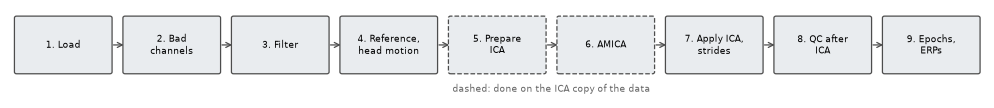

In [4]:
# ---- 0.4 Two helpers for the figures -----------------------------------------------------------------------------------------------
STEPS = ['Load', 'Bad\nchannels', 'Filter', 'Reference,\nhead motion', 'Prepare\nICA', 'AMICA', 'Apply ICA,\nstrides',
         'QC after\nICA', 'Epochs,\nERPs']


def pipeline_map(step):
    """Draws the steps of the pipeline: the current step in orange, the steps already done in green."""
    fig, ax = plt.subplots(figsize=(14, 1.3))
    for i, label in enumerate(STEPS, start=1):
        color = '#f4a261' if i == step else '#b7e4c7' if i < step else '#e9ecef'
        ax.add_patch(FancyBboxPatch((i - 0.43, 0.3), 0.86, 0.6, boxstyle='round,pad=0.02', fc=color, ec='0.3',
                                    ls='--' if i in (5, 6) else '-'))
        ax.text(i, 0.6, f'{i}. {label}', ha='center', va='center', fontsize=7.5, weight='bold' if i == step else 'normal')
        if i < len(STEPS):
            ax.annotate('', xy=(i + 0.58, 0.6), xytext=(i + 0.44, 0.6), arrowprops=dict(arrowstyle='->', color='0.3'))
    ax.text(5.5, 0.08, 'dashed: done on the ICA copy of the data', ha='center', fontsize=7, color='0.4')
    ax.set(xlim=(0.5, len(STEPS) + 0.5), ylim=(0, 1))
    ax.axis('off')
    plt.show()


def show_animation(fig, anim, dpi=72):
    """Shows a matplotlib animation in the notebook, with play and pause buttons."""
    plt.close(fig)                                           # no extra still picture
    fig.set_dpi(dpi)                                         # small frames keep the notebook light
    with plt.rc_context({'animation.frame_format': 'jpeg'}):
        display(HTML(anim.to_jshtml(default_mode='once')))


pipeline_map(0)

## 1. Load and look at the data

**What.** Read the five walking recordings of the participant: walking without the task, then the 4 task blocks.

**Why.** Before changing anything, look at the raw data. You need to know the problems before you fix them.

**The BIDS format.** The data follow BIDS, the Brain Imaging Data Structure (Pernet et al., 2019): a standard way to name and organize
files. The file name says what the file contains:

`sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.vhdr`

= participant P010, session 1, task LexicalDecision, acquisition "walking block 1", run 1, EEG data. Each recording has six files:

| File | Contains |
|---|---|
| `_eeg.vhdr`, `_eeg.vmrk`, `_eeg.eeg` | the signal, in the BrainVision format (header, markers, data) |
| `_eeg.json` | a description of the recording (device, reference, sampling rate...) |
| `_channels.tsv` | one row per channel (name, type, status) |
| `_events.tsv` | one row per event (each word, each response) with its time and details |

The headset also measures its own movement: an accelerometer with three axes, 30 samples per second, in the folder `motion/` next to
`eeg/` (one `_motion.tsv` file per recording). Step 4 uses it.

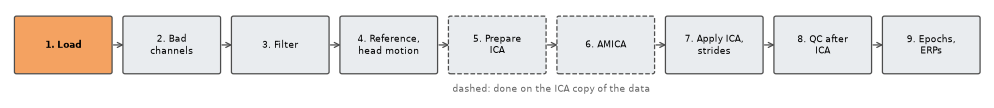

In [5]:
pipeline_map(1)

In [6]:
# ---- 1.1 The walking recordings of this participant (five for P010) --------------------------------------------------------------
EEG_DIR = DATA_DIR / 'bids' / f'sub-{SUBJECT}' / 'ses-001' / 'eeg'
LABELS = {                                                   # our short name: the task and acquisition labels in the BIDS file name
    'walk_only': 'task-WalkingOnly_acq-walking',              # walking on the treadmill, without the task
    'block1': 'task-LexicalDecision_acq-walkingBlock01',
    'block2': 'task-LexicalDecision_acq-walkingBlock02',
    'block3': 'task-LexicalDecision_acq-walkingBlock03',
    'block4': 'task-LexicalDecision_acq-walkingBlock04',
}


def bids_file(name, suffix):
    """The path of one BIDS file of a recording, for example bids_file('block1', 'events.tsv'), or None if it does not exist. The run
    number is usually 01; a recording restarted after a problem gets the next one, and we take the last."""
    return max(EEG_DIR.glob(f'sub-{SUBJECT}_ses-001_{LABELS[name]}_run-*_{suffix}'), default=None)


RECORDINGS = [name for name in LABELS if bids_file(name, 'eeg.vhdr')]   # the recordings this participant has
BLOCKS = [name for name in RECORDINGS if name.startswith('block')]
FIRST_BLOCK = BLOCKS[0]                                      # the block that the figures of steps 1 to 3 show
print('Missing for this participant:', ', '.join(name for name in LABELS if name not in RECORDINGS) or 'nothing')
print(f'The files of {FIRST_BLOCK}:')
for f in sorted(EEG_DIR.glob(f'*{LABELS[FIRST_BLOCK]}*')):
    print(f'  {f.name:80s} {f.stat().st_size / 1e6:6.2f} MB')

Missing for this participant: nothing
The files of block1:
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_channels.tsv       0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.eeg            7.18 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.json           0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.vhdr           0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.vmrk           0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_events.tsv         0.04 MB


In [7]:
# ---- 1.2 What the dataset says about the recording and the channels ---------------------------------------------------------------
sidecar = json.loads(bids_file(FIRST_BLOCK, 'eeg.json').read_text(encoding='utf-8'))    # the _eeg.json file
print('Device:       ', sidecar['ManufacturersModelName'], '-', sidecar['CapManufacturersModelName'])
print('Sampling rate:', sidecar['SamplingFrequency'], 'Hz')
print('Reference:    ', sidecar['EEGReference'])
channels = pd.read_csv(bids_file(FIRST_BLOCK, 'channels.tsv'), sep='\t')                 # the _channels.tsv file
channels[['name', 'type', 'status', 'status_description', 'description']]

Device:        DSI-24 - DSI-24 dry-electrode headset
Sampling rate: 300.0 Hz
Reference:     Pz (online hardware reference). Every scalp channel is recorded as (channel - Pz); Pz is kept as an all-zero EEG channel so that an average reference over the EEG channels reconstructs it. A1/A2 (ear clips) and CM are typed MISC.


,name,type,status,status_description,description
0,P3,EEG,good,NaN,NaN
1,C3,EEG,good,NaN,NaN
2,F3,EEG,good,NaN,NaN
3,Fz,EEG,good,NaN,NaN
4,F4,EEG,good,NaN,NaN
5,C4,EEG,good,NaN,NaN
6,P4,EEG,good,NaN,NaN
7,Cz,EEG,good,NaN,NaN
8,CM,MISC,good,NaN,DSI common-mode sensor
9,A1,MISC,good,NaN,left ear clip


**Look.** 19 channels are EEG. The reference sensor of the DSI-24 sits at **Pz**, and the headset records every channel as (channel − Pz):
its file names them `EEG P3-Pz`, `EEG C3-Pz`... The conversion to BIDS kept `P3`, `C3`... and renamed the old 10-20 names T3, T4, T5, T6
to T7, T8, P7, P8. Pz itself is Pz − Pz = 0, all zeros: the conversion kept it as an EEG channel, so that the average reference of step 4
can give it its own signal back. Four channels are not EEG: `A1` and `A2` (clips on the ear lobes), `CM` (the voltage common to the whole
body, which the reference sensor measures) and `Trigger` (the event signals). The dataset already flags `P7` as flat: its sensor does not
work. We will check all channels ourselves at step 2.

In [8]:
# ---- 1.3 Read the recordings --------------------------------------------------------------------------------------------------
raws, events = {}, {}
for name in RECORDINGS:
    raw = mne.io.read_raw_brainvision(bids_file(name, 'eeg.vhdr'), preload=True)   # the signal, in volts; preload: into memory
    raw.set_channel_types({'CM': 'misc', 'A1': 'misc', 'A2': 'misc', 'Trigger': 'stim'})   # only the 19 scalp channels are EEG
    raw.set_montage('standard_1020')                         # the position of each electrode on the head (10-20 system)
    raws[name] = raw
    events[name] = pd.read_csv(bids_file(name, 'events.tsv'), sep='\t', na_values='n/a')   # one row per event
    print(f'{name:10s} {raw.times[-1] / 60:4.1f} min, {raw.info["sfreq"]:.0f} Hz, '
          f'{(events[name]["trial_type"] == "stimulus").sum():3d} words')
raws[FIRST_BLOCK].info                                       # the description MNE keeps with the data

walk_only   6.4 min, 300 Hz,   0 words
block1      4.3 min, 300 Hz, 100 words
block2      4.0 min, 300 Hz,  93 words
block3      3.6 min, 300 Hz,  88 words
block4      4.3 min, 300 Hz, 100 words


<Info | 8 non-empty values
 bads: []
 ch_names: P3, C3, F3, Fz, F4, C4, P4, Cz, CM, A1, Fp1, Fp2, T7, P7, O1, ...
 chs: 19 EEG, 3 misc, 1 Stimulus
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 150.0 Hz
 meas_date: unspecified
 nchan: 23
 projs: []
 sfreq: 300.0 Hz
>

**How.** `mne.io.read_raw_brainvision(path, preload=True)` reads a BrainVision file and returns a `Raw` object: the signal (channels ×
samples, in volts) and its description `raw.info` (channel names and types, sampling rate, bad channels...). `raw.set_channel_types`
tells MNE which channels are EEG, and `raw.set_montage` gives each electrode its position on the head, which topographic maps and
interpolation need.

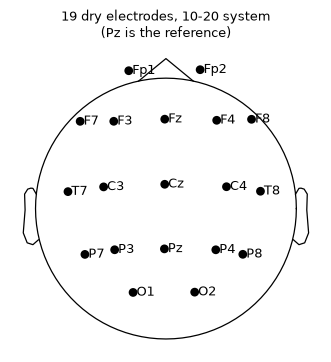

In [9]:
# ---- 1.4 Where the electrodes are -------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(4.5, 4.5))
raws[FIRST_BLOCK].plot_sensors(show_names=True, axes=ax, show=False)
ax.set_title('19 dry electrodes, 10-20 system\n(Pz is the reference)', fontsize=10)
plt.show()

**The 10-20 system.** The letter gives the region: Fp frontopolar, F frontal, C central, T temporal, P parietal, O occipital. Odd numbers are
on the left, even numbers on the right, and z is the midline. Seen from above, the nose is at the top.

In [10]:
# ---- 1.5 The events: one row per word and one per response ------------------------------------------------------------------------
columns = ['onset', 'trial_type', 'stimulus', 'lexicality', 'frequency_class', 'accuracy', 'response_time']
display(events[FIRST_BLOCK][columns].head(7))
words = pd.concat([events[b][events[b]['trial_type'] == 'stimulus'] for b in BLOCKS])   # the 400 words of the 4 blocks
behaviour = words.groupby('frequency_class').agg(trials=('stimulus', 'size'), accuracy=('accuracy', 'mean'),
                                                 median_rt_s=('response_time', 'median'))
behaviour.round(3)

,onset,trial_type,stimulus,lexicality,frequency_class,accuracy,response_time
0,5.033333,recording_start,NaN,NaN,NaN,NaN,NaN
1,7.391411,stimulus,émier,pseudoword,pseudoword,0.0,0.6938
2,8.085211,response,NaN,NaN,NaN,0.0,0.6938
3,9.832668,stimulus,émergé,word,high,1.0,0.8439
4,10.676568,response,NaN,NaN,NaN,1.0,0.8439
5,12.475021,stimulus,nourel,pseudoword,pseudoword,1.0,0.7680
6,13.243021,response,NaN,NaN,NaN,1.0,0.7680


,trials,accuracy,median_rt_s
frequency_class,,,
high,93,0.968,0.698
low,99,0.773,0.814
pseudoword,189,0.851,0.952


**Look.** `onset` is the time in the recording (s), `accuracy` is 1 for a correct answer, and `response_time` is the reaction time (s).
The behaviour already tells a story: frequent words are recognized faster than rare words, and both faster than pseudowords. Accuracy
is high for frequent words (97 %) and lower for rare words (77 %). There are 381 words instead of 400: the recording of block 2 stops
after its 93rd word, and block 3 has 88, with three gaps of about 15 s in its signal (cell 1.9).

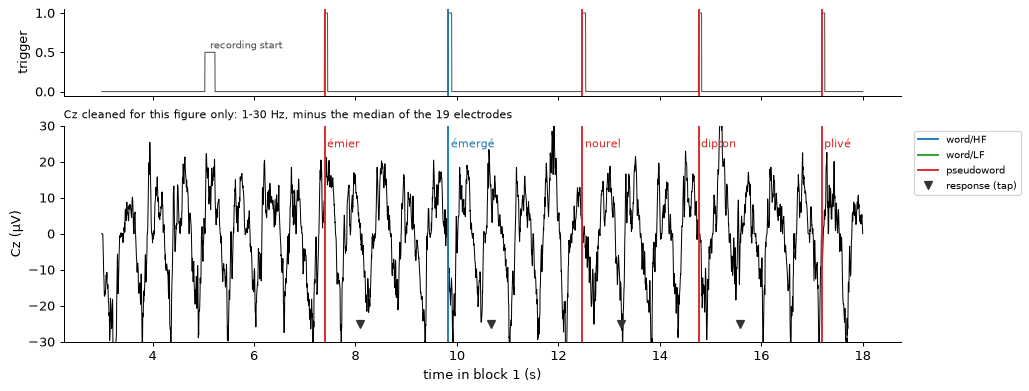

In [11]:
# ---- 1.6 One trial after another: the word onsets, the responses and the trigger channel --------------------------------------------
start, stop = 3, 18                                          # the seconds of the first block we show
piece = raws[FIRST_BLOCK].copy().crop(start, stop)
eeg = piece.copy().pick('eeg').filter(1, 30)                 # the 19 electrodes, filtered only to make the figure readable
# Cz in µV minus a virtual median reference, the median of the 19 electrodes at each sample: cancels the Pz reference of every channel
cz = (eeg.get_data(picks='Cz')[0] - np.median(eeg.get_data(), axis=0)) * 1e6
trigger = piece.get_data(picks='Trigger')[0]
ev = events[FIRST_BLOCK][(events[FIRST_BLOCK]['onset'] >= start) & (events[FIRST_BLOCK]['onset'] <= stop)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True, height_ratios=[1, 2.5])
ax1.plot(piece.times + start, trigger / trigger.max(), color='0.3', lw=0.8)
ax2.plot(piece.times + start, cz, color='k', lw=0.8)
for _, row in ev.iterrows():
    if row['trial_type'] == 'stimulus':
        kind = 'pseudoword' if row['lexicality'] == 'pseudoword' else 'word/HF' if row['frequency_class'] == 'high' else 'word/LF'
        for ax in (ax1, ax2):
            ax.axvline(row['onset'], color=CONDITIONS[kind], lw=1.5)
        ax2.text(row['onset'] + 0.05, 24, row['stimulus'], color=CONDITIONS[kind], fontsize=9)
    elif row['trial_type'] == 'response':
        ax2.plot(row['onset'], -25, 'v', color='0.2', ms=7)
    elif row['trial_type'] == 'recording_start':
        ax1.text(row['onset'] + 0.1, 0.55, 'recording start', fontsize=8, color='0.3')
ax1.set(ylabel='trigger')
ax2.set(xlabel=f'time in block {FIRST_BLOCK[-1]} (s)', ylabel='Cz (µV)', ylim=(-30, 30))
ax2.set_title('Cz cleaned for this figure only: 1-30 Hz, minus the median of the 19 electrodes', fontsize=9, loc='left')
for kind, color in CONDITIONS.items():
    ax2.plot([], [], color=color, label=kind)
ax2.plot([], [], 'v', color='0.2', label='response (tap)')
ax2.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()


**Look.** Four things to see in these 15 seconds of the first block:

1. **The trigger channel (top).** The tablet played a short tone at each word into the trigger channel of the EEG, so each pulse is one
   tone. The first, smaller pulse marks the start of the recording.
2. **The coloured lines** are the word onsets, one colour per condition. An onset is the moment the tablet drew the word, converted to
   EEG time with the help of the tones, so each pulse starts within a few milliseconds of its line. This is how the EEG and the task
   are synchronized.
3. **The triangles** are the taps. The EEG has no trigger for them: each tap is placed at the word onset plus the reaction time
   measured by the tablet (0.7 to 0.85 s here, the `response_time` column of cell 1.5).
4. **Cz (bottom)** is dominated by a regular wave of about ±25 µV, almost two per second: the steps (cell 1.7). An ERP is a few µV,
   much smaller than this, so we will need to average many trials (step 9). This Cz is cleaned for this figure only (1–30 Hz, minus the
   median of the 19 electrodes at each sample, a virtual median reference that cancels the Pz reference every channel carries; step 2
   explains it). The raw signal is much noisier (cell 1.7).

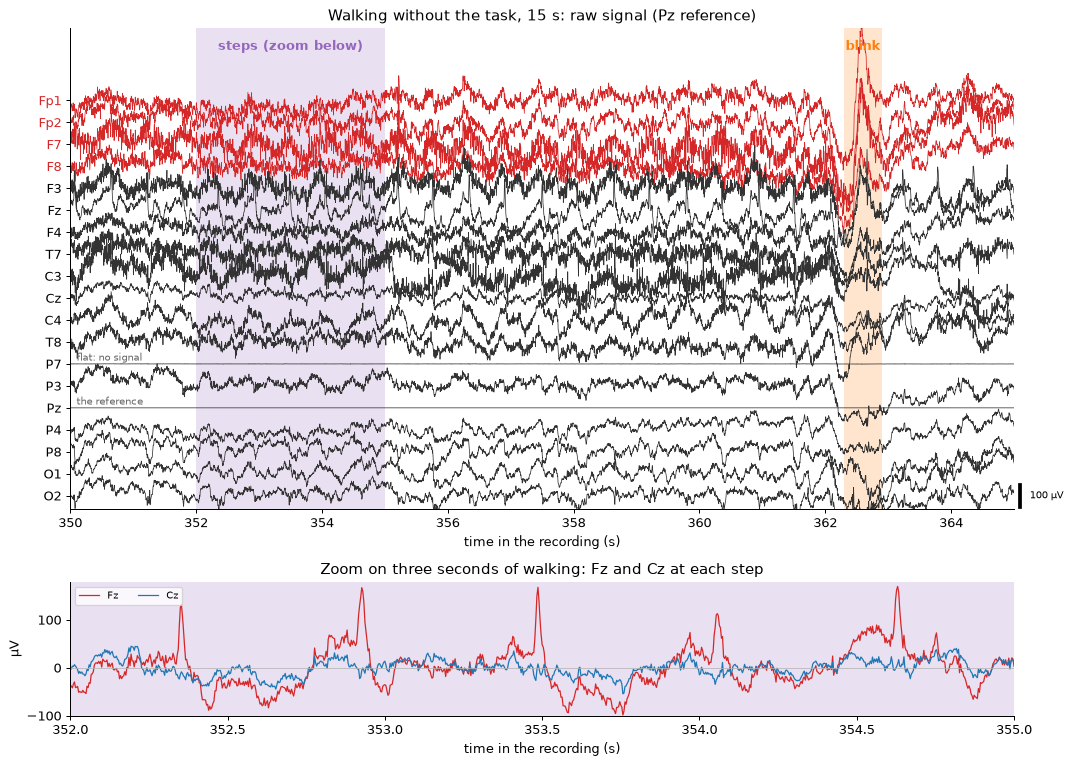

In [12]:
# ---- 1.7 The raw signal while walking: the steps and an eye blink (15 s of walking without the task) ------------------------------------
start, stop = 350, 365                                       # the seconds of the walk we show
eye = ['Fp1', 'Fp2', 'F7', 'F8']                             # the four electrodes closest to the eyes
order = eye + ['F3', 'Fz', 'F4', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']   # the eyes first, then front to back
# the steps of the zoom and the blink of this piece (start, end, name, colour, side of the span where the name is written)
marks = [(352.0, 355.0, 'steps (zoom below)', 'tab:purple', 'center'),
         (362.3, 362.9, 'blink', 'tab:orange', 'center')]
piece = raws['walk_only'].copy().pick('eeg').crop(start, stop)
times = piece.times + start
data = piece.get_data(picks=order) * 1e6                     # the raw signal (Pz reference) in µV
data -= data.mean(axis=1, keepdims=True)                     # each channel around its own mean, as raw.plot() does

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8.6), height_ratios=[4.3, 1.2])
gap = 100                                                    # µV between two channels
for k, (name, y) in enumerate(zip(order, data)):
    ax1.plot(times, y - k * gap, lw=0.6, color='tab:red' if name in eye else '0.2')
ax1.set(yticks=[-k * gap for k in range(len(order))], yticklabels=order, xlim=(start, stop), ylim=(-len(order) * gap + 40, 330),
        xlabel='time in the recording (s)', title='Walking without the task, 15 s: raw signal (Pz reference)')
for label in ax1.get_yticklabels():
    label.set_color('tab:red' if label.get_text() in eye else 'k')
for name, text in (('P7', 'flat: no signal'), ('Pz', 'the reference')):
    ax1.text(start + 0.1, -order.index(name) * gap + 15, text, fontsize=8, color='0.4')
ax1.plot([stop + 0.1] * 2, [-17.5 * gap, -18.5 * gap], color='k', lw=3, clip_on=False)      # the scale bar
ax1.text(stop + 0.25, -18 * gap, '100 µV', va='center', fontsize=8)

zoom = (times >= 352.0) & (times <= 355.0)                   # three seconds of steps, enlarged: Fz and Cz, around their mean
for name, color in (('Fz', 'tab:red'), ('Cz', 'tab:blue')):
    y = data[order.index(name)]
    ax2.plot(times[zoom], (y - y[zoom].mean())[zoom], color=color, lw=1, label=name)
ax2.set(xlim=(352.0, 355.0), ylim=(-100, 180), xlabel='time in the recording (s)', ylabel='µV',
        title='Zoom on three seconds of walking: Fz and Cz at each step')
ax2.axhline(0, color='0.7', lw=0.6)
ax2.legend(loc='upper left', ncol=2, fontsize=8)

for t0, t1, label, color, side in marks:
    for ax in (ax1, ax2):
        ax.axvspan(t0, t1, color=color, alpha=0.2, lw=0)
    x = {'center': (t0 + t1) / 2, 'right': t0 - 0.05, 'left': t1 + 0.05}[side]
    ax1.text(x, 0.975, label, color=color, ha=side, va='top', weight='bold', transform=ax1.get_xaxis_transform())
plt.tight_layout()
plt.show()


**Look.** This is the raw signal (no filter, Pz reference) of 15 seconds of walking without the task, from the front of the head to the
back. The four electrodes closest to the eyes (Fp1, Fp2, F7, F8) are in red.

1. **The steps** (purple, zoom below). Every channel moves with a rhythm of almost two waves per second: the participant takes about
   1.8 steps per second (the heel contacts measured in the Brain Walk project are 0.56 s apart in this recording). Each step shakes the
   electrodes and their cables. At Fz it gives a sharp peak of 100 to 170 µV at every step; at Cz, a slower wave of a few tens of µV.
2. **Eye blink** (362.6 s, orange). A sharp wave of about half a second on Fp1, Fp2, F7 and F8, which stands out above the steps at the
   front of the head.
3. **P7** is a flat line: its sensor does not work and gives the same voltage as the reference, so P7 − Pz = 0.
4. **Pz** is flat by construction: it is the reference, Pz − Pz = 0.

The steps are artifacts too, and they never stop: unlike a blink, they are in every trial. Step 4 removes the part of them that follows
the movement of the head, which the headset measures with its accelerometer.

To scroll through a recording yourself, run `raws['walk_only'].plot()` on your own computer with an interactive backend (`%matplotlib
qt` or `%matplotlib widget`).

In [13]:
%matplotlib qt
mne.viz.set_browser_backend('matplotlib')

fig = raws['walk_only'].plot(picks='eeg', start=100, duration=20, scalings=dict(eeg=100e-6))


### 1.9 Keep what we analyze, label the words, join the four blocks

- **Cut at the triggers**: keep each recording between its triggers. A block runs from the start pulse to the stop pulse of the headset
  hub, the walk without the task from its `walk_start` to its `walk_end` event (the events of cell 1.5). What comes before and after is not the task, and it can hold
  very strong artifacts. `raw.crop(tmin, tmax)` removes it from the data, so every later step sees only the part we keep. Marking it as
  `BAD` would not be enough: the filters and the blink detection do not skip `BAD` segments.
- **Task**: turn each word into an **annotation**, a label at a time in the recording. The label is the condition: `word/HF`, `word/LF`
  or `pseudoword`; the `/` lets us later select all words at once with `epochs['word']`. When the wireless link of the headset lost samples
  (`data_gap` in the events), we mark 2 s around it as `BAD_gap`: MNE ignores segments whose annotation starts with `BAD`.
- Then **join** the four blocks into one task recording with `mne.concatenate_raws`. MNE marks each junction with a `BAD boundary`
  annotation (no epoch may cross it) and an `EDGE boundary` (filters treat each block separately).

In [14]:
# ---- 1.9 Cut at the triggers, label the words and join the blocks ----------------------------------------------------------------
def condition_of(row):
    """word/HF, word/LF or pseudoword, from one row of an events.tsv file."""
    if row['lexicality'] == 'pseudoword':
        return 'pseudoword'
    return 'word/HF' if row['frequency_class'] == 'high' else 'word/LF'


def label_words(raw, ev):
    """A copy of raw whose annotations are the word onsets (named by condition) and the data gaps (BAD)."""
    raw = raw.copy()
    sfreq = raw.info['sfreq']
    stim = ev[ev['trial_type'] == 'stimulus']
    annotations = mne.Annotations(onset=stim['sample'] / sfreq, duration=0.0, description=list(stim.apply(condition_of, axis=1)))
    gaps = ev.loc[ev['trial_type'] == 'data_gap', 'sample'] / sfreq     # where the wireless link lost samples
    if len(gaps):
        annotations += mne.Annotations(onset=np.maximum(gaps - 1, 0), duration=2.0, description='BAD_gap')
    raw.set_annotations(annotations)
    return raw


def cut_at_triggers(raw, ev, first, last):
    """A copy of raw cut between two triggers of its events table (or at the start and end of the file, when a trigger is missing).
    crop() removes the rest from the data and moves the annotations with it."""
    start = ev.loc[ev['trial_type'] == first, 'onset']
    stop = ev.loc[ev['trial_type'] == last, 'onset']
    begin = start.iloc[0] if len(start) else 0.0
    end = min(stop.iloc[0], raw.times[-1]) if len(stop) else raw.times[-1]
    return raw.copy().crop(begin, end)


cut_raws = {}                                                # the five recordings, each cut between its triggers
for name in raws:
    if name in BLOCKS:                                       # a block: from the start pulse to the stop pulse of the hub, words labelled
        cut_raws[name] = cut_at_triggers(label_words(raws[name], events[name]), events[name], 'recording_start', 'recording_stop')
    else:                                                    # walking without the task: from the start to the end of the walk
        cut_raws[name] = cut_at_triggers(raws[name].copy().set_annotations(None), events[name], 'walk_start', 'walk_end')
    print(f'{name:9s} kept {cut_raws[name].times[-1]:4.0f} s of {raws[name].times[-1]:4.0f} s')

recordings = {}                                              # walking without the task, then the task (the blocks joined)
if 'walk_only' in cut_raws:
    recordings['walk_only'] = cut_raws['walk_only'].copy()
recordings['task'] = mne.concatenate_raws([cut_raws[b].copy() for b in BLOCKS])   # (this function changes the first recording it gets: we give copies)
trials = pd.concat([events[b][events[b]['trial_type'] == 'stimulus'] for b in BLOCKS], ignore_index=True)   # one row per word
trials['condition'] = trials.apply(condition_of, axis=1)
for name, raw in recordings.items():
    labels = pd.Series(raw.annotations.description).value_counts().to_dict()
    print(f'{name:10s} {raw.times[-1] / 60:5.1f} min   annotations: {labels if labels else "none"}')

walk_only kept  300 s of  384 s
block1    kept  252 s of  260 s
block2    kept  236 s of  238 s
block3    kept  214 s of  218 s
block4    kept  250 s of  258 s
walk_only    5.0 min   annotations: none
task        15.9 min   annotations: {'pseudoword': 189, 'word/LF': 99, 'word/HF': 93, 'BAD_gap': 5, 'BAD boundary': 3, 'EDGE boundary': 3}


## 2. Find the bad channels

**What.** Find the electrodes whose signal is not EEG: **flat** (no contact, broken electrode) or **noisy** (much larger than the others:
poor contact, an electrode that moves). Dry electrodes have more of these problems than gel electrodes. In three studies, 5.3 faulty
electrodes had to be interpolated on average with dry electrodes against 2.0 with gel (Kam et al., 2019), 16 % of the channels were bad
against 3 % (Fiedler et al., 2022), and 10.5 % of the data was rejected against 3.9 % (Heijs et al., 2021). We also write down the short periods when one channel, or the
whole scalp, looks suspicious (cell 2.5).

**Why now.** A bad channel spreads to every channel when we re-reference to the average (step 4) and it disturbs ICA (step 6). We mark
the bad channels now (`raw.info['bads']`), and they stay marked until the end: MNE leaves them out where it should (the average reference,
ICA, the rejection of epochs), and this notebook never rebuilds them from their neighbours (step 8 says why).

**How.** For each channel, measure its amplitude and compare it with the typical amplitude: the median of the amplitudes of all the
channels. While walking, a channel can be very large for a few seconds (a step that shakes it, a moment of poor contact) and normal the
rest of the time, so mobile EEG pipelines judge each channel in short windows, and call it bad only when it is abnormal in a large share of
them (Klug et al., 2022, 2024). We do the same with windows of 5 s, over all the walking recordings together. Which measure of
amplitude? The usual one, the standard deviation, is pulled up by rare large events (a movement, a burst of muscle activity): they can
make a good channel look noisy. A **robust** measure, the median absolute deviation (MAD), ignores them. The order of the checks matters too. Flat
channels are looked for on the signal as it was recorded. Noisy channels are looked for after a temporary
**virtual median reference**, which cancels the Pz reference that every recorded channel carries (cell 2.2). It is a tool for the detection only: the
data keep the Pz reference until step 4.

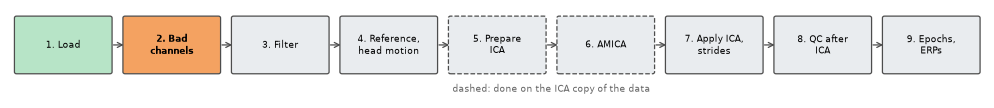

In [15]:
pipeline_map(2)

### Before we measure

Published pipelines prepare the data before they look for bad channels. We do the same here:

1. **Leave out what is not scalp EEG.** `A1`, `A2`, `CM` and `Trigger` are not EEG: we gave them other types when we loaded the data
   (cell 1.3).
2. **Measure on a copy filtered at 1–40 Hz.** Below 1 Hz, slow drifts (sweat, an electrode that moves) would dominate the amplitude of a
   channel, and above 40 Hz the 60 Hz of the electrical network would add to it. The recording itself stays unfiltered.
3. **Look for flat channels before changing the reference.** On the DSI-24, a sensor that does not work gives the same voltage as the
   reference, so its channel is Pz − Pz = 0: flat, like Pz itself (P7 here). A new reference subtracts the same signal from every
   channel, so it would turn a flat channel into a copy of the re-referenced Pz, which no longer looks flat. Flat channels are found
   first, on the signal as recorded, and set aside: they are not re-referenced, and they do not enter the median reference of item 4.
4. **Cancel the reference term that every channel carries before looking for noisy ones.** The reference sensor at Pz measures the voltage of the body
   against the headset's ground, which is large and common to the whole body (static, movements, the electrical network: the `CM`
   channel). The headset records every channel relative to that sensor, so this common voltage cancels (Wearable Sensing, 2023). What the
   subtraction puts into every channel, with a minus sign, is the activity under Pz: the EEG there and the noise of the Pz sensor. Before
   we look for noisy channels, a temporary virtual median reference cancels this term (cell 2.2).
5. **Cut each recording at its triggers.** Cell 1.9 keeps a block between the start pulse and the stop pulse of the headset hub, and the
   walk without the task between its `walk_start` and `walk_end` events. What comes before and after is not the task, and it can hold very strong artifacts that
   affect channel rejection and ICA (Klug et al., 2022).

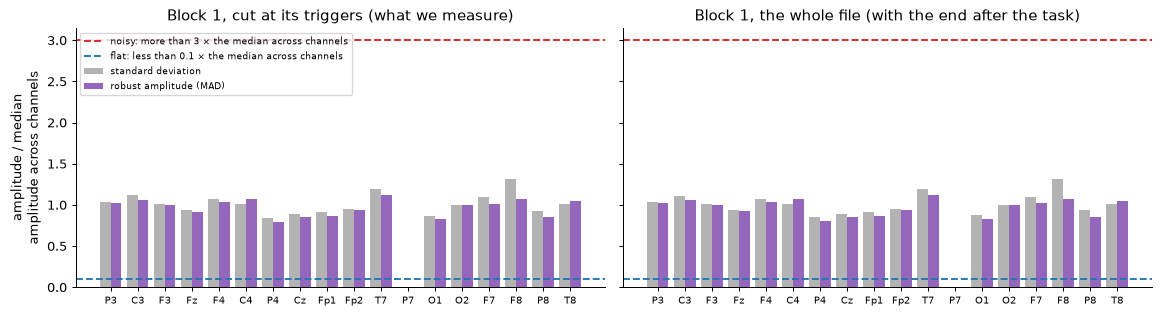

In [16]:
# ---- 2.1 Standard deviation or robust amplitude? ------------------------------------------------------------------------------------
def amplitudes(raw, reference_channels=None):
    """Standard deviation and robust amplitude (1.4826 x MAD) of each EEG channel except Pz (µV), on a 1-40 Hz copy of raw.
    reference_channels=None: the signal as recorded, every channel minus Pz. Otherwise, only to look for noisy channels: the temporary
    virtual median reference of cell 2.2 (at each sample, the median of reference_channels) is subtracted from reference_channels, and
    the other channels (the flat ones) are left out (NaN). raw itself is never changed."""
    eeg = raw.copy().pick('eeg').filter(1, 40)               # 1-40 Hz: ignore the slow drifts and the 60 Hz noise
    x = eeg.get_data() * 1e6                                  # as recorded: every channel minus Pz (µV)
    if reference_channels is not None:
        rows = [eeg.ch_names.index(ch) for ch in reference_channels]
        y = np.full_like(x, np.nan)                           # the channels outside reference_channels are left out
        y[rows] = x[rows] - np.median(x[rows], axis=0)        # each channel minus the sample-wise median reference
        x = y
    sd = x.std(axis=1)
    mad = 1.4826 * np.median(np.abs(x - np.median(x, axis=1, keepdims=True)), axis=1)   # equals the SD for Gaussian noise
    return pd.DataFrame({'sd': sd, 'robust': mad}, index=eeg.ch_names).drop(index='Pz')   # Pz, the reference, is not judged


fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, (title, raw) in zip(axes, [(f'Block {FIRST_BLOCK[-1]}, cut at its triggers (what we measure)', cut_raws[FIRST_BLOCK]),
                                   (f'Block {FIRST_BLOCK[-1]}, the whole file (with the end after the task)', raws[FIRST_BLOCK])]):
    ratio1 = amplitudes(raw)
    ratio1 = ratio1 / ratio1.median()                        # each channel / the median across channels, for each measure
    x = np.arange(len(ratio1))
    ax.bar(x - 0.2, ratio1['sd'], 0.4, color='0.7', label='standard deviation')
    ax.bar(x + 0.2, ratio1['robust'], 0.4, color='tab:purple', label='robust amplitude (MAD)')
    ax.axhline(NOISY_RATIO, color='tab:red', ls='--', label=f'noisy: more than {NOISY_RATIO:g} × the median across channels')
    ax.axhline(FLAT_RATIO, color='tab:blue', ls='--', label=f'flat: less than {FLAT_RATIO:g} × the median across channels')
    ax.set(xticks=x, xticklabels=ratio1.index, title=title)
    ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('amplitude / median\namplitude across channels')
axes[0].legend(fontsize=7.5, loc='upper left')
plt.tight_layout()
plt.show()

**Look.** Left: block 1 cut at its triggers. The standard deviation (grey) and the robust amplitude (purple) agree, and only **P7** stands
out, far below the flat line. Right: the whole file, with 5 s before the task and 3 s after it. In this block it changes almost nothing,
but the end of a recording can hold large bursts that push the standard deviation of a channel above the "noisy" line while its robust
amplitude stays normal. The mean and the standard deviation are moved by the very values they are meant to detect; the median and the MAD
are not (Leys et al., 2013). PREP's noisy-channel criterion is robust for the same reason: it "does not identify channels that capture
eye-blinks and most muscle activity as noisy" (Bigdely-Shamlo et al., 2015). Leys et al. recommend flagging the values beyond the median
± 2.5 MAD; we compare each channel with the typical amplitude, the median robust amplitude across channels, instead. We measure the
recordings cut at their triggers (cell 1.9): what comes before and after is not the task.

### A temporary virtual median reference, only to find noisy channels

The DSI-24 records every channel relative to Pz. With $V_i$ the voltage under electrode $i$:

$$x_i(t) = V_i(t) - V_{Pz}(t), \qquad \text{so the stored Pz channel is } V_{Pz} - V_{Pz} = 0.$$

Every recorded channel therefore contains the same term, $-V_{Pz}$. A large shared term makes the channels look alike, and can hide a
channel that is noisy on its own. To look for noisy channels, we cancel it with a **virtual median reference**. At each sample $t$, it is
the median of the usable channels: the EEG channels except Pz and the flat channels found on the signal as recorded. There is no median
electrode: this reference is computed, not recorded.

$$m(t) = \operatorname{median}_i \, x_i(t) = \operatorname{median}_i V_i(t) - V_{Pz}(t)$$

$$y_i(t) = x_i(t) - m(t) = V_i(t) - \operatorname{median}_i V_i(t)$$

The median contains the same $-V_{Pz}$ term as every channel, so the subtraction cancels the Pz reference. Unlike a mean, a median is not
pulled by one or two extreme channels, so a noisy electrode barely changes the reference it is compared with. Pz becomes
$y_{Pz}(t) = V_{Pz}(t) - \operatorname{median}_i V_i(t)$: Pz **relative to the virtual reference**, not a recovered absolute voltage of Pz
(a voltage is always a difference between two points, step 4).

Two different medians are used in this step:

- the **sample-wise median reference** $m(t)$: at each sample, the median of the channel values. It is a signal.
- the **typical amplitude**: the median of the robust amplitudes of the channels, one number per recording. The flat and noisy thresholds
  are multiples of it.

**For detection only.** The median reference is computed on 1–40 Hz copies and never changes the data. Once the bad channels are found
(cell 2.4), they are stored in `raw.info['bads']`, and the next steps use the recordings as they are, still referenced to Pz. The real
reference comes at step 4: the average of the good channels, Pz included with its zeros. The idea of a median as a robust first estimate of
the reference comes from the robust referencing of PREP (Bigdely-Shamlo et al., 2015). Our criterion is much simpler, and this notebook does
not implement PREP.

Median reference of block 1: at each sample, the median of 17 channels (P3, C3, F3, Fz, F4, C4, P4, Cz, Fp1, Fp2, T7, O1, O2, F7, F8, P8, T8). Left out: Pz, the reference, and the flat channels (P7).


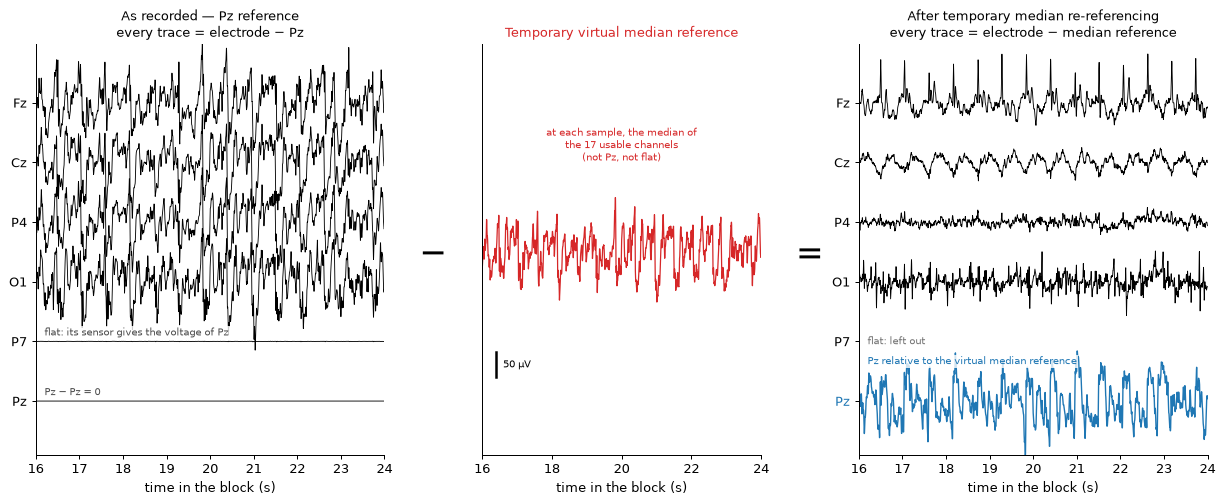

In [17]:
# ---- 2.2 The temporary virtual median reference, on block 1 -------------------------------------------------------------------------
eeg_1 = cut_raws[FIRST_BLOCK].copy().pick('eeg').filter(1, 40)          # a 1-40 Hz copy of the block: the recording is not changed
names = eeg_1.ch_names                                                   # the 19 EEG channels, Pz included
x = eeg_1.get_data() * 1e6                                               # as recorded: every channel minus Pz (µV); Pz - Pz = 0
as_recorded = amplitudes(cut_raws[FIRST_BLOCK])                          # the flat channels are found on the signal as recorded
flat_1 = list(as_recorded.index[(as_recorded['robust'] / as_recorded['robust'].median() < FLAT_RATIO) | (as_recorded['sd'] < FLAT_SD_UV)])
usable_1 = [ch for ch in names if ch != 'Pz' and ch not in flat_1]      # the channels of the median reference: not Pz, not flat
median_ref = np.median(x[[names.index(ch) for ch in usable_1]], axis=0)   # at each sample, the median of the usable channels
y = x - median_ref                                                       # every channel minus the median reference ...
y[[names.index(ch) for ch in flat_1]] = np.nan                           # ... except the flat channels: left out, not re-referenced
print(f'Median reference of block {FIRST_BLOCK[-1]}: at each sample, the median of {len(usable_1)} channels ({", ".join(usable_1)}). '
      f'Left out: Pz, the reference, and the flat channels ({", ".join(flat_1) or "none"}).')

start, length, gap = 16, 8, 120                                          # the seconds of the block we show; µV between two traces
piece = slice(int(start * eeg_1.info['sfreq']), int((start + length) * eeg_1.info['sfreq']))
t = eeg_1.times[piece]
shown = ['Fz', 'Cz', 'P4', 'O1', 'P7', 'Pz']
label_box = dict(fc='white', ec='none', alpha=0.8, pad=1)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6), width_ratios=[1, 0.8, 1])
fig.subplots_adjust(left=0.05, right=0.98, top=0.86, bottom=0.1, wspace=0.3)
for ax, data in ((ax1, x), (ax3, y)):
    for k, ch in enumerate(shown):
        trace = data[names.index(ch)][piece]
        if np.isnan(trace).all():
            ax.text(start + 0.2, -k * gap, 'flat: left out', va='center', fontsize=8, color='0.45')
        else:
            pz_after = ch == 'Pz' and data is y
            ax.plot(t, trace - k * gap, color='tab:blue' if pz_after else 'k', lw=1.1 if pz_after else 0.7)
    ax.set(yticks=[-k * gap for k in range(len(shown))], yticklabels=shown, xlabel='time in the block (s)')
ax1.text(start + 0.2, -shown.index('Pz') * gap + 12, 'Pz − Pz = 0', fontsize=8, color='0.3', bbox=label_box)
ax1.text(start + 0.2, -shown.index('P7') * gap + 12, 'flat: its sensor gives the voltage of Pz', fontsize=8, color='0.3', bbox=label_box)
ax3.text(start + 0.2, -shown.index('Pz') * gap + 0.62 * gap, 'Pz relative to the virtual median reference', fontsize=8, color='tab:blue',
         bbox=label_box)
ax3.get_yticklabels()[shown.index('Pz')].set_color('tab:blue')
ax2.plot(t, median_ref[piece] - 2.5 * gap, color='tab:red', lw=1)
ax2.text(start + length / 2, -0.4 * gap, f'at each sample, the median of\nthe {len(usable_1)} usable channels\n(not Pz, not flat)', ha='center',
         va='top', fontsize=8, color='tab:red')
ax2.plot([start + 0.4] * 2, [-4.6 * gap, -4.6 * gap + 50], color='k', lw=2)      # the scale bar, the same in the three panels
ax2.text(start + 0.6, -4.6 * gap + 25, '50 µV', va='center', fontsize=8)
ax2.set(yticks=[], xlabel='time in the block (s)')
for ax in (ax1, ax2, ax3):
    ax.set(xlim=(start, start + length), ylim=(-(len(shown) - 1) * gap - 0.9 * gap, 0.98 * gap))
ax1.set_title('As recorded — Pz reference\nevery trace = electrode − Pz', fontsize=10)
ax2.set_title('Temporary virtual median reference', fontsize=10, color='tab:red')
ax3.set_title('After temporary median re-referencing\nevery trace = electrode − median reference', fontsize=10)
for left, right, sign in ((ax1, ax2, '−'), (ax2, ax3, '=')):
    fig.text((left.get_position().x1 + right.get_position().x0) / 2, 0.47, sign, ha='center', va='center', fontsize=26)
plt.show()

**Look.** Read the figure as a subtraction, with the same scale in the three panels. Left: as recorded, every trace is the electrode minus
Pz. Pz itself is a flat line, and so is P7, whose sensor gives the same voltage as the reference. Large regular waves, almost two per
second, appear in every channel at the same time: the steps. Middle: the temporary virtual median reference (red), computed at each
sample from the 17 usable channels, with Pz and P7 left out. It contains the same $-V_{Pz}$ term as every recorded channel. Right: each
channel minus the median reference. The $-V_{Pz}$ term cancels, and so does most of what the channels shared: P4 becomes small. What is
left belongs to each electrode: Fz keeps a sharp peak at every step (cell 1.7) and Cz a smaller regular wave. Pz (blue) now has a signal,
0 minus the median reference: the red trace upside down. It is Pz relative to the virtual median reference, not a recovered voltage of Pz,
and it is the largest trace: while walking, the reference sensor at Pz records large signals of its own. P7 is left out: a flat channel
is never re-referenced.

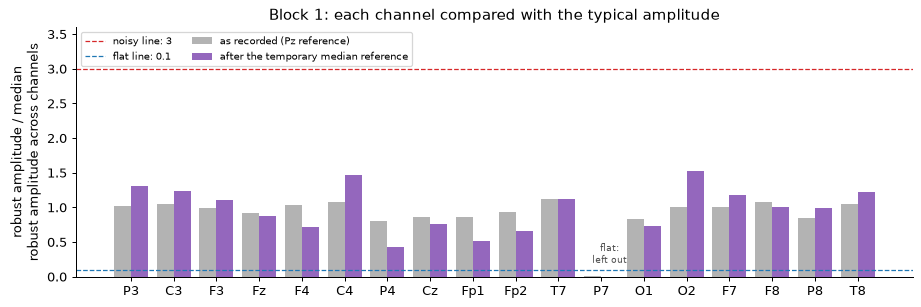

Typical amplitude (the median robust amplitude across channels): 37.4 µV as recorded, 17.1 µV after the temporary median reference.
The median reference itself: 30.2 µV, that is 65 % of the variance of a typical recorded channel.
Channels that are not flat: from 0.80 to 1.12 × the typical amplitude as recorded, from 0.42 to 1.52 after the median reference.
The CM channel (the voltage common to the whole body): 53 µV, 1.4 times a typical recorded channel.


In [18]:
# ---- 2.2 (continued) Each channel compared with the typical amplitude, before and after the temporary median reference --------------
after_ref = amplitudes(cut_raws[FIRST_BLOCK], reference_channels=usable_1)   # robust amplitudes after the median reference
before = as_recorded['robust'] / as_recorded['robust'].median()             # robust amplitude / median robust amplitude across channels
after = after_ref['robust'] / after_ref['robust'].median()                  # the same after the median reference (flat channels: NaN)
bars = np.arange(len(before))
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(bars - 0.2, before, 0.4, color='0.7', label='as recorded (Pz reference)')
ax.bar(bars + 0.2, after, 0.4, color='tab:purple', label='after the temporary median reference')
ax.axhline(NOISY_RATIO, color='tab:red', ls='--', lw=1, label=f'noisy line: {NOISY_RATIO:g}')
ax.axhline(FLAT_RATIO, color='tab:blue', ls='--', lw=1, label=f'flat line: {FLAT_RATIO:g}')
for ch in flat_1:
    ax.text(list(before.index).index(ch) + 0.2, 0.2, 'flat:\nleft out', ha='center', fontsize=7, color='0.3')
ax.set(xticks=bars, xticklabels=before.index, ylim=(0, NOISY_RATIO + 0.6), ylabel='robust amplitude / median\nrobust amplitude across channels',
       title=f'Block {FIRST_BLOCK[-1]}: each channel compared with the typical amplitude')
ax.legend(fontsize=8, loc='upper left', ncol=2)
plt.show()

typical_before, typical_after = as_recorded['robust'].median(), after_ref['robust'].median()
reference_amp = 1.4826 * np.median(np.abs(median_ref - np.median(median_ref)))   # the robust amplitude of the median reference itself
cm = cut_raws[FIRST_BLOCK].copy().pick(['CM']).filter(1, 40, picks='all').get_data()[0] * 1e6   # the voltage common to the whole body
cm_amp = 1.4826 * np.median(np.abs(cm - np.median(cm)))
print(f'Typical amplitude (the median robust amplitude across channels): {typical_before:.1f} µV as recorded, {typical_after:.1f} µV after '
      f'the temporary median reference.')
print(f'The median reference itself: {reference_amp:.1f} µV, that is {100 * (reference_amp / typical_before) ** 2:.0f} % of the variance '
      f'of a typical recorded channel.')
print(f'Channels that are not flat: from {before.drop(flat_1).min():.2f} to {before.drop(flat_1).max():.2f} × the typical amplitude as '
      f'recorded, from {after.min():.2f} to {after.max():.2f} after the median reference.')
print(f'The CM channel (the voltage common to the whole body): {cm_amp:.0f} µV, {cm_amp / typical_before:.1f} times a typical recorded channel.')

**Look.** Each bar is a channel's robust amplitude divided by the typical amplitude: the median robust amplitude across channels, one
number for the block (not the median reference of the figure above, which is a signal). As recorded (grey), every channel except P7 is
between 0.80 and 1.12 times the typical amplitude. The channels look alike because a large part of each recorded channel is shared by all
of them: the median reference alone is 30.2 µV, about 65 % of the variance of a typical recorded channel (37.4 µV; 13.7 µV in the seated
blocks of this participant). A noisy electrode would be partly hidden by this shared part. After the temporary median reference (purple),
the typical amplitude falls to 17.1 µV and the differences between electrodes show, from 0.42 (P4) to 1.52 (O2). No channel reaches the
noisy line (3) in this block. P7 is far below the flat line as recorded, and it is left out after.

P7: flat on the signal as recorded (as low as 0.00 × the typical amplitude, SD as low as 0.18 µV)
The other channels are too large in at most 41 % (Pz), 9 % (C4), 7 % (Fz), 4 % (T8) of their windows (noisy: more than 50 %).
Report: flat = below 0.1 × the typical amplitude or SD below 1 µV in a recording, on the signal as recorded; noisy = above 3 × the typical amplitude of its 5-s window, after a temporary median reference, in more than 50 % of the 248 windows of the 5 walking recordings (Pz included; the rule run twice). Bad channels: ['P7'] (1 of 19), kept in raw.info['bads'] until the end: never rebuilt.
The recordings themselves are not changed: still referenced to Pz (largest |Pz| in the task: 0.0 µV).


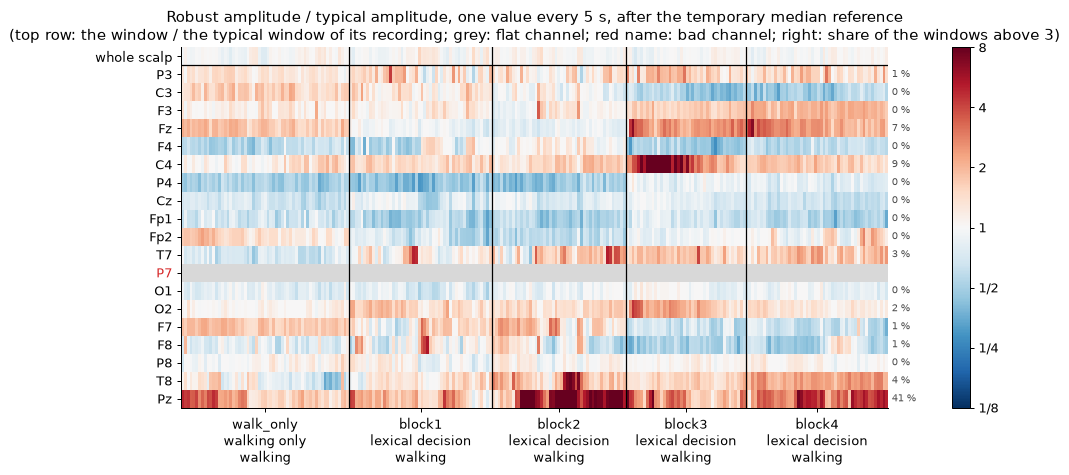

In [19]:
# ---- 2.4 The bad channels, judged over time in 5-s windows ---------------------------------------------------------------------------
# 1. Flat: one number per channel and recording, on the signal as recorded (as in the seated notebook)
amp_pz = {name: amplitudes(raw) for name, raw in cut_raws.items()}                              # the signal as recorded (Pz reference)
ratio_pz = pd.DataFrame({name: a['robust'] for name, a in amp_pz.items()})
ratio_pz = ratio_pz / ratio_pz.median()                      # robust amplitude / typical amplitude (the median across channels)
sd = pd.DataFrame({name: a['sd'] for name, a in amp_pz.items()})
flat = ((ratio_pz < FLAT_RATIO) | (sd < FLAT_SD_UV)).any(axis=1)        # flat in at least one recording, on the recorded signal
flat_channels = sorted(flat.index[flat])
eeg_channels = cut_raws[FIRST_BLOCK].copy().pick('eeg').ch_names       # the 19 EEG channels, Pz included

TASK_NAMES = {'RestingState': 'resting state', 'LexicalDecision': 'lexical decision', 'WalkingOnly': 'walking only'}
PARTS, first_sample = {}, 0                                  # each recording cut at its triggers: where it is in `recordings`
for name, raw in cut_raws.items():
    PARTS[name] = ('task', first_sample) if name in BLOCKS else (name, 0)
    first_sample += raw.n_times if name in BLOCKS else 0


def block_label(name):
    """The name of the recording, its task and its posture, from its BIDS name (cell 1.1): block1, lexical decision, seated."""
    task, acq = LABELS[name].removeprefix('task-').split('_acq-')
    return f"{name}\n{TASK_NAMES.get(task, task)}\n{'seated' if acq.startswith('seated') else 'walking'}"


def window_quality(data, reference):
    """The 5-s check of `data` (walking without the task, then the task, as in `recordings`). Each part (the walk, each block) is
    cut into QC_WINDOW_S windows. In each window: the robust amplitude of every channel that is not flat, Pz included, after the
    temporary median reference of the `reference` channels (1-40 Hz), divided by the typical amplitude of the window (the median over
    `reference`); and in the row 'whole scalp', the typical amplitude of the window divided by the typical window of its part.
    Returns this table (one column per window) and the windows (part, recording, start in s)."""
    shown = [ch for ch in eeg_channels if ch not in flat_channels]
    rows = [shown.index(ch) for ch in reference]
    columns, windows = [], []
    for part, (recording, first) in PARTS.items():
        raw = data[recording]
        x = raw.get_data(picks=shown, start=first, stop=first + cut_raws[part].n_times) * 1e6   # this part, the channels shown (µV)
        x = mne.filter.filter_data(x, raw.info['sfreq'], 1, 40)                          # 1-40 Hz, as in cell 2.1
        x = x - np.median(x[rows], axis=0)                                                # minus the temporary median reference
        n = int(QC_WINDOW_S * raw.info['sfreq'])
        mad = np.array([1.4826 * np.median(np.abs(p - np.median(p, axis=1, keepdims=True)), axis=1)
                        for p in (x[:, k:k + n] for k in range(0, x.shape[1] - n + 1, n))]).T   # channels × windows
        typical = np.median(mad[rows], axis=0)                                            # the typical amplitude of each window
        columns.append(np.vstack([typical / np.median(typical), mad / typical]))
        windows += [(part, recording, (first + k * n) / raw.info['sfreq']) for k in range(mad.shape[1])]
    return (pd.DataFrame(np.hstack(columns), index=['whole scalp'] + shown),
            pd.DataFrame(windows, columns=['part', 'recording', 'start']))


def plot_quality(table, ax, title):
    """A table of window_quality as a heatmap: one column per window; the row 'whole scalp' on top, then every EEG channel (the
    flat ones have no value: grey). The colour is log2 of the ratio, from 1/8 to 8, the same in every figure."""
    rows = ['whole scalp'] + eeg_channels
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('0.85')
    image = ax.imshow(np.log2(table.reindex(rows).to_numpy()), cmap=cmap, vmin=-3, vmax=3, aspect='auto', interpolation='nearest')
    parts = windows['part'].to_numpy()
    edges = np.flatnonzero(parts[1:] != parts[:-1]) + 1      # the first window of each part after the first
    for edge in edges:
        ax.axvline(edge - 0.5, color='k', lw=1)
    ax.axhline(0.5, color='k', lw=1)                         # the whole scalp above, the channels below
    ax.set(yticks=range(len(rows)), yticklabels=rows, xticks=(np.r_[0, edges] + np.r_[edges, len(parts)]) / 2 - 0.5,
           xticklabels=[block_label(part) for part in PARTS], title=title)
    for label in ax.get_yticklabels():
        if label.get_text() in BAD_CHANNELS:
            label.set_color('tab:red')                       # the bad channels: their name in red
    return image


# 2. Noisy: too large (above NOISY_RATIO × the typical amplitude of its window) in more than NOISY_SHARE of the windows of all the
# walking recordings. Pz is judged too: relative to the median reference, its signal is the activity, and the noise, of the reference
# sensor. Twice, as Gonsisko et al. (2023): the second time, the noisy channels of the first are left out of the median reference
noisy_channels = []
for passage in range(2):
    usable = [ch for ch in eeg_channels if ch != 'Pz' and ch not in flat_channels + noisy_channels]   # the median reference
    quality, windows = window_quality(recordings, usable)
    share = (quality.drop(index='whole scalp') > NOISY_RATIO).mean(axis=1)   # in how many of its windows each channel is too large
    noisy_channels = sorted(set(noisy_channels) | set(share.index[share > NOISY_SHARE]))
BAD_CHANNELS = sorted(flat_channels + noisy_channels)
usable = [ch for ch in usable if ch not in BAD_CHANNELS]
for raw in recordings.values():
    raw.info['bads'] = list(BAD_CHANNELS)                    # MNE now leaves these channels out where it should, until the end
good = [ch for ch in eeg_channels if ch not in BAD_CHANNELS and ch != 'Pz']   # the good channels, without Pz (still all zeros)

for ch in BAD_CHANNELS:
    if ch in flat_channels:
        print(f'{ch}: flat on the signal as recorded (as low as {ratio_pz.loc[ch].min():.2f} × the typical amplitude, SD as low as '
              f'{sd.loc[ch].min():.2f} µV)')
    else:
        print(f'{ch}: noisy, above {NOISY_RATIO:g} × the typical amplitude in {100 * share[ch]:.0f} % of its windows')
largest = share.drop(BAD_CHANNELS, errors='ignore').sort_values(ascending=False).head(4)
print('The other channels are too large in at most ' + ', '.join(f'{100 * v:.0f} % ({ch})' for ch, v in largest.items())
      + f' of their windows (noisy: more than {100 * NOISY_SHARE:.0f} %).')
print(f'Report: flat = below {FLAT_RATIO:g} × the typical amplitude or SD below {FLAT_SD_UV:g} µV in a recording, on the signal as '
      f'recorded; noisy = above {NOISY_RATIO:g} × the typical amplitude of its {QC_WINDOW_S:g}-s window, after a temporary median '
      f'reference, in more than {100 * NOISY_SHARE:.0f} % of the {quality.shape[1]} windows of the {len(cut_raws)} walking recordings '
      f'(Pz included; the rule run twice). Bad channels: {BAD_CHANNELS} ({len(BAD_CHANNELS)} of {len(eeg_channels)}), kept in '
      f"raw.info['bads'] until the end: never rebuilt.")
print(f'The recordings themselves are not changed: still referenced to Pz (largest |Pz| in the task: '
      f'{np.abs(recordings["task"].get_data(picks="Pz")).max() * 1e6:.1f} µV).')
if len(BAD_CHANNELS) > MAX_BAD:
    print(f'WARNING: more than {MAX_BAD} bad channels (about one fifth of the 18 recorded). Look at the recordings before going on.')

fig, ax = plt.subplots(figsize=(13, 5.2))
image = plot_quality(quality, ax, f'Robust amplitude / typical amplitude, one value every {QC_WINDOW_S:g} s, after the temporary median '
                                  f'reference\n(top row: the window / the typical window of its recording; grey: flat channel; red name: '
                                  f'bad channel; right: share of the windows above {NOISY_RATIO:g})')
for row, ch in enumerate(['whole scalp'] + eeg_channels):
    if ch in share.index:
        ax.text(1.005, row, f'{100 * share[ch]:.0f} %', transform=ax.get_yaxis_transform(), va='center', fontsize=8,
                color='tab:red' if share[ch] > NOISY_SHARE else '0.3')
cbar = fig.colorbar(image, ax=ax, ticks=[-3, -2, -1, 0, 1, 2, 3], pad=0.07)
cbar.ax.set_yticklabels(['1/8', '1/4', '1/2', '1', '2', '4', '8'])
plt.show()

**Look.** The printed report says which channels are bad and why. **P7** is flat: on the signal as recorded its robust amplitude is about
0.00 times the typical amplitude and its standard deviation as low as 0.18 µV (the flat line is 1 µV), because its sensor gives the same
voltage as the reference. No channel is noisy: the most often too large is **Pz**, above 3 times the typical amplitude in 41 % of the
windows, then C4 (9 %) and Fz (7 %), all below the 50 % that makes a channel bad.

The figure shows when. Each column is 5 seconds and each row a channel; red means louder than the typical amplitude of that window, blue
quieter, and the numbers on the right are the share of windows above 3. **C4** is 4 to more than 8 times the typical amplitude in the first
half of block 3 and close to normal elsewhere. The seated rule (one number per recording, bad if noisy in any recording) made it bad for
the whole session; judged over time it is too large in 9 % of the windows, so it stays, and its bad minutes become a QC period (cell
2.5). **Pz**, the reference sensor, is large in the walk and in much of blocks 2 to 4: relative to the median reference, its signal is
that of its own sensor, which walking shakes (cell 4.1). **Fz** is 2 to 4 times the typical amplitude in blocks 3 and 4 (its sharp peak
at every step, cell 1.7). The whole-scalp row stays white: the steps shake all the channels, but the typical amplitude of the windows
does not jump.

**Why a share of the windows.** A channel that is large only while the head shakes it, or during a minute of poor contact, still records
EEG the rest of the time: removing it from the whole session would lose that EEG and, here, the symmetry of the regions of step 9.
BeMoBIL calls a channel bad when it is abnormal in more than a given share of the time, from 20 % (strict) to 50 % (lax) (Klug et al.,
2022), and Klug et al. (2024) used 50 % on mobile data. Gonsisko et al. (2023), during walking, removed the channels larger than 3 times
the median channel, and ran the rule twice. Walking studies pool their walking recordings, as here: a channel bad in one is bad in all
(Oliveira et al., 2017). With too many bad channels, the average reference and ICA rest on too few electrodes: BeMoBIL limits the share it
removes (for example one fifth), and with 18 recorded channels we set `MAX_BAD = 3`. The median reference only served to measure: the
recordings are still referenced to Pz, with the bad channels in `raw.info['bads']`, where they stay until the end (they are never
rebuilt), and step 4 makes the real reference.

### Suspicious periods: QC annotations, not BAD annotations

Some problems last only a few seconds: an electrode that loses contact for a moment, a burst of muscle activity, a movement. The channel is
not bad for the whole recording, so it does not go into `raw.info['bads']`. We write down **when** and **where** with an **annotation**: a
label with an onset, a duration and a description, attached to the recording (cell 1.9 already uses annotations for the words).

**`BAD` means something to MNE.** An annotation whose description starts with `BAD` is skipped automatically: `mne.Epochs` drops every
epoch that overlaps it, and `ica.fit(..., reject_by_annotation=True)` does not learn from it. A suspicious period is not necessarily
unusable, so we do **not** call every suspicious window BAD. We use two families:

| Prefix | Meaning | Does MNE skip it? |
|---|---|---|
| `QC_` (quality control) | suspicious, worth remembering: `QC_large_amplitude`, `QC_contact`, `QC_motion`, `QC_slow_shift`... | no |
| `BAD_` | to exclude: `BAD_ICA_...` only on the copy that trains ICA (step 5), `BAD_final_...` for what is still unusable after ICA (step 8) | yes |

**One channel or the whole scalp.** An annotation can name its channels (`ch_names`). A dry electrode can lose contact for a few seconds
while the other 18 are fine, so the annotation says which electrode. A problem of the whole scalp (a movement, for example) gets an annotation
without `ch_names`. Careful: MNE does not use the `ch_names` of a `BAD` annotation to leave out only that channel. `mne.Epochs` drops the
whole epoch, and ICA skips the whole period (checked with MNE 1.13). One more reason to keep channel problems as `QC_`.

**The rule** (cell 0.3). In each 5-s window of cell 2.4, a channel above `QC_RATIO` (3) times the typical amplitude of its window gets
`QC_large_amplitude` on that channel, and a channel below `FLAT_RATIO` (0.1) gets `QC_contact`. A window whose typical amplitude is above 3
times the typical window of its recording (row "whole scalp") gets `QC_large_amplitude` without channel. Consecutive windows with the same
problem become one period.

In [20]:
# ---- 2.5 The suspicious periods: QC annotations, from the same 5-s windows ----------------------------------------------------------
found = []                                                   # one row per suspicious window and channel
for k, window in windows.iterrows():
    column = quality.iloc[:, k]
    if column['whole scalp'] > QC_RATIO:
        found.append((window.recording, window.part, window.start, 'QC_large_amplitude', 'all', column['whole scalp']))
    for ch in [ch for ch in quality.index[1:] if ch not in BAD_CHANNELS]:   # a bad channel is out for the whole session: no QC period
        if column[ch] > QC_RATIO:
            found.append((window.recording, window.part, window.start, 'QC_large_amplitude', ch, column[ch]))
        elif column[ch] < FLAT_RATIO:
            found.append((window.recording, window.part, window.start, 'QC_contact', ch, column[ch]))

periods = []                                                 # consecutive windows with the same problem become one period
for f in sorted(found, key=lambda f: (f[0], f[4], f[3], f[2])):
    recording, part, start, description, channels, value = f
    last = periods[-1] if periods else None
    if (last and (last['recording'], last['channels'], last['description']) == (recording, channels, description)
            and abs(last['onset'] + last['duration'] - start) < 1e-6):
        last['duration'] += QC_WINDOW_S                      # the next window of the same problem: the period grows
        last['ratio'] = min(last['ratio'], value) if description == 'QC_contact' else max(last['ratio'], value)
    else:
        periods.append(dict(recording=recording, part=part, onset=start, duration=QC_WINDOW_S, description=description,
                            channels=channels, ratio=value))
qc_table = pd.DataFrame(periods, columns=['recording', 'part', 'onset', 'duration', 'description', 'channels', 'ratio'])

for raw in recordings.values():                              # (running this cell again adds nothing twice)
    raw.annotations.delete([i for i, d in enumerate(raw.annotations.description) if d.startswith('QC_')])
for p in qc_table.itertuples():
    raw = recordings[p.recording]
    raw.annotations.append(onset=raw.first_time + p.onset, duration=p.duration, description=p.description,
                           ch_names=None if p.channels == 'all' else [[p.channels]])   # one channel, or the whole scalp
print(f'{len(qc_table)} QC periods: {(qc_table["channels"] == "all").sum()} on the whole scalp, {(qc_table["channels"] != "all").sum()} '
      f'on one channel. Onset: seconds from the start of the recording (the task: the four blocks joined).')
qc_table.round(2)

46 QC periods: 0 on the whole scalp, 46 on one channel. Onset: seconds from the start of the recording (the task: the four blocks joined).


,recording,part,onset,duration,description,channels,ratio
0,task,block3,497.55,110.0,QC_large_amplitude,C4,23.59
1,task,block3,612.55,5.0,QC_large_amplitude,C4,3.49
2,task,block2,331.93,5.0,QC_large_amplitude,F3,3.60
3,task,block1,125.00,5.0,QC_large_amplitude,F7,3.27
4,task,block2,351.93,5.0,QC_large_amplitude,F7,3.23
5,task,block2,361.93,5.0,QC_large_amplitude,F7,3.37
6,task,block1,125.00,15.0,QC_large_amplitude,F8,5.42
7,task,block3,492.55,25.0,QC_large_amplitude,Fz,6.58
8,task,block3,552.55,5.0,QC_large_amplitude,Fz,3.19
9,task,block3,672.55,5.0,QC_large_amplitude,Fz,3.47


**Look.** In P010 while walking, 46 periods are suspicious, each on one channel: **Pz** most often (20 periods, up to 24 times the typical
amplitude, for 135 s in block 2), then Fz (7), T7 (5), F7, P3 and T8 (3 each), **C4** (2, one of 110 s at the start of block 3, also up
to 24 times), F3, F8 and O2 (1 each). No window is suspicious on the whole scalp, and no channel loses contact. P7 has no period: a bad
channel is out for the whole session. The annotations are now attached to the recordings, each with its channel (`ch_names`): they follow
the data through filtering, re-referencing, ICA and saving, and they reject nothing. Step 5 decides which of them ICA should not learn
from, and step 8 looks at them again after ICA.

## 3. Filter

**What.** Remove the frequencies we do not want. The signal of an electrode is a **sum of many frequencies**. Some of them are what we
want to study: the brain rhythms and the slow waves of the ERPs. Others are artifacts, each at its own frequencies:

- **slow drifts** (sweat, slow movements of the electrode on the skin): below about 0.5 Hz;
- **muscles**: fast and irregular activity, mostly above 20–30 Hz.

The power line (60 Hz in North America) is another classic artifact, but our recordings have practically none: its voltage is common to
the whole body, and the headset cancels it (step 2, "Before we measure"). This pipeline does not need to remove it.

**Why.** An artifact hides what we want to measure: a drift of tens of µV is larger than an ERP of a few µV.

**How.** First, what the basic filters do, on a made-up signal (3.1) and on this participant's EEG (3.2 and 3.3), and how low the high-pass
cut-off must be for the ERPs we study (3.4 and 3.5). Then the filter of this pipeline: one copy of the data, band-passed from 0.1 to 100 Hz
(3.6 and 3.7). ICA needs a different filter: step 5 makes a copy of the data for it.

**No Auto-CCA here.** The seated notebook ends this step with Auto-CCA, which removes the muscle activity spread over the scalp. With its
seated threshold, on these walking data it removed nothing in the task, so this version leaves the muscles to AMICA and ICLabel (step 6).
What walking adds above all is the movement of the head, which step 4 removes.

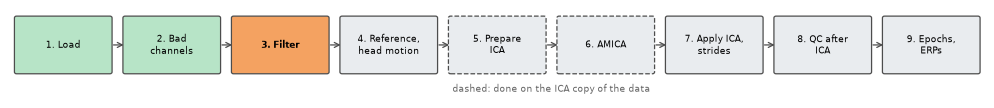

In [21]:
pipeline_map(3)

### The three filters

| Filter | Keeps | Removes | Used for |
|---|---|---|---|
| **high-pass** | the frequencies above its cut-off | the ones below | slow drifts |
| **low-pass** | the frequencies below its cut-off | the ones above | muscles |
| **band-pass** | the frequencies between two cut-offs | the others | both at once |

In MNE, `raw.filter(l_freq, h_freq)` is a high-pass if you give only `l_freq`, a low-pass if you give only `h_freq`, and a band-pass if you
give both. By default MNE uses zero-phase FIR filters: they do not shift the peaks in time (Widmann et al., 2015).

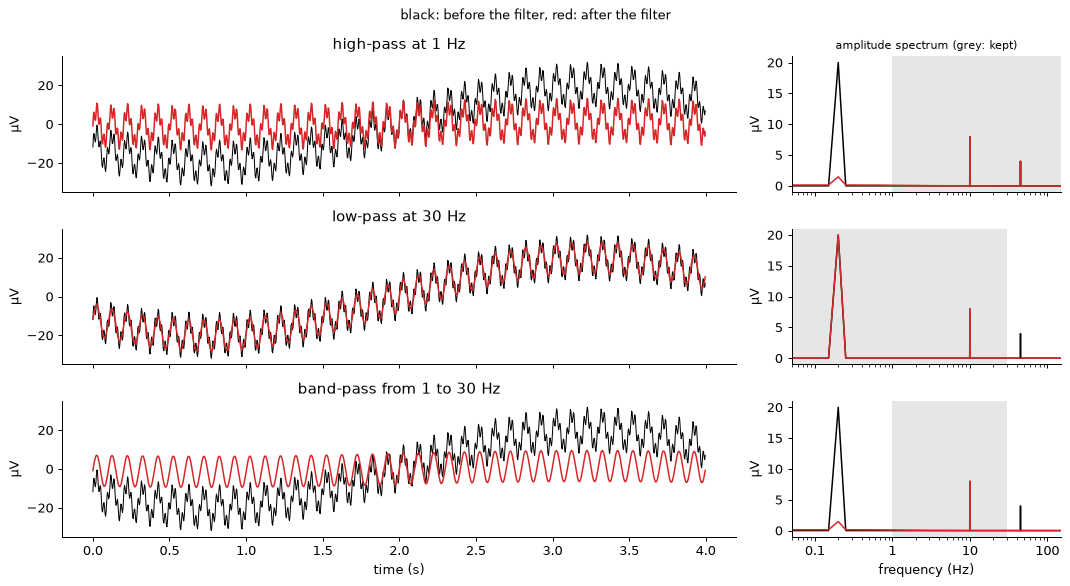

In [22]:
# ---- 3.1 High-pass, low-pass and band-pass on a made-up signal ----------------------------------------------------------------------
sf_demo = 300                                                # samples per second, as in our recordings
t_demo = np.arange(0, 20, 1 / sf_demo)                       # 20 s: the filters need room at the edges
made_up = (20 * np.sin(2 * np.pi * 0.2 * t_demo)             # a slow drift (0.2 Hz) ...
           + 8 * np.sin(2 * np.pi * 10 * t_demo)             # ... an alpha rhythm (10 Hz) ...
           + 4 * np.sin(2 * np.pi * 45 * t_demo))            # ... and fast activity (45 Hz), like that of the muscles (µV)
three_filters = {'high-pass at 1 Hz': (1, None), 'low-pass at 30 Hz': (None, 30), 'band-pass from 1 to 30 Hz': (1, 30)}
shown = (t_demo >= 8) & (t_demo < 12)                        # 4 s from the middle of the signal
freqs_demo = np.fft.rfftfreq(len(t_demo), 1 / sf_demo)[1:]   # the frequencies of the spectrum (0 Hz left out: log scale)

fig, axes = plt.subplots(3, 2, figsize=(12, 6.6), width_ratios=[2.5, 1], sharex='col', sharey='col')
for (ax_time, ax_freq), (label, (l_freq, h_freq)) in zip(axes, three_filters.items()):
    after = mne.filter.filter_data(made_up, sf_demo, l_freq, h_freq)
    ax_time.plot(t_demo[shown] - 8, made_up[shown], color='k', lw=0.8)
    ax_time.plot(t_demo[shown] - 8, after[shown], color='tab:red', lw=1.2)
    ax_time.set(ylabel='µV', title=label)
    ax_freq.axvspan(l_freq or 0.05, h_freq or 150, color='0.9', lw=0)   # grey: the frequencies the filter keeps
    for signal, color in ((made_up, 'k'), (after, 'tab:red')):
        ax_freq.plot(freqs_demo, np.abs(np.fft.rfft(signal))[1:] / len(t_demo) * 2, color=color, lw=1.2)   # the size of each sine
    ax_freq.set(xscale='log', xlim=(0.05, 150), ylabel='µV')
    ax_freq.set_xticks([0.1, 1, 10, 100], ['0.1', '1', '10', '100'])
axes[0, 1].set_title('amplitude spectrum (grey: kept)', fontsize=9)
axes[-1, 0].set_xlabel('time (s)')
axes[-1, 1].set_xlabel('frequency (Hz)')
fig.suptitle('black: before the filter, red: after the filter', fontsize=10)
plt.tight_layout()
plt.show()

**Look.** The made-up signal (black) is the sum of a slow drift (0.2 Hz), an alpha rhythm (10 Hz) and fast activity (45 Hz). On the right,
each of them is one peak of the spectrum. Each filter keeps the frequencies in its grey band and removes the others (red: after the filter):

1. **High-pass at 1 Hz**: the drift is almost gone; the alpha rhythm and the fast activity are kept.
2. **Low-pass at 30 Hz**: the fast activity is gone; the drift and the alpha rhythm are kept.
3. **Band-pass from 1 to 30 Hz**: the drift is almost gone and the fast activity is gone: only the alpha rhythm is left.

### The same filters on the real EEG

Real EEG has the same problems. Cell 3.2 finds two examples in this participant's task (the good channels, as recorded: Pz reference,
no filter yet), and filters each of them:

- **a slow drift**, in 30 s: how much the level of a channel moves between the first and the last 5 s. The largest drifts can be so large
  that the EEG would look like a flat line next to them, so we take a strong one that is not extreme (98 % of the 30-s windows of all
  channels drift less). Filter: a **high-pass at 1 Hz**.
- **muscle activity**, in 5 s: the window with the strongest fast activity (above 30 Hz). Filter: a **low-pass at 30 Hz**.

**These cut-offs are chosen to make the effects easy to see. They are not the filters of our pipeline:** a high-pass at 1 Hz would distort
the slow ERPs (cells 3.4 and 3.5), and our analysis keeps the frequencies up to 100 Hz (cell 3.6).

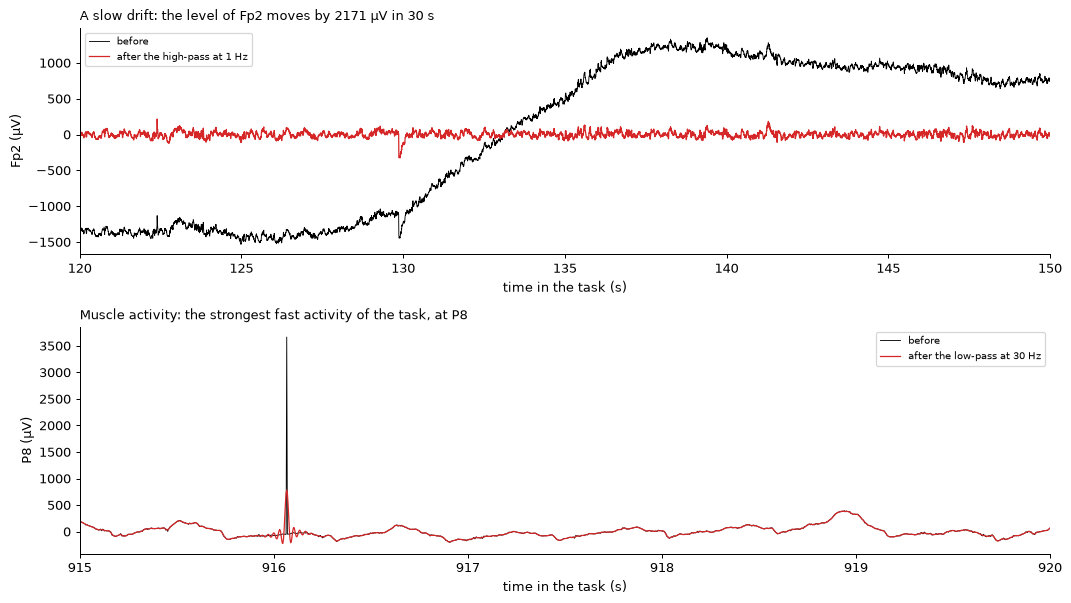

In [23]:
# ---- 3.2 A slow drift and muscle activity in the task, before and after a filter ----------------------------------------------------
task = recordings['task'].copy().pick(good)                  # the good channels of step 2 (Pz left out), as recorded
sfreq = task.info['sfreq']
# Windows that do not cross the junction of two blocks or a data gap (make_fixed_length_epochs leaves those out)
long_windows = mne.make_fixed_length_epochs(task, duration=30, preload=True)                          # 30 s, as recorded
short_windows = mne.make_fixed_length_epochs(task.copy().filter(30, None), duration=5, preload=True)  # 5 s, above 30 Hz only
level = long_windows.get_data() * 1e6                        # windows x channels x samples (µV)
n5 = int(5 * sfreq)
drift = pd.DataFrame(np.abs(level[:, :, -n5:].mean(axis=-1) - level[:, :, :n5].mean(axis=-1)), columns=good,
                     index=(long_windows.events[:, 0] - task.first_samp) / sfreq).stack()     # mean of the last 5 s - first 5 s
muscle = pd.DataFrame(short_windows.get_data().std(axis=-1) * 1e6, columns=good,
                      index=(short_windows.events[:, 0] - task.first_samp) / sfreq).stack()   # how strong the fast part is
drift_start, drift_channel = (drift - drift.quantile(0.98)).abs().idxmin()   # a strong drift, but not one of the extreme ones
muscle_start, muscle_channel = muscle.idxmax()                               # the strongest fast activity


def plot_before_after(ax, channel, start, length, l_freq, h_freq, label):
    """One channel of the task from start to start + length (s), before (black) and after (red) a filter. The filter is applied to the
    whole recording, then the window is cut out. Each trace is drawn around its own mean, as raw.plot() does."""
    before = recordings['task'].copy().pick([channel])
    after = before.copy().filter(l_freq, h_freq)
    for data, color, lw, name in ((before, 'k', 0.7, 'before'), (after, 'tab:red', 1.0, f'after the {label}')):
        piece = data.copy().crop(start, start + length)
        y = piece.get_data()[0] * 1e6
        ax.plot(piece.times + start, y - y.mean(), color=color, lw=lw, label=name)
    ax.set(xlim=(start, start + length), xlabel='time in the task (s)', ylabel=f'{channel} (µV)')
    ax.legend(loc='best', fontsize=8)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.8))
plot_before_after(ax1, drift_channel, drift_start, 30, 1.0, None, 'high-pass at 1 Hz')
ax1.set_title(f'A slow drift: the level of {drift_channel} moves by {drift[drift_start, drift_channel]:.0f} µV in 30 s', loc='left',
              fontsize=10)
plot_before_after(ax2, muscle_channel, muscle_start, 5, None, 30.0, 'low-pass at 30 Hz')
ax2.set_title(f'Muscle activity: the strongest fast activity of the task, at {muscle_channel}', loc='left', fontsize=10)
plt.tight_layout()
plt.show()

**Look.** Top: the level of Fp2 moves by about 2,200 µV in 30 s (black), far more than the EEG riding on it. After the high-pass at 1 Hz
(red), the drift is gone and the faster activity stays, with a few sharp spikes. Bottom: while walking, the strongest fast activity of the
task is not muscle activity: it is a single spike of about 3,600 µV at P8, an electrode "pop" (a sudden change of the contact between the
electrode and the skin). After the low-pass at 30 Hz (red), the spike is smaller but still there: a filter only removes frequencies, and
this jump also has energy at the frequencies the filter keeps. Both artifacts are hundreds of times larger than an ERP of a few µV.

Cell 3.3 lets you choose a channel, a moment of the task and one of the three filters. It needs the ipywidgets package, and works only while
the notebook runs.

In [24]:
# ---- 3.3 Explore: any channel, any moment, any of the three filters (only while the notebook runs) ----------------------------------
try:
    from ipywidgets import interact, Dropdown, IntSlider
except ImportError:
    print('This explorer needs the ipywidgets package: pip install ipywidgets')
else:
    FILTERS = {'high-pass at 1 Hz': (1.0, None), 'low-pass at 30 Hz': (None, 30.0), 'band-pass from 1 to 30 Hz': (1.0, 30.0)}
    last_start = int(recordings['task'].times[-1]) - 60      # the latest start that leaves room for 60 s

    @interact(channel=Dropdown(options=good, value=drift_channel, description='channel'),
              filter_name=Dropdown(options=list(FILTERS), description='filter'),
              length=Dropdown(options=[5, 10, 30, 60], value=30, description='seconds'),
              start=IntSlider(value=int(drift_start), min=0, max=last_start, description='start (s)', continuous_update=False))
    def explore(channel, filter_name, length, start):
        fig, ax = plt.subplots(figsize=(12, 3.4))
        plot_before_after(ax, channel, start, length, *FILTERS[filter_name], filter_name)
        plt.show()

interactive(children=(Dropdown(description='channel', index=9, options=('P3', 'C3', 'F3', 'Fz', 'F4', 'C4', 'P…

### The cut-off of the high-pass filter depends on the ERP

The N400 and the LPC (late positive component) are slow waves that last several hundred milliseconds, so they contain the low frequencies
that a high-pass filter removes. A cut-off that is too high **shrinks** them and adds **fake waves of the opposite polarity** around them,
for example a fake negativity before a late positivity, which can be mistaken for an N400 effect. What the literature says:

- Tanner et al. (2015) filtered N400 and P600 (late positivity) data from a sentence-reading task with cut-offs from 0.01 to 1 Hz. Cut-offs of
  0.3 Hz and above produced fake effects of opposite polarity, and cut-offs between 0.01 and 0.1 Hz gave the best statistical power. High-pass
  filters should be applied to the continuous EEG, not to epochs or averaged ERPs.
- Zhang et al. (2024) compared many filters on the ERP CORE data and recommend a high-pass at 0.2 Hz for the N400 and for the P3 (a late
  positivity), with no low-pass filter or a low-pass at 10 Hz or above.

Our pipeline uses a high-pass at 0.1 Hz, at or below these recommendations. Both papers use other filters than MNE's, so take their cut-offs
as a guide, not as exact values.

**Animation 3.4.** The animation filters a made-up ERP (a P2, an N400 and an LPC, in grey) with high-pass filters of increasing cut-off. Press
play, and read in the title the mean amplitude in the N400 window and in the LPC window.

In [25]:
# ---- 3.4 Animation: what a high-pass filter does to the N400 and the LPC ------------------------------------------------------------
sf_demo = 100
t_erp = np.arange(-1, 2, 1 / sf_demo)                        # one trial, from -1 to 2 s


def bump(centre, width, size):
    """A smooth wave of the given size (µV), centred on the given time (s)."""
    return size * np.exp(-((t_erp - centre) / width) ** 2)


erp = bump(0.20, 0.035, 2.0) + bump(0.45, 0.11, -3.0) + bump(0.72, 0.18, 4.0)   # a P2, an N400 and an LPC (slow)
n400_window = COMPONENTS['N400']['window']
lpc_window = COMPONENTS['LPC']['window']
in_n400 = (t_erp >= n400_window[0]) & (t_erp <= n400_window[1])
in_lpc = (t_erp >= lpc_window[0]) & (t_erp <= lpc_window[1])


def high_pass(cutoff):
    """The made-up ERP after a high-pass filter. 60 s of silence on each side leave room for the long filters."""
    room = 60 * sf_demo
    return mne.filter.filter_data(np.r_[np.zeros(room), erp, np.zeros(room)], sf_demo, l_freq=cutoff, h_freq=None)[room:-room]


cutoffs = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]   # high-pass cut-off frequencies (Hz)
filtered = [high_pass(c) for c in cutoffs]

fig, ax = plt.subplots(figsize=(9, 3.8))


def draw(k):
    ax.clear()
    ax.plot(t_erp, erp, color='0.6', lw=3, label='ERP before filtering')
    ax.plot(t_erp, filtered[k], color='tab:red' if cutoffs[k] > 0.3 else 'tab:green', lw=2, label='after the high-pass filter')
    for name, window, shade in [('N400', n400_window, '0.93'), ('LPC', lpc_window, '0.86')]:
        ax.axvspan(*window, color=shade)
        ax.text(np.mean(window), 4.6, name, ha='center', fontsize=9)
    ax.set(xlim=(-0.5, 1.5), ylim=(-4.5, 5.2), xlabel='time from word onset (s)', ylabel='µV')
    ax.set_title(f'High-pass at {cutoffs[k]:g} Hz: N400 window {filtered[k][in_n400].mean():+.1f} µV (true {erp[in_n400].mean():+.1f}), '
                 f'LPC window {filtered[k][in_lpc].mean():+.1f} µV (true {erp[in_lpc].mean():+.1f})', fontsize=9)
    ax.axhline(0, color='0.5', lw=0.6)
    ax.legend(loc='lower right', fontsize=8)


anim = animation.FuncAnimation(fig, draw, frames=len(cutoffs), interval=1200)
show_animation(fig, anim)

**Look.** At 0.1 Hz the filtered ERP (green) is almost the original (grey): the N400 window is −1.9 µV for −1.8 µV, and the LPC window
+1.6 µV for +1.7 µV. From about 0.5 Hz (red) the LPC shrinks, and the filter creates slow fake waves of the opposite polarity around it. The
fake negativity before the LPC adds to the N400, so the N400 window becomes **more** negative than it really is, while the LPC window becomes
smaller: at 1 Hz, −2.3 µV and +1.0 µV. Both amplitudes are wrong, in opposite directions, and the fake waves could be taken for real effects
(Tanner et al., 2015).

### The filter of this pipeline: a band-pass from 0.1 to 100 Hz

From here on we filter the data we analyze, not examples. We keep **one copy** of the data, band-passed from **0.1 to 100 Hz**
(`ANALYSIS_BAND` in cell 0.3):

- **0.1 Hz**: removes the slowest drifts and keeps the N400 and the late positivity (cells 3.4 and 3.5).
- **100 Hz**: keeps the fast activity of the muscles, which ICA needs to find the muscle components (ICLabel looks at the frequencies up to
  100 Hz, step 6). The ERPs do not need a low-pass: the mean amplitude over a time window averages most of the fast activity out (Zhang et
  al., 2024: no low-pass, or one at 10 Hz or above).

In [26]:
# ---- 3.7 Filter the two recordings from 0.1 to 100 Hz -------------------------------------------------------------------------------
analysis_pz = {name: raw.copy().filter(*ANALYSIS_BAND, picks='eeg') for name, raw in recordings.items()}   # "_pz": still referenced to Pz
print(f'Band-pass {ANALYSIS_BAND[0]:g}-{ANALYSIS_BAND[1]:g} Hz:', ', '.join(analysis_pz))

Band-pass 0.1-100 Hz: walk_only, task


## 4. Re-reference to the average, then remove the head movement

**What.** Choose the zero of the voltage. A voltage is always a difference between two points. The DSI-24 measures each electrode
relative to Pz (the online reference), so Pz itself is 0. We change to the **average reference**: from each channel, at each moment,
we subtract the mean of all good channels.

**Why.** With the Pz reference, every channel contains (minus) the activity at Pz, and electrodes close to Pz look small. The average
reference does not favour one electrode, and Pz gets its own signal back. ICLabel (step 6) was also trained on average-referenced data
(Pion-Tonachini et al., 2019). The bad channels must stay out of the average, or their noise would be copied into every channel: this is
why step 2 came first. MNE leaves out the channels listed in `raw.info['bads']` automatically, and it does not change them: P7
keeps its recorded values and stays marked as bad (cell 4.1 checks it).

**Limit.** The average reference assumes the electrodes cover the head well. With 19 electrodes the average is only an approximation of
a true zero, but it is the usual choice.

**How.** `raw.set_eeg_reference('average')` (4.1). Cell 4.2 finds the blinks, and cells 4.3 to 4.5 remove the movement of the head.

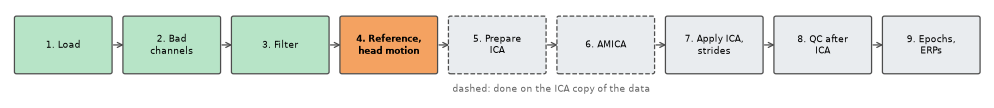

In [27]:
pipeline_map(4)

In [28]:
# ---- 4.1 Re-reference the analysis data to the average of the good electrodes -------------------------------------------------------
print(f'Before: largest absolute value of Pz = {np.abs(analysis_pz["task"].get_data(picks="Pz")).max() * 1e6:.3f} µV')
analysis = {name: raw.copy().set_eeg_reference('average') for name, raw in analysis_pz.items()}
good_all = [ch for ch in analysis['task'].copy().pick('eeg').ch_names if ch not in BAD_CHANNELS]   # good channels, with Pz
total = analysis['task'].get_data(picks=good_all).sum(axis=0)
print(f'After:  Pz varies with SD {analysis["task"].get_data(picks="Pz").std() * 1e6:.1f} µV; '
      f'sum of the {len(good_all)} good channels = {np.abs(total).max() * 1e6:.1e} µV (zero at every sample)')
if BAD_CHANNELS:
    same = all(np.array_equal(analysis_pz[name].get_data(picks=BAD_CHANNELS), analysis[name].get_data(picks=BAD_CHANNELS))
               for name in analysis)
    print(f'Bad channels {analysis["task"].info["bads"]}: still marked, left out of the average, and not changed by it: {same}')

Before: largest absolute value of Pz = 0.000 µV


After:  Pz varies with SD 174.5 µV; sum of the 18 good channels = 7.2e-12 µV (zero at every sample)
Bad channels ['P7']: still marked, left out of the average, and not changed by it: True


20 blinks in the task (1.3 per minute). mne.preprocessing.find_eog_events finds 468 events.


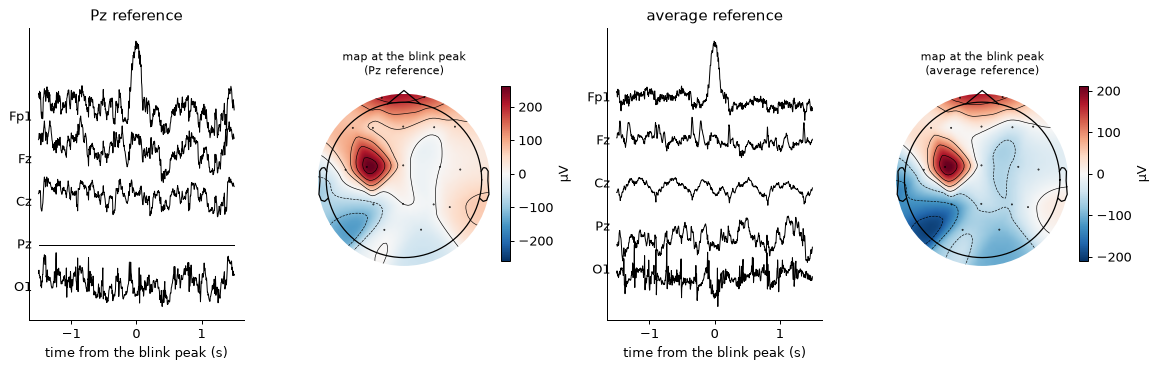

In [29]:
# ---- 4.2 The blinks, and one blink seen with the two references ---------------------------------------------------------------------
def find_blinks(raw):
    """One event per blink of raw, at its peak (sample, 0, 998), as mne.preprocessing.find_eog_events gives them. Fp1 and Fp2 minus
    the median of the other good channels, which cancels what every channel shares (the reference, and the noise of the Pz sensor
    while walking), at 1-10 Hz. A blink raises both: at each sample we keep the smaller of the two, and a blink is a peak of it more
    than BLINK_Z robust standard deviations above its median, at least 0.5 s after the previous one, outside the BAD annotations."""
    eeg = raw.copy().pick(good_all).filter(1, 10)            # each block on its own: the joins are EDGE annotations
    x = eeg.get_data() * 1e6
    eyes = [eeg.ch_names.index(ch) for ch in ['Fp1', 'Fp2'] if ch in eeg.ch_names]
    others = [k for k, ch in enumerate(eeg.ch_names) if ch != 'Pz']
    both = (x[eyes] - np.median(x[others], axis=0)).min(axis=0)
    bad = np.isnan(eeg.get_data(picks=[0], reject_by_annotation='NaN')[0])   # the samples in a BAD annotation
    level = np.median(both[~bad])
    spread = 1.4826 * np.median(np.abs(both[~bad] - level))  # a robust standard deviation
    peaks, _ = find_peaks(np.where(bad, level, both), height=level + BLINK_Z * spread, distance=int(0.5 * raw.info['sfreq']))
    return np.column_stack([peaks + raw.first_samp, np.zeros(len(peaks), int), np.full(len(peaks), 998)])


frontal = [ch for ch in ['Fp1', 'Fp2'] if ch in good_all][0]   # the good electrode closest to the eyes
blink_events = find_blinks(analysis['task'])                 # one event at the peak of each blink of the task
eyes = mne.filter.filter_data(analysis['task'].get_data(picks=[ch for ch in ['Fp1', 'Fp2'] if ch in good_all]), sfreq, 1, 10).min(axis=0)
clearest = blink_events[np.argmax(eyes[blink_events[:, 0] - analysis['task'].first_samp]), 0]
blink = (clearest - analysis['task'].first_samp) / sfreq     # the clearest blink of the task (s)
print(f'{len(blink_events)} blinks in the task ({len(blink_events) / (analysis["task"].times[-1] / 60):.1f} per minute). '
      f'mne.preprocessing.find_eog_events finds {len(mne.preprocessing.find_eog_events(analysis["task"], ch_name=frontal))} events.')
show = ['Fp1', 'Fz', 'Cz', 'Pz', 'O1']
fig = plt.figure(figsize=(13, 4.2))
for col, (label, data) in enumerate([('Pz reference', analysis_pz['task']), ('average reference', analysis['task'])]):
    piece = data.copy().crop(blink - 1.5, blink + 1.5)
    ax = fig.add_subplot(1, 4, 2 * col + 1)
    for k, ch in enumerate(show):
        ax.plot(piece.times - 1.5, piece.get_data(picks=ch)[0] * 1e6 - 120 * k, color='k', lw=0.8)
        ax.text(-1.6, -120 * k, ch, ha='right', va='center')
    ax.set(title=label, xlabel='time from the blink peak (s)', yticks=[])
    peak = data.copy().pick(good_all).crop(blink, blink)    # all good channels at the blink peak
    ax = fig.add_subplot(1, 4, 2 * col + 2)
    im, _ = mne.viz.plot_topomap(peak.get_data()[:, 0] * 1e6, peak.info, axes=ax, show=False, cmap='RdBu_r')
    plt.colorbar(im, ax=ax, shrink=0.6, label='µV')
    ax.set_title(f'map at the blink peak\n({label})', fontsize=9)
plt.tight_layout()
plt.show()

**Look.** `find_blinks` finds 20 blinks in the 15.9 min of the task, 1.3 per minute: few blinks during a task with a word every 2 to 3
s (cell 5.2 also counts those of the walk without the task). MNE's `find_eog_events` finds 468 events instead. It takes the polarity
and the threshold of a blink from the largest value of the recording, and while walking that value is an electrode pop, not a blink, so
most of its events are the steps and the noise of single electrodes. `find_blinks` asks Fp1 and Fp2 to rise together, against the median
of the other channels: a step or a pop on one electrode, or the noise of the Pz sensor that every channel carries, does not count.

The figure shows the clearest blink of the task with the two references: the sharp wave of Fp1, and at the front of the maps the
positive values of Fp1 and Fp2. The large spot at C3 at the same moment is not the blink: C3 has large noise of its own (cell 6.6). With
the Pz reference every channel also carries the noise of the Pz sensor, which walking makes large; the average reference spreads it
thinly over the channels and gives Pz its own signal back (cell 4.1).

### The movement of the head: a regression on the accelerometer

**What.** At every step the head is shaken, and the electrodes move with it on the skin (cell 1.7). The headset measures its own
acceleration. For each good channel, we predict from the acceleration the part of the signal that follows the movement, and subtract it.

**Why here.** After the bad channels and the filter, before ICA. Mobile pipelines that clean with signals recorded beside the EEG work in
this order: Gonsisko et al. (2023) reject the bad channels, then clean with noise electrodes, then run ICA. The acceleration of the head,
used as such a reference signal (in an adaptive filter), removed movement artifacts during walking (Kilicarslan & Contreras-Vidal, 2019,
in the review of Gorjan et al., 2022). ICA then learns from data that the steps no longer drive. The average reference does not change the result: the regression treats each channel on its own and is
linear, so with the same settings it gives the same channels before or after the reference.

**How** (cells 4.3 and 4.4). The acceleration is put on the time axis of the EEG: the three axes of the headset and the size of the
acceleration, from 0.5 to 12 Hz. Each channel is regressed on the acceleration now and up to 200 ms before, because an artifact follows
the movement and never precedes it. One regression per minute, because the way the head moves the electrodes drifts, with a penalty
(ridge regression) that keeps the weights of the nearly identical delayed copies small. Every fourth block of 5 s is held out: the
penalty is the one that best predicts these held-out data, and a recording is cleaned only if the regression explains at least 2 % of
their variance. Otherwise it would remove chance, not movement.

**Limits.** The acceleration of the head explains only part of the movement artifact: about 14 % in gel electrodes isolated from the brain
(Kline et al., 2015). An accelerometer with 30 samples per second says nothing above 15 Hz. And brain activity locked to the steps, if
there is any, would be removed with the artifact.

walk_only  533 steps, one every 0.57 s (median); the accelerometer covers 100 % of the samples
block1     449 steps, one every 0.57 s (median); the accelerometer covers 100 % of the samples
block2     417 steps, one every 0.57 s (median); the accelerometer covers 100 % of the samples
block3     383 steps, one every 0.57 s (median); the accelerometer covers 100 % of the samples
block4     446 steps, one every 0.57 s (median); the accelerometer covers 100 % of the samples


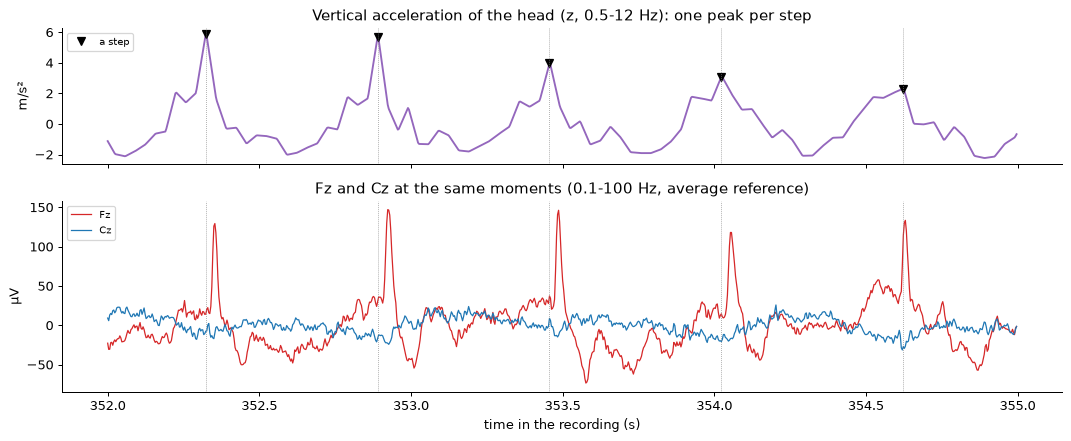

In [30]:
# ---- 4.3 The head accelerometer, on the time axis of the EEG ---------------------------------------------------------------------------
MOTION_DIR = EEG_DIR.parent / 'motion'                       # the accelerometer of the headset: one file per recording
started = pd.read_csv(EEG_DIR.parent / f'sub-{SUBJECT}_ses-001_scans.tsv', sep='\t')   # when each file of the session started
started = dict(zip(started['filename'], pd.to_datetime(started['acq_time'])))


def head_acceleration(name):
    """The acceleration of the head during recording `name`, on the samples of cut_raws[name]: the three axes of the headset (x
    forward-back, y left-right, z up) and the size of the acceleration (m/s²), band-passed ACCEL_BAND; NaN where the accelerometer has
    no sample. Its file gives the time of each sample after its first one; scans.tsv gives when that first sample was taken."""
    eeg_file = bids_file(name, 'eeg.vhdr')
    motion_file = MOTION_DIR / eeg_file.name.replace('_acq-', '_tracksys-DSI24_acq-').replace('_eeg.vhdr', '_motion.tsv')
    motion = pd.read_csv(motion_file, sep='\t', header=None, names=['x', 'y', 'z', 'time'])
    delay = (started[f'motion/{motion_file.name}'] - started[f'eeg/{eeg_file.name}']).total_seconds()   # its start, on the EEG clock
    times = delay + motion['time'].to_numpy() - (cut_raws[name].first_time - raws[name].first_time)    # s from the start of the cut
    acc = motion[['x', 'y', 'z']].to_numpy().T
    acc = np.vstack([acc, np.linalg.norm(acc, axis=0)])      # + the size of the acceleration, whatever the tilt of the head
    acc = mne.filter.filter_data(acc - acc.mean(axis=1, keepdims=True), 30.0, *ACCEL_BAND)   # 30 samples per second
    return np.array([np.interp(cut_raws[name].times, times, a, left=np.nan, right=np.nan) for a in acc])


acceleration = {name: head_acceleration(name) for name in cut_raws}
steps = {name: find_peaks(np.nan_to_num(acc[2]), distance=int(0.35 * sfreq), prominence=0.5 * np.nanstd(acc[2]))[0]
         for name, acc in acceleration.items()}              # one peak of the vertical acceleration (z) per step
for name in cut_raws:
    print(f'{name:9s} {len(steps[name]):4d} steps, one every {np.median(np.diff(steps[name])) / sfreq:.2f} s (median); the accelerometer '
          f'covers {100 * np.isfinite(acceleration[name][0]).mean():.0f} % of the samples')

offset = cut_raws['walk_only'].first_time - raws['walk_only'].first_time   # where the cut walk starts in its file (s)
k0, k1 = int((352.0 - offset) * sfreq), int((355.0 - offset) * sfreq)      # the three seconds of steps of cell 1.7
t = analysis['walk_only'].times[k0:k1] + offset             # time in the recording, as in cell 1.7
inside = steps['walk_only'][(steps['walk_only'] >= k0) & (steps['walk_only'] < k1)]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, height_ratios=[1, 1.4])
ax1.plot(t, acceleration['walk_only'][2, k0:k1], color='tab:purple')
ax1.plot(inside / sfreq + offset, acceleration['walk_only'][2, inside], 'v', color='k', label='a step')
ax1.set(ylabel='m/s²', title=f'Vertical acceleration of the head (z, {ACCEL_BAND[0]:g}-{ACCEL_BAND[1]:g} Hz): one peak per step')
ax1.legend(loc='upper left', fontsize=8)
for ch, color in (('Fz', 'tab:red'), ('Cz', 'tab:blue')):
    y = analysis['walk_only'].get_data(picks=ch)[0, k0:k1] * 1e6
    ax2.plot(t, y - y.mean(), color=color, lw=1, label=ch)
for s in inside / sfreq + offset:
    for ax in (ax1, ax2):
        ax.axvline(s, color='0.5', lw=0.6, ls=':')
ax2.set(xlabel='time in the recording (s)', ylabel='µV', title='Fz and Cz at the same moments (0.1-100 Hz, average reference)')
ax2.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

In [31]:
# ---- 4.4 Regress the head acceleration out of every good channel, one recording at a time ---------------------------------------------
lags = np.round(ACCEL_LAGS_S * sfreq).astype(int)            # the delays, in samples


def delayed(acc):
    """The acceleration and its delayed copies: one row per signal and delay, NaN where the delayed copy does not exist."""
    rows = []
    for lag in lags:
        copy = np.full_like(acc, np.nan)
        copy[:, lag:] = acc[:, :acc.shape[1] - lag]
        rows.append(copy)
    return np.vstack(rows)


def predicted(X, Y, fit, alpha):
    """What X predicts of each row of Y: a ridge regression fitted on the samples `fit` of each ACCEL_WINDOW_S window (half
    overlapping), the windows blended with a Hann taper. The penalty alpha is relative to the size of X."""
    n, win = Y.shape[1], int(ACCEL_WINDOW_S * sfreq)
    total, weight = np.zeros_like(Y), np.zeros(n)
    for start in sorted(set(range(0, max(n - win, 0) + 1, win // 2)) | {max(n - win, 0)}):
        x, y, use = X[:, start:start + win], Y[:, start:start + win], fit[start:start + win]
        if use.sum() < 10 * len(x):                          # too few samples to fit this window
            continue
        mx, my = x[:, use].mean(axis=1, keepdims=True), y[:, use].mean(axis=1, keepdims=True)
        gram = (x[:, use] - mx) @ (x[:, use] - mx).T
        weights = np.linalg.solve(gram + alpha * np.trace(gram) / len(gram) * np.eye(len(gram)), (x[:, use] - mx) @ (y[:, use] - my).T)
        taper = np.hanning(y.shape[1] + 2)[1:-1]
        total[:, start:start + win] += taper * (weights.T @ np.nan_to_num(x - mx))
        weight[start:start + win] += taper
    return total / np.maximum(weight, 1e-12)


before_motion = {name: raw.copy() for name, raw in analysis.items()}   # kept for the figures (4.5, 7.4)
motion_rows = []
for part, (recording, first) in PARTS.items():
    raw, n = analysis[recording], cut_raws[part].n_times
    X = delayed(acceleration[part])                          # 4 signals × 11 delays
    Y = raw.get_data(picks=good_all, start=first, stop=first + n) * 1e6   # the good channels, Pz included (µV)
    ok = (np.isfinite(X).all(axis=0)                          # the acceleration is known, and the sample is not in a BAD annotation
          & ~np.isnan(raw.get_data(picks=good_all[0], start=first, stop=first + n, reject_by_annotation='NaN')[0]))
    held_out = (np.arange(n) // int(5 * sfreq)) % 4 == 0     # every 4th block of 5 s: not used to fit, used to judge
    explained = {}
    for alpha in ACCEL_ALPHAS:
        error = Y - predicted(X, Y, ok & ~held_out, alpha)
        explained[alpha] = 1 - error[:, ok & held_out].var(axis=1).sum() / Y[:, ok & held_out].var(axis=1).sum()
    alpha = max(explained, key=explained.get)                # the penalty that best predicts the held-out data
    applied = explained[alpha] >= ACCEL_MIN_GAIN
    if applied:                                              # fitted again on all the samples, and subtracted
        correction = np.zeros((len(good_all), raw.n_times))
        correction[:, first:first + n] = predicted(X, Y, ok, alpha) * 1e-6
        raw.apply_function(lambda x: x - correction, picks=good_all, channel_wise=False)
    motion_rows.append(dict(recording=part, penalty=alpha, held_out_variance_explained_pct=round(100 * explained[alpha], 1),
                            applied=applied))
motion_table = pd.DataFrame(motion_rows).set_index('recording')
motion_table

,penalty,held_out_variance_explained_pct,applied
recording,,,
walk_only,0.01,8.7,True
block1,0.10,0.8,False
block2,1.00,0.7,False
block3,0.01,30.5,True
block4,0.01,26.4,True


The average step (RMS over its 0.6 s): median of the good channels 8.5 µV before the regression, 4.2 µV after; at Fz, 28.8 µV before, 9.9 µV after


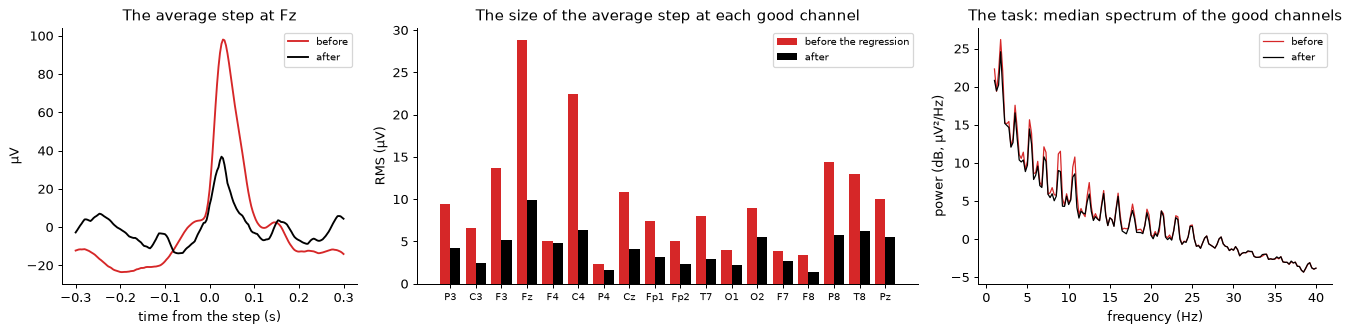

In [32]:
# ---- 4.5 What the regression removed: the average step, and the spectrum -------------------------------------------------------------
def average_step(data):
    """The average of data around the steps of all the walking recordings (-0.3 to 0.3 s from the peak of the vertical acceleration),
    each channel around its mean."""
    evokeds = []
    for recording, raw in data.items():
        samples = np.concatenate([steps[part] + first for part, (rec, first) in PARTS.items() if rec == recording])
        events = np.column_stack([samples + raw.first_samp, np.zeros(len(samples), int), np.ones(len(samples), int)])
        evokeds.append(mne.Epochs(raw, events, tmin=-0.3, tmax=0.3, baseline=(None, None), picks=good_all, preload=True).average())
    return mne.combine_evoked(evokeds, weights='nave')


step_before, step_after = average_step(before_motion), average_step(analysis)
size = pd.DataFrame({'before': np.sqrt((step_before.data ** 2).mean(axis=1)), 'after': np.sqrt((step_after.data ** 2).mean(axis=1))},
                    index=step_before.ch_names) * 1e6         # the size of the average step at each channel (RMS, µV)
worst = size['before'].idxmax()
print(f'The average step (RMS over its 0.6 s): median of the good channels {size["before"].median():.1f} µV before the regression, '
      f'{size["after"].median():.1f} µV after; at {worst}, {size.loc[worst, "before"]:.1f} µV before, {size.loc[worst, "after"]:.1f} µV after')

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3.8), width_ratios=[1, 1.7, 1.2])
for evoked, color, label in ((step_before, 'tab:red', 'before'), (step_after, 'k', 'after')):
    ax1.plot(evoked.times, evoked.get_data(picks=worst)[0] * 1e6, color=color, label=label)
ax1.set(xlabel='time from the step (s)', ylabel='µV', title=f'The average step at {worst}')
ax1.legend(fontsize=8)
x = np.arange(len(size))
ax2.bar(x - 0.2, size['before'], 0.4, color='tab:red', label='before the regression')
ax2.bar(x + 0.2, size['after'], 0.4, color='k', label='after')
ax2.set(xticks=x, ylabel='RMS (µV)', title='The size of the average step at each good channel')
ax2.set_xticklabels(size.index, fontsize=8)
ax2.legend(fontsize=8)
for label, data, color in (('before', before_motion['task'], 'tab:red'), ('after', analysis['task'], 'k')):
    psd = data.compute_psd(fmin=1, fmax=40, picks=good_all, n_fft=int(4 * sfreq))   # 4-s windows: 0.25 Hz resolution
    ax3.plot(psd.freqs, 10 * np.log10(np.median(psd.get_data(), axis=0) * 1e12), color=color, lw=1, label=label)
ax3.set(xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title='The task: median spectrum of the good channels')
ax3.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Look.** The vertical acceleration of the head has one sharp peak per step, 0.57 s apart (cell 4.3: about 1.8 steps per second, 383
to 533 steps per recording), and the sharp wave of Fz follows each peak by a few tens of milliseconds. These peaks are the steps every
later check uses (they all fall within 0.15 s of the heel contacts measured in the Brain Walk project).

The table of cell 4.4 says where the regression was worth it. In blocks 3 and 4 it explains 30.5 % and 26.4 % of the variance of the
held-out data, and in the walk without the task 8.7 %; in blocks 1 and 2, below 1 %, so these two blocks are left as they were: there,
the acceleration does not predict the EEG well enough, and subtracting its prediction would remove chance. The penalty chosen is the
smallest (0.01) wherever the regression is applied.

Cell 4.5 averages the data around the steps of all the recordings. Before the regression the average step is a sharp wave of about
100 µV at **Fz**; after it, about a third of that. Over the good channels, the size of the average step falls from 8.5 to 4.2 µV
(median). The spectrum (right) shows the steps as a comb of peaks every 1.8 Hz up to about 30 Hz; the regression lowers the peaks without
touching the frequencies between them. Part of the steps stays: what does not follow the acceleration of the head (the contact of each
electrode with the skin, the neck muscles), and what was faster than an accelerometer with 30 samples per second can measure.

## 5. Prepare the data used to train ICA

**What.** Make two copies of the analysis data, now cleaned of the head movement: the **ICA copy**, high-passed at 2 Hz, which AMICA
learns from, and the **ICLabel copy**, 1–100 Hz, which ICLabel reads (step 6). On the ICA copy only, mark the few periods that ICA should
not learn from.

**Why a copy at 2 Hz.** ICA (step 6) needs the opposite of what the ERPs need. Slow drifts make the sources look less independent (they
all go up and down with the drift), and this makes it harder for ICA to find a good solution (MNE documentation). For mobile data the
cut-off can be higher than the usual 1 Hz: Klug & Gramann (2021) recommend up to 2 Hz, and Gorjan et al. (2022) about 1.5 Hz for slow to
normal walking and 2 Hz or more for faster movements. Our copy keeps half its amplitude at 2 Hz. But 2 Hz is far above what the N400 and
the LPC tolerate (cell 3.5), so the analysis data keep 0.1–100 Hz for the ERPs, and the ICA copy is used **only** to train ICA. ICLabel was
trained on data filtered at 1–100 Hz, so it gets its own copy. Step 7 applies the ICA solution to the analysis data the copies came from.

**Why leave so little out.** ICA assumes that the sources mix in the same way during the whole recording, and a few huge, unusual artifacts
can capture components of their own. AMICA deals with them itself: while it learns, it rejects the samples its model cannot explain, and a
moderate amount of this rejection (5 to 10 passes) improves the decomposition whatever the movement (Klug et al., 2024). So on the ICA copy
we only mark the QC periods where a channel lost contact or the whole scalp was abnormal; the large amplitudes on one channel stay, for
AMICA to judge. The blinks stay too: ICA must see them to learn the blink component.

**How.** `raw.filter(2.5, 100, l_trans_bandwidth=1)` makes the ICA copy (pass band from 2.5 Hz, half amplitude at 2 Hz) and
`raw.filter(1, 100)` the ICLabel copy. The QC annotations of step 2 come along. On the ICA copy only, each period left out gets a second
annotation starting with `BAD_ICA_` (`QC_contact` gives `BAD_ICA_contact`), without `ch_names`, because ICA uses all the channels at once.
The 2-s pieces that AMICA learns from (cell 6.2) skip these periods without deleting any sample. The analysis data never get a `BAD_ICA_`
annotation: they keep their QC annotations and their complete time axis.

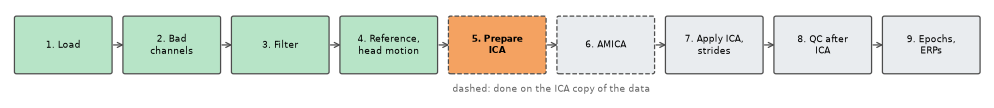

In [33]:
pipeline_map(5)

In [34]:
# ---- 5.0 The ICA copy (from 2 Hz) and the ICLabel copy (1-100 Hz) of the analysis data ------------------------------------------------
# The analysis data already stop at 100 Hz, are average-referenced and cleaned of the head movement: what this adds is the high-pass
ica_copy = {name: raw.copy().filter(*ICA_BAND, l_trans_bandwidth=ICA_L_TRANS, picks='eeg') for name, raw in analysis.items()}
iclabel_copy = {name: raw.copy().filter(*ICLABEL_BAND, picks='eeg') for name, raw in analysis.items()}
print(f'ICA copy, half amplitude at {ICA_BAND[0] - ICA_L_TRANS / 2:g} Hz, used only to train AMICA; ICLabel copy {ICLABEL_BAND[0]:g}-'
      f'{ICLABEL_BAND[1]:g} Hz:', ', '.join(ica_copy))

ICA copy, half amplitude at 2 Hz, used only to train AMICA; ICLabel copy 1-100 Hz: walk_only, task


In [35]:
# ---- 5.1 The QC periods ICA should not learn from: BAD_ICA_ annotations, on the ICA copy only ---------------------------------------
held_out = (qc_table['description'] == 'QC_contact') | (qc_table['channels'] == 'all')   # a lost contact, or the whole scalp: the large
                                                             # amplitudes of one channel are left to AMICA's own rejection (step 6)
qc_table['held out from ICA'] = held_out
for raw in ica_copy.values():                                # (running this cell again adds nothing twice)
    raw.annotations.delete([i for i, d in enumerate(raw.annotations.description) if d.startswith('BAD_ICA_')])
for p in qc_table[held_out].itertuples():
    raw = ica_copy[p.recording]
    raw.annotations.append(onset=raw.first_time + p.onset, duration=p.duration,
                           description='BAD_ICA_' + p.description.removeprefix('QC_'))   # no ch_names: ICA uses all the channels at once
ica_training = mne.concatenate_raws([raw.copy() for raw in ica_copy.values()])   # walking without the task + task
held_s = sum(a['duration'] for a in ica_training.annotations if a['description'].startswith('BAD_ICA_'))
print(f'{held_out.sum()} of {len(qc_table)} QC periods left out of ICA training: {held_s:.0f} s of the {ica_training.times[-1]:.0f} s of '
      f'the ICA copy. The analysis data keep their QC annotations, and every sample.')
qc_table[held_out].round(2)

0 of 46 QC periods left out of ICA training: 0 s of the 1252 s of the ICA copy. The analysis data keep their QC annotations, and every sample.


,recording,part,onset,duration,description,channels,ratio,held out from ICA


**Look.** None of the 46 QC periods is left out of ICA training: no channel lost contact and no window is abnormal on the whole scalp. The
large amplitudes of single channels (Pz, C4, Fz...) stay in the training data, and AMICA rejects, while it learns, the samples it cannot
explain (cell 6.2). The table is therefore empty. The analysis data keep their 46 `QC_large_amplitude` annotations and every sample.

In [36]:
# ---- 5.2 Are the blinks still in the training data, and is there enough data for ICA? -----------------------------------------------
blink_times = find_blinks(ica_training)[:, 0] / sfreq        # the time of each blink (s): the walk, then the task
held_periods = [(a['onset'], a['onset'] + a['duration']) for a in ica_training.annotations if a['description'].startswith('BAD_ICA_')]
inside = sum(any(start <= t < end for start, end in held_periods) for t in blink_times)
print(f'{len(blink_times)} blinks in the ICA copy, {inside} of them in a period left out: AMICA learns from {len(blink_times) - inside}')
n_kept = ica_training.get_data(picks=good_all[0], reject_by_annotation='omit').shape[1]   # the samples outside every BAD annotation
n_channels = len(good_all)
print(f'{n_kept:,} samples for ICA ({n_kept / sfreq / 60:.1f} min), {n_kept // AMICA_DECIM:,} of them for AMICA (one in {AMICA_DECIM}); '
      f'the rule of thumb asks for at least {30 * n_channels ** 2:,} (30 × {n_channels}²)')

77 blinks in the ICA copy, 0 of them in a period left out: AMICA learns from 77
372,646 samples for ICA (20.7 min), 186,323 of them for AMICA (one in 2); the rule of thumb asks for at least 9,720 (30 × 18²)


## 6. ICA: find the eye, muscle and single-electrode components

**What.** Each electrode records a **mixture** of many sources: brain areas, eye movements, muscles, electrodes that move on the skin.
Independent component analysis (ICA) finds weights that **unmix** the channels into components, assuming the sources are statistically
independent and not Gaussian (Makeig et al., 1996; Hyvärinen & Oja, 2000). Each component has:

- a **topography**: how strongly it appears at each electrode (where it is);
- a **time course**: its activity over time (when it is active).

In matrix form: **channels = A × components**. `A` is the **mixing matrix**: its column *k* is the topography of component *k*. ICA estimates the
**unmixing matrix** `W`, the weights: **components = W × channels**. `A` and `W` combine the electrodes at one moment at a time: they know nothing
about the time course or the frequencies of the signal (step 7 uses this).

**Why.** We can then remove the eye, muscle and electrode components and keep the others, instead of throwing away every trial that
contains a blink or a shaken electrode.

**Which ICA: AMICA.** The seated notebook uses Picard (Ablin et al., 2018), a fast algorithm set up like extended Infomax. Walking data
hold more kinds of artifacts, and mobile EEG studies mostly use **AMICA**, adaptive mixture ICA (Palmer et al., 2011). AMICA learns the
shape of each source's distribution instead of assuming it, and among 22 algorithms compared on the same EEG it gave the components that
looked most like brain sources (Delorme et al., 2012; Gorjan et al., 2022). While it learns, it also rejects the samples it cannot explain
(step 5): 10 passes at 3 standard deviations here, the moderate cleaning that Klug et al. (2024) recommend for mobile data. We use
`jamica`, a Python version of AMICA that returns an MNE `ICA` object (Esmaeili et al., 2026), so everything after it is the usual MNE code.
AMICA is slower than Picard: 500 iterations on one sample in two take about 2 minutes on a recent laptop (cell 6.2). Klug et al.
(2024) used 2000 iterations on every sample, about 20 minutes here, and for this participant the same components come out. On Google
Colab, a GPU runtime makes AMICA much faster.

**How many components?** As many as there are independent signals in the data, the **rank** of the good channels: here 18 electrodes (the 19 minus the flat P7; Pz counts, it has a signal since step 4),
minus 1 lost to the average reference (the channels sum to zero, so the last one is known from the others) = **17**. Cell 6.2 asks MNE
for this rank instead of counting.

**How.** `fit_ica(pieces, n_components, max_iter, ...)` from `jamica`, on 2-s pieces of the ICA copy: the pieces skip the `BAD_ICA_`
periods of step 5.

**Which components to remove.** Cells 6.5 to 6.8 collect the evidence for each component and apply the rule of the Brain Walk analyses,
and cell 6.9 checks the decision on a copy before step 7 applies it.

**Animation 6.1.** First, ICA on a made-up example with two sources (blinks and an alpha rhythm) recorded by two electrodes.

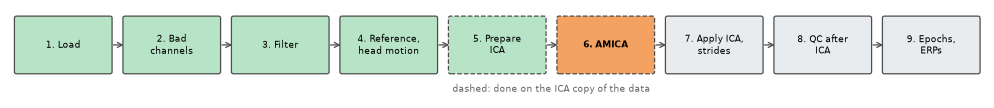

In [37]:
pipeline_map(6)

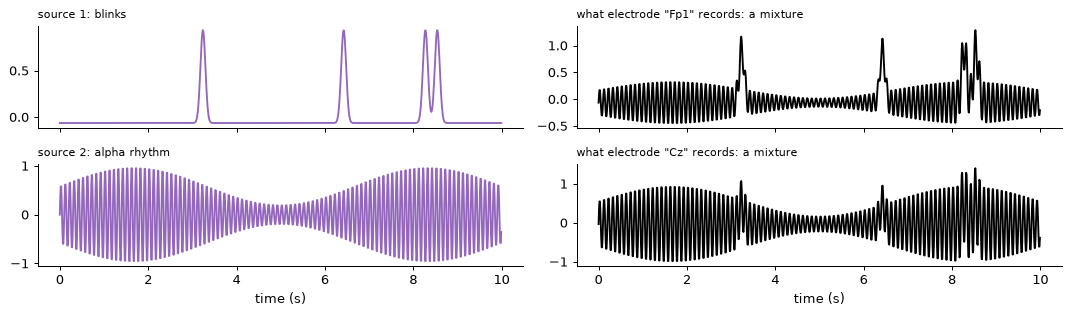

In [38]:
# ---- 6.1 How ICA unmixes: two sources, two electrodes --------------------------------------------------------------------------------
rng = np.random.default_rng(1)
sf_demo = 100
t_demo = np.arange(0, 20, 1 / sf_demo)                       # 20 s at 100 Hz
blinks = sum(np.exp(-((t_demo - b) / 0.08) ** 2) for b in rng.uniform(0.5, 19.5, 9))   # source 1: blinks, rare large peaks
alpha = np.sin(2 * np.pi * 10 * t_demo) * (0.6 + 0.4 * np.sin(2 * np.pi * 0.15 * t_demo))   # source 2: a 10 Hz rhythm
sources = np.vstack([blinks - blinks.mean(), alpha])
mixing = np.array([[1.0, 0.4],                               # "Fp1" records a lot of the blinks and a little alpha
                   [0.5, 1.0]])                              # "Cz" records some blinks and a lot of alpha
recorded = mixing @ sources

# ICA, part 1: whitening. The two channels are made uncorrelated, with the same variance.
centred = recorded - recorded.mean(axis=1, keepdims=True)
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(centred))
white = eigenvectors @ np.diag(eigenvalues ** -0.5) @ eigenvectors.T @ centred


# ICA, part 2: turn the whitened data until the two outputs are as far from Gaussian as possible.
def rotate(angle):
    a = np.deg2rad(angle)
    return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]]) @ white


angles = np.arange(0, 180, 1)
non_gaussian = np.array([np.abs(kurtosis(rotate(a), axis=1)).sum() for a in angles])   # |kurtosis|: 0 for a Gaussian signal

fig, axes = plt.subplots(2, 2, figsize=(12, 3.6), sharex=True)
for k, (src, rec, ch) in enumerate(zip(sources, recorded, ['Fp1', 'Cz'])):
    axes[k, 0].plot(t_demo[:1000], src[:1000], color='tab:purple')
    axes[k, 0].set_title(f'source {k + 1}: {"blinks" if k == 0 else "alpha rhythm"}', fontsize=9, loc='left')
    axes[k, 1].plot(t_demo[:1000], rec[:1000], color='k')
    axes[k, 1].set_title(f'what electrode "{ch}" records: a mixture', fontsize=9, loc='left')
axes[1, 0].set_xlabel('time (s)')
axes[1, 1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

In [39]:
# ---- 6.1 (continued) Animation: ICA turns the data until the outputs are independent ------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.6), width_ratios=[1, 1.8, 1.2])
frames = list(range(0, 91, 6))                               # turning by 90° only swaps the two outputs


def draw(k):
    angle = frames[k]
    outputs = rotate(angle)
    for ax in (ax1, ax2, ax3):
        ax.clear()
    ax1.scatter(outputs[0, ::3], outputs[1, ::3], s=2, color='0.4')
    ax1.set(xlim=(-4, 7), ylim=(-4, 7), xlabel='output 1', ylabel='output 2', title='the data, turned', aspect='equal')
    ax2.plot(t_demo[:1000], outputs[0, :1000] + 4, color='tab:blue')
    ax2.plot(t_demo[:1000], outputs[1, :1000] - 2, color='tab:orange')
    ax2.set(yticks=[], xlabel='time (s)', title='the two outputs')
    ax3.plot(angles[angles <= 90], non_gaussian[angles <= 90], color='k')
    ax3.axvline(angle, color='tab:red')
    ax3.set(xlabel='rotation (degrees)', ylabel='non-Gaussianity', title=f'rotation {angle}°')


anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=400)
show_animation(fig, anim)
best = angles[np.argmax(non_gaussian)]
print(f'Most non-Gaussian rotation: {best}°. At that angle, output 1 and output 2 are the blinks and the alpha rhythm again.')

Most non-Gaussian rotation: 6°. At that angle, output 1 and output 2 are the blinks and the alpha rhythm again.


**Look.** At most angles each output is still a mixture of blinks and alpha. When the non-Gaussianity curve (right) reaches a peak,
one output contains only the blinks and the other only the alpha rhythm: ICA has recovered the sources without knowing them. AMICA does
the same in as many dimensions as there are components (cell 6.2), with a more flexible model of each source.

In [40]:
# ---- 6.2 Fit AMICA on the ICA copy, without its BAD_ICA_ periods (a few minutes) -----------------------------------------------------
# As many components as the rank of the good, average-referenced channels (a relative tolerance: the default one sometimes counts the
# 1e-15 noise left by the average reference)
n_components = mne.compute_rank(ica_training, tol=1e-6, tol_kind='relative')['eeg']
print(f'{len(good_all)} good channels (left out: {BAD_CHANNELS}); the rank of the data, so the number of components: {n_components}')
pieces = mne.make_fixed_length_epochs(ica_training, duration=2.0, preload=True)   # 2-s pieces, without the BAD_ICA_ periods and the gaps
start = time.time()
ica = fit_ica(pieces, n_components=n_components, max_iter=AMICA_MAX_ITER, num_mix=3, decim=AMICA_DECIM, random_state=ICA_SEED,
              fit_params=AMICA_REJECT)               # num_mix: the distribution of each source is a mixture of 3 shapes
kept_samples = ica.amica_result_.sample_mask_                # True: a sample AMICA kept, False: one it rejected while learning
print(f'AMICA: {AMICA_MAX_ITER} iterations in {(time.time() - start) / 60:.1f} min, on {len(pieces) * 2 / 60:.1f} min of the ICA copy '
      f'(one sample in {AMICA_DECIM}); it rejected {100 * (1 - kept_samples.mean()):.1f} % of these samples as ones it cannot explain')
print(ica)

18 good channels (left out: ['P7']); the rank of the data, so the number of components: 17


AMICA: 500 iterations in 1.5 min, on 20.4 min of the ICA copy (one sample in 2); it rejected 6.4 % of these samples as ones it cannot explain
<ICA | epochs decomposition, method: amica (fit in 500 iterations on 183600 samples), 17 ICA components (18 PCA components available), channel types: eeg, no sources marked for exclusion>


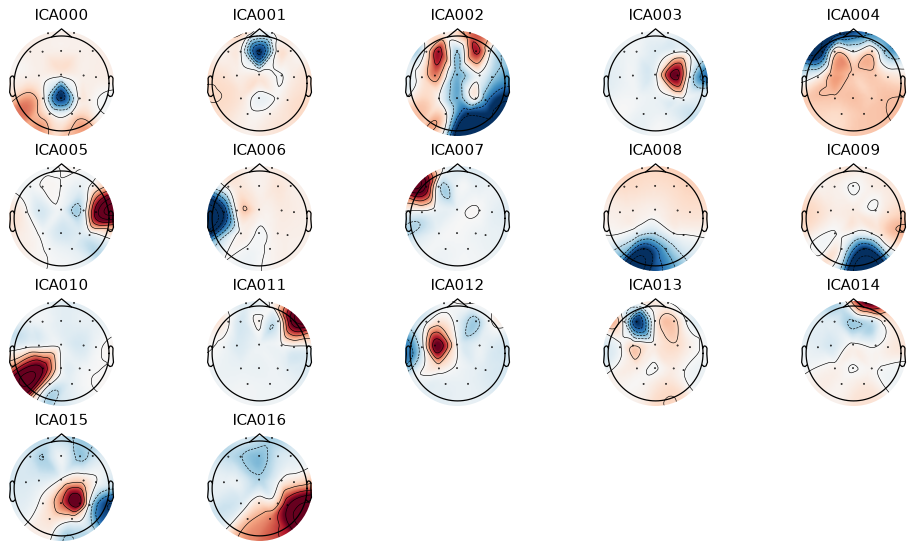

In [41]:
# ---- 6.3 The topographies of the components ----------------------------------------------------------------------------------------
fig = ica.plot_components(show=False)
fig.set_size_inches(11, 6)
plt.show()

**Look.** A blink component has a strong, symmetric topography at the front (Fp1, Fp2). A horizontal eye movement component is
opposite on the left and right at the front (F7 against F8, or Fp1 against Fp2). A muscle component is often concentrated on one electrode at the edge of
the cap (temporal or frontal). Brain components often have smooth topographies, with one positive and one negative area. While
walking, many components are one spot on one electrode: an electrode that moves on the skin on its own (cell 6.6).

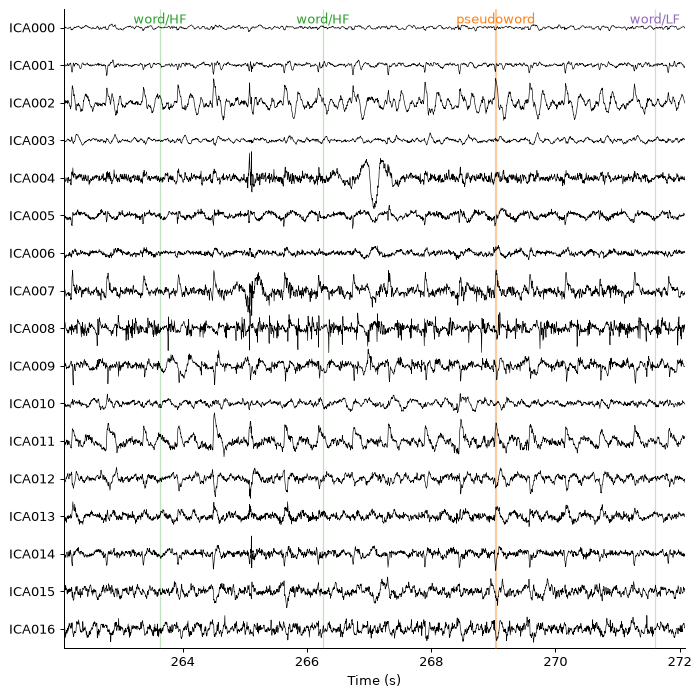

In [42]:
# ---- 6.4 The time courses of the components (10 s of the task) ---------------------------------------------------------------------
ica.plot_sources(ica_copy['task'], start=blink - 5, stop=blink + 5, show_scrollbars=False,
                 title='Time courses of the components, around the blink of step 4');

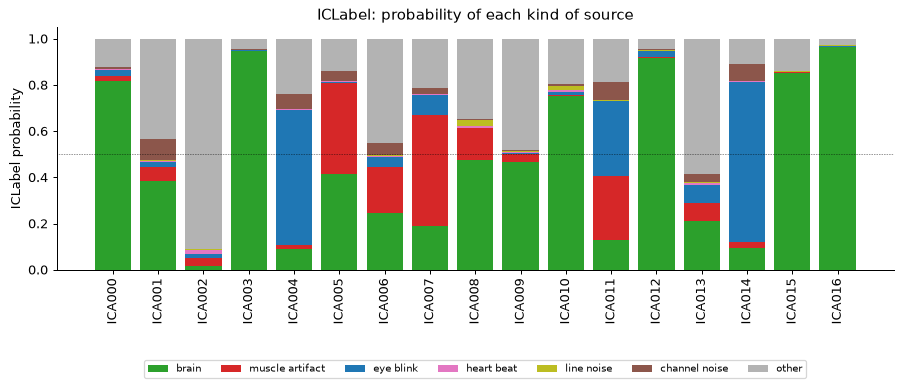

,brain,muscle artifact,eye blink,heart beat,line noise,channel noise,other
ICA000,0.82,0.02,0.02,0.00,0.00,0.01,0.12
ICA001,0.38,0.06,0.02,0.00,0.00,0.09,0.43
ICA002,0.02,0.03,0.02,0.02,0.00,0.00,0.91
ICA003,0.95,0.00,0.00,0.00,0.00,0.00,0.05
ICA004,0.09,0.02,0.59,0.00,0.00,0.06,0.24
ICA005,0.42,0.39,0.00,0.00,0.00,0.04,0.14
ICA006,0.25,0.20,0.05,0.00,0.00,0.05,0.45
ICA007,0.19,0.48,0.09,0.00,0.00,0.03,0.21
ICA008,0.47,0.14,0.00,0.01,0.03,0.00,0.35
ICA009,0.47,0.03,0.01,0.00,0.00,0.01,0.48


In [43]:
# ---- 6.5 ICLabel: what kind of source is each component? ---------------------------------------------------------------------------
CLASSES = ['brain', 'muscle artifact', 'eye blink', 'heart beat', 'line noise', 'channel noise', 'other']
iclabel_training = mne.concatenate_raws([raw.copy() for raw in iclabel_copy.values()])   # the ICLabel copy (1-100 Hz), joined
probabilities = np.array(iclabel_label_components(iclabel_training, ica, inplace=False))   # (components, 7 classes)
labels = pd.DataFrame(probabilities, columns=CLASSES, index=[f'ICA{i:03d}' for i in range(ica.n_components_)])

fig, ax = plt.subplots(figsize=(12, 3.5))
bottom = np.zeros(len(labels))
for cls, color in zip(CLASSES, ['tab:green', 'tab:red', 'tab:blue', 'tab:pink', 'tab:olive', 'tab:brown', '0.7']):
    ax.bar(labels.index, labels[cls], bottom=bottom, color=color, label=cls)
    bottom += labels[cls].to_numpy()
ax.axhline(0.5, color='k', lw=0.5, ls=':')
ax.set(ylabel='ICLabel probability', title='ICLabel: probability of each kind of source')
ax.tick_params(axis='x', rotation=90)
ax.legend(ncol=7, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.35))
plt.show()
labels.round(2)

**How.** ICLabel (Pion-Tonachini et al., 2019; Python version: Li et al., 2022) is a classifier trained on thousands of components labelled
by experts. It looks at each component's topography, spectrum and autocorrelation, and gives the probability of 7 kinds of source.
`iclabel_label_components(raw, ica)` expects data filtered at 1–100 Hz and average-referenced, which is exactly our ICLabel copy.

**Caution.** ICLabel is useful, but it is not the truth. It was trained on wet, high-density EEG, and with 19 dry electrodes its labels are
advice. It also makes a known mistake with the eyes: at the start of each eye movement, the muscles that turn the eye produce a sharp burst
of fast activity, the **saccadic spike potential** (about 20 to 90 Hz, largest near the eyes; Keren et al., 2010). A component that carries
it has a spectrum like a muscle, although it comes from the eyes, and it may be labelled muscle. So ICLabel is one opinion: cell 6.6 adds
other evidence, and the rule of cell 6.7 asks for a second piece of evidence when ICLabel is not sure.

Fp1   the most correlated components: ICA004 (r = -0.85), ICA000 (r = +0.33), ICA007 (r = -0.28)
Fp2   the most correlated components: ICA004 (r = -0.72), ICA014 (r = +0.55), ICA000 (r = +0.27)
HEOG  the most correlated components: ICA011 (r = -0.65), ICA007 (r = +0.64), ICA014 (r = +0.22)
13 of 17 components hold at least 60 % of their topography on one electrode; the largest shares of the variance among them: ICA012 (C3, 35 %), ICA011 (F8, 24 %), ICA000 (Pz, 17 %), ICA006 (T7, 5 %)


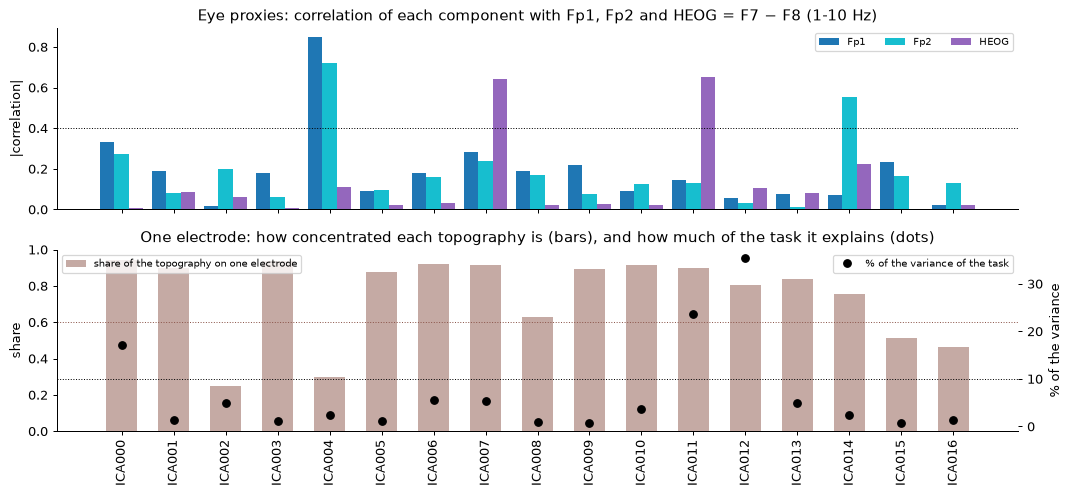

In [44]:
# ---- 6.6 More evidence: the eye proxies, and the components of one electrode -----------------------------------------------------------
# No electrode beside the eyes (EOG) on the DSI-24: proxies, on a temporary copy of the ICLabel copy. Fp1 and Fp2 sit above the eyes
# (blinks, vertical movements); HEOG = F7 − F8, a virtual bipolar channel, compares the left and right sides (horizontal movements)
heog = not {'F7', 'F8'} & set(BAD_CHANNELS)                 # HEOG needs both F7 and F8
ocular = iclabel_training.copy()                             # the analysis data and the copies are not changed
if heog:
    ocular = mne.set_bipolar_reference(ocular, anode='F7', cathode='F8', ch_name='HEOG', drop_refs=False)
    ocular.set_channel_types({'HEOG': 'eog'})
proxies = [ch for ch in ['Fp1', 'Fp2'] if ch not in BAD_CHANNELS] + ['HEOG'] * heog
eye_r = pd.DataFrame({proxy: ica.find_bads_eog(ocular, ch_name=proxy)[1] for proxy in proxies},   # Pearson r, filtered 1-10 Hz, every
                     index=labels.index)                                                       # component, BAD_ICA_ periods left out
# One electrode: the share of the topography's power (its squared weights) on its largest electrode, and the share of the variance of the
# task (0.1-30 Hz, outside the BAD annotations) that the component holds
topographies = ica.get_components()                          # channels × components
focality = pd.Series((topographies ** 2).max(axis=0) / (topographies ** 2).sum(axis=0), index=labels.index)
peak_channel = pd.Series(np.array(ica.ch_names)[np.abs(topographies).argmax(axis=0)], index=labels.index)
task_30 = analysis['task'].copy().filter(None, 30)
task_variance = task_30.get_data(picks=good_all, reject_by_annotation='omit').var(axis=1).sum()


def share_of(components):
    """The share (%) of the variance of the task held by these components: the variance of the data rebuilt from them alone, over the
    variance of the data (the measure of the Brain Walk analyses; include= keeps only them, whatever ica.exclude holds)."""
    rebuilt = ica.apply(task_30.copy(), include=list(components), exclude=[])
    return 100 * rebuilt.get_data(picks=good_all, reject_by_annotation='omit').var(axis=1).sum() / task_variance


variance = pd.Series([share_of([k]) for k in range(ica.n_components_)], index=labels.index)
for proxy in proxies:
    ranked = eye_r[proxy].abs().sort_values(ascending=False).index[:3]
    print(f'{proxy:5s} the most correlated components: ' + ', '.join(f'{k} (r = {eye_r.loc[k, proxy]:+.2f})' for k in ranked))
one = focality[focality >= FOCAL].index
print(f'{len(one)} of {ica.n_components_} components hold at least {100 * FOCAL:.0f} % of their topography on one electrode; the largest '
      'shares of the variance among them: ' + ', '.join(f'{k} ({peak_channel[k]}, {variance[k]:.0f} %)'
                                                        for k in variance[one].sort_values(ascending=False).index[:4]))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True)
x = np.arange(len(labels))
for j, (proxy, color) in enumerate(zip(proxies, ['tab:blue', 'tab:cyan', 'tab:purple'])):
    ax1.bar(x + (j - (len(proxies) - 1) / 2) * 0.27, eye_r[proxy].abs(), 0.27, color=color, label=proxy)
ax1.axhline(EYE_CORR, color='k', ls=':', lw=0.8)
ax1.set(ylabel='|correlation|', title='Eye proxies: correlation of each component with Fp1, Fp2 and HEOG = F7 − F8 (1-10 Hz)')
ax1.legend(fontsize=8, ncol=3)
ax2.bar(x, focality, 0.6, color='tab:brown', alpha=0.5, label='share of the topography on one electrode')
ax2.axhline(FOCAL, color='tab:brown', ls=':', lw=0.8)
ax2.set(ylabel='share', ylim=(0, 1), title='One electrode: how concentrated each topography is (bars), and how much of the task it explains (dots)',
        xticks=x, xticklabels=labels.index)
ax2.tick_params(axis='x', rotation=90)
twin = ax2.twinx()
twin.plot(x, variance, 'o', color='k', label='% of the variance of the task')
twin.axhline(CHANNEL_VAR, color='k', ls=':', lw=0.8)
twin.set_ylabel('% of the variance')
ax2.legend(fontsize=8, loc='upper left')
twin.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

**Look.** Top: ICA004 follows Fp1 and Fp2 together (r = −0.85 and −0.72; the sign of a component is arbitrary): the blinks. ICA014
follows Fp2 alone (r = +0.55). HEOG = F7 − F8 is followed by ICA011 (r = −0.65) and ICA007 (r = +0.64), but ICA011 lives on F8 alone and
ICA007 on F7 alone (cell 6.3): F7 − F8 contains everything F7 and F8 record, so a component of one of them follows it whatever it is. A
proxy is evidence to check like any other.

Bottom: 13 of the 17 components put at least 60 % of their topography on one electrode, and most of them explain a few percent of the
task at most. Three are large: C3 (35 % of the variance of the task), F8 (24 %) and Pz (17 %). These are electrodes that move on the skin
on their own, and together they hold more of the walking data than the blinks. The Pz component is the noise of the reference sensor,
which the average reference gave back to Pz (cell 4.1); its time course rises at every step (cell 6.8). ICLabel calls the C3 and Pz
components brain (0.92 and 0.82): it was trained on wet, dense EEG, where one electrode rarely holds a source of its own.

### The decision: the rule of the Brain Walk analyses

The rule comes from the Brain Walk analyses of the COSYNE abstract, which compared the ERPs of all the participants after removing
different sets of components (thresholds in cell 0.3):

| Kind | Removed when |
|---|---|
| eye | ICLabel gives "eye" at least 0.6 (`EYE_P`), or "eye" is ICLabel's first choice **and** the component follows an eye proxy (Fp1, Fp2 or HEOG) with \|r\| at least 0.4 (`EYE_CORR`) |
| muscle | ICLabel gives "muscle" at least 0.5 (`MUSCLE_P`) |
| channel noise | at least 60 % of the topography's power is on one electrode (`FOCAL`) **and** the component explains at least 10 % of the variance of the task (`CHANNEL_VAR`); or ICLabel gives "channel noise" at least 0.5 |

All the other components are **kept**. A large component of one electrode that follows an eye proxy, while ICLabel gives "eye" less
than 0.6, counts as channel noise: a component of F7 or F8 follows HEOG = F7 − F8 whatever it is (cell 6.6). Two of the three kinds ask
for two pieces of evidence. An eye component that ICLabel is not sure
about needs an eye proxy to agree. A component of one electrode needs to be large: while walking, most components are concentrated on one
electrode, ICLabel calls many of them brain, and removing all of them halved the ERPs of the Brain Walk participants and erased their
lexicality effect; removing only those that explain at least 10 % of the variance (an average electrode holds about 6 %) made the ERPs more
precise without changing them. The threshold 0.6 for the eyes caught eye components that 0.7 missed. The component numbers change from one
participant to the next: the rule looks at the evidence, never at a number.

In [45]:
# ---- 6.7 The decision ---------------------------------------------------------------------------------------------------------------
evidence = pd.DataFrame({'ICLabel_brain': labels['brain'], 'ICLabel_eye': labels['eye blink'], 'ICLabel_muscle': labels['muscle artifact'],
                         'ICLabel_channel': labels['channel noise']})
evidence = evidence.join(eye_r.add_prefix('corr_'))
evidence['focality'] = focality
evidence['peak_channel'] = peak_channel
evidence['variance_pct'] = variance
evidence.index.name = 'component'
eye_first = labels.idxmax(axis=1) == 'eye blink'             # "eye" is ICLabel's first choice
one_electrode = (focality >= FOCAL) & (variance >= CHANNEL_VAR)
rules = {'eye': (evidence['ICLabel_eye'] >= EYE_P) | (eye_first & (eye_r.abs().max(axis=1) >= EYE_CORR)),
         'muscle': evidence['ICLabel_muscle'] >= MUSCLE_P,
         'channel noise': one_electrode | (evidence['ICLabel_channel'] >= 0.5)}


def decide(k):
    """The class of component k, the decision (remove or keep) and the reason."""
    e = evidence.iloc[k]
    # a component of one electrode that follows a proxy is that electrode (HEOG = F7 - F8 follows anything F7 or F8 records, cell 6.6),
    # unless ICLabel itself is sure it is an eye
    if rules['eye'].iloc[k] and not (one_electrode.iloc[k] and e.ICLabel_eye < EYE_P):
        r = eye_r.iloc[k].abs()
        kind = 'eye (horizontal)' if r.get('HEOG', 0) > r.drop('HEOG', errors='ignore').max() else 'eye (blink)'
        if e.ICLabel_eye >= EYE_P:
            return kind, 'remove', f'ICLabel eye {e.ICLabel_eye:.2f}'
        return kind, 'remove', f"eye is ICLabel's first choice ({e.ICLabel_eye:.2f}) and |r| = {r.max():.2f} with {r.idxmax()}"
    if rules['muscle'].iloc[k]:
        return 'muscle', 'remove', f'ICLabel muscle {e.ICLabel_muscle:.2f}'
    if rules['channel noise'].iloc[k]:
        if one_electrode.iloc[k]:
            return 'channel noise', 'remove', f'{100 * e.focality:.0f} % of its topography on {e.peak_channel}, {e.variance_pct:.0f} % of the variance'
        return 'channel noise', 'remove', f'ICLabel channel noise {e.ICLabel_channel:.2f}'
    one = f', one electrode ({e.peak_channel})' if e.focality >= FOCAL else ''
    return labels.columns[labels.iloc[k].argmax()] + one, 'keep', ''


evidence = evidence.join(pd.DataFrame([decide(k) for k in range(ica.n_components_)], index=evidence.index,
                                      columns=['proposed_class', 'decision', 'reason']))
ica.exclude = [k for k in range(ica.n_components_) if evidence['decision'].iloc[k] == 'remove']
share = share_of(ica.exclude) if ica.exclude else 0.0
print(f'Proposed: remove {len(ica.exclude)} of {ica.n_components_} components (together {share:.0f} % of the variance of the task): ' + ', '.join(f'{evidence.index[k]} ({evidence["proposed_class"].iloc[k]})' for k in ica.exclude)
      + '. Cell 6.9 checks the proposal before step 7 applies it.')
evidence.round(2)

Proposed: remove 5 of 17 components (together 77 % of the variance of the task): ICA000 (channel noise), ICA004 (eye (blink)), ICA011 (channel noise), ICA012 (channel noise), ICA014 (eye (blink)). Cell 6.9 checks the proposal before step 7 applies it.


,ICLabel_brain,ICLabel_eye,ICLabel_muscle,ICLabel_channel,corr_Fp1,corr_Fp2,corr_HEOG,focality,peak_channel,variance_pct,proposed_class,decision,reason
component,,,,,,,,,,,,,
ICA000,0.82,0.02,0.02,0.01,0.33,0.27,-0.01,0.94,Pz,17.10,channel noise,remove,"94 % of its topography on Pz, 17 % of the vari..."
ICA001,0.38,0.02,0.06,0.09,0.19,-0.08,-0.09,0.90,Fz,1.39,"other, one electrode (Fz)",keep,
ICA002,0.02,0.02,0.03,0.00,0.02,0.20,0.06,0.25,O2,4.88,other,keep,
ICA003,0.95,0.00,0.00,0.00,-0.18,-0.06,0.01,0.94,C4,1.15,"brain, one electrode (C4)",keep,
ICA004,0.09,0.59,0.02,0.06,-0.85,-0.72,-0.11,0.30,F7,2.32,eye (blink),remove,eye is ICLabel's first choice (0.59) and |r| =...
ICA005,0.42,0.00,0.39,0.04,-0.09,-0.09,-0.02,0.88,T8,1.12,"brain, one electrode (T8)",keep,
ICA006,0.25,0.05,0.20,0.05,0.18,0.16,-0.03,0.92,T7,5.49,"other, one electrode (T7)",keep,
ICA007,0.19,0.09,0.48,0.03,-0.28,-0.24,0.64,0.92,F7,5.28,"muscle artifact, one electrode (F7)",keep,
ICA008,0.47,0.00,0.14,0.00,0.19,0.17,-0.02,0.63,O1,0.86,"brain, one electrode (O1)",keep,


**Look.** One row of evidence per component: this table is the record of the decision, and cell 10.1 saves it with the results. In P010
while walking, five components are removed. Two are eye components: ICA004, the blink ("eye" is ICLabel's first choice, at 0.59, and it
follows Fp1 with |r| = 0.85), and ICA014 (ICLabel eye 0.69, on Fp2). Three are components of one electrode: C3 (ICA012, 35 % of the
variance of the task), F8 (ICA011, 24 %) and Pz (ICA000, 17 %). ICA011 also follows HEOG, but it lives on F8 alone, so it counts as
channel noise. Together the five hold 77 % of the variance of the task, most of it slow drifts of single electrodes. The other components of one
electrode hold 5.5 % of the task or less and stay (cell 6.8 shows the two largest, T7 and F7); the F7 one, ICA007, is also just below
the muscle threshold (ICLabel muscle 0.48). Seated, the rule of the seated
notebook removed five components of this participant.

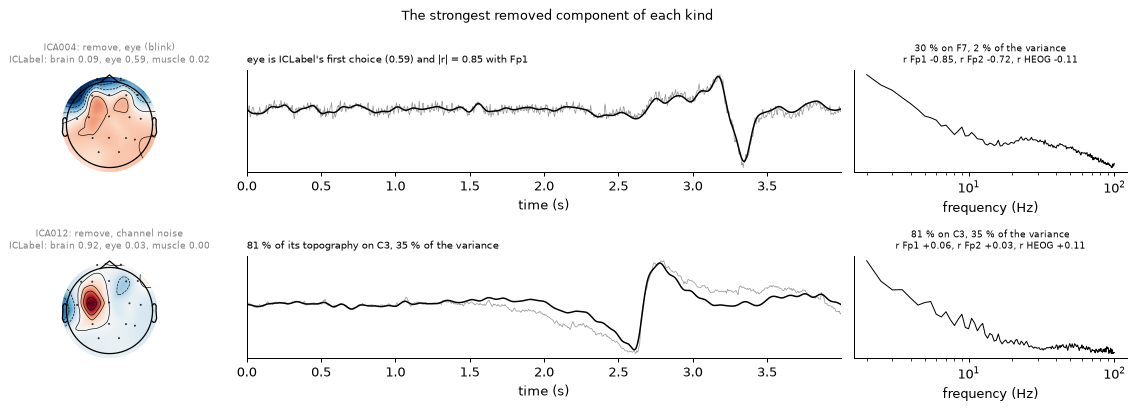

In [46]:
# ---- 6.8 A closer look: the strongest removed component of each kind ------------------------------------------------------------------
pieces_4s = mne.make_fixed_length_epochs(iclabel_training, duration=4, preload=True)   # 4-s pieces of the ICLabel copy
piece_sources = ica.get_sources(pieces_4s).get_data()        # pieces × components × samples
slow_sources = mne.filter.filter_data(piece_sources, sfreq, 1, 10)   # their 1-10 Hz part: the band of the eye proxies
component_spectra = ica.get_sources(iclabel_training).compute_psd(fmin=2, fmax=100, picks='misc', n_fft=int(2 * sfreq))


def show_components(picks, title):
    """One row per component: its topography and ICLabel, 4 s of its time course (grey: all of it; black: its 1-10 Hz part), and its
    spectrum (log-log). Eye components are shown where their 1-10 Hz part is largest, the others where they are largest."""
    fig, axes = plt.subplots(len(picks), 3, figsize=(13, 2.3 * len(picks)), width_ratios=[1, 2.4, 1.1], squeeze=False)
    for (ax_map, ax_time, ax_psd), k in zip(axes, picks):
        e = evidence.iloc[k]
        ica.plot_components(picks=k, axes=ax_map, colorbar=False, show=False)
        ax_map.set_title(f'{evidence.index[k]}: {e.decision}, {e.proposed_class}\nICLabel: brain {e.ICLabel_brain:.2f}, eye '
                         f'{e.ICLabel_eye:.2f}, muscle {e.ICLabel_muscle:.2f}', fontsize=7.5)
        focus = slow_sources if e.proposed_class.startswith('eye') else piece_sources
        best = np.ptp(focus[:, k], axis=-1).argmax()
        ax_time.plot(pieces_4s.times, piece_sources[best, k], color='0.6', lw=0.6)
        ax_time.plot(pieces_4s.times, slow_sources[best, k], color='k', lw=1.2)
        ax_time.set(yticks=[], xlim=(0, pieces_4s.times[-1]), xlabel='time (s)')
        ax_time.set_title(e.reason, fontsize=8, loc='left')
        ax_psd.loglog(component_spectra.freqs, component_spectra.get_data(picks=[k])[0], color='k', lw=0.8)
        ax_psd.yaxis.set_major_locator(plt.NullLocator())
        ax_psd.yaxis.set_minor_locator(plt.NullLocator())
        ax_psd.set_xlabel('frequency (Hz)')
        ax_psd.set_title(f'{100 * e.focality:.0f} % on {e.peak_channel}, {e.variance_pct:.0f} % of the variance\n'
                         + ', '.join(f'r {p} {e["corr_" + p]:+.2f}' for p in proxies), fontsize=7.5)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


chosen = evidence[evidence['decision'] == 'remove']
strength = {'eye (blink)': chosen.filter(like='corr_Fp').abs().max(axis=1), 'eye (horizontal)': chosen.filter(like='corr_HEOG').abs().max(axis=1),
            'muscle': chosen['ICLabel_muscle'], 'channel noise': chosen['variance_pct']}
examples = [evidence.index.get_loc(strength[kind][chosen['proposed_class'] == kind].idxmax())   # the strongest of each kind
            for kind in strength if (chosen['proposed_class'] == kind).any()]
show_components(examples, 'The strongest removed component of each kind')

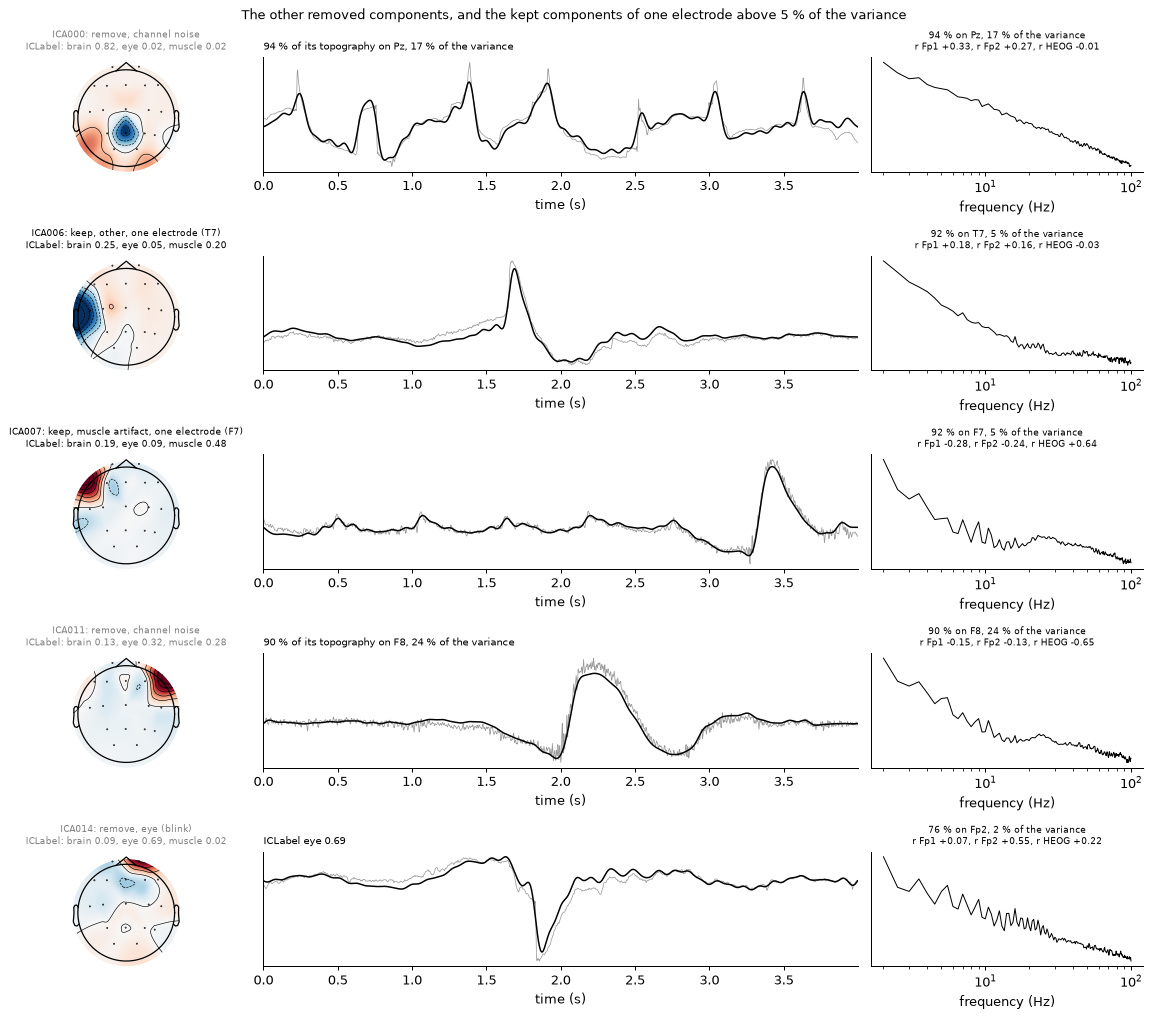

In [47]:
# ---- 6.8 (continued) The other removed components, and the large components of one electrode that stay --------------------------------
others = [k for k in range(ica.n_components_) if k not in examples
          and (evidence['decision'].iloc[k] == 'remove'
               or (evidence['focality'].iloc[k] >= FOCAL and evidence['variance_pct'].iloc[k] >= CHANNEL_VAR / 2))]
if others:
    show_components(others, f'The other removed components, and the kept components of one electrode above {CHANNEL_VAR / 2:g} % of the variance')
else:
    print('No other removed component, and no kept component of one electrode above half the limit.')

**Look.** Each row is one component: its map and ICLabel, 4 s of its time course (grey: all of it; black: its 1–10 Hz part, where the
eyes are) and its spectrum. **Blink** (ICA004): a frontal map, a large slow wave at the blink, most of its power at low frequencies.
**Channel noise** (ICA012): one spot on C3 and a slow jump of its own, the kind of signal an electrode makes when its contact with the
skin changes. The second figure shows the three other removed components and the two largest kept components of one electrode. **ICA000** (Pz)
rises at every step, about every 0.57 s: the reference sensor shaken by walking. **ICA011** (F8) has large slow waves of its own.
**ICA014** (Fp2) has a sharp deflection on Fp2, which ICLabel calls eye (0.69). **ICA006** (T7) and **ICA007** (F7) also have slow
waves of their own, but each holds only about 5 % of the task: below the limit of 10 %, they stay.

After / before (% of the amplitude, median over the windows), and the correlation before-after in the middle and at the back:
               windows  front  middle and back  temples 30-100 Hz  middle and back, r
blinks            18.0   42.0             86.0               93.0               0.839
muscle bursts     24.0   54.0             70.0               87.0               0.838
clean            132.0   66.0             96.0               95.0               0.947
✓ ocular transients strongly reduced at the front (below 50 % of their amplitude)
✓ muscle bursts reduced at the temples (30-100 Hz below 100 %)
✓ clean moments unchanged in the middle and at the back (90-110 %, r at least 0.9): the brain signal is not flattened


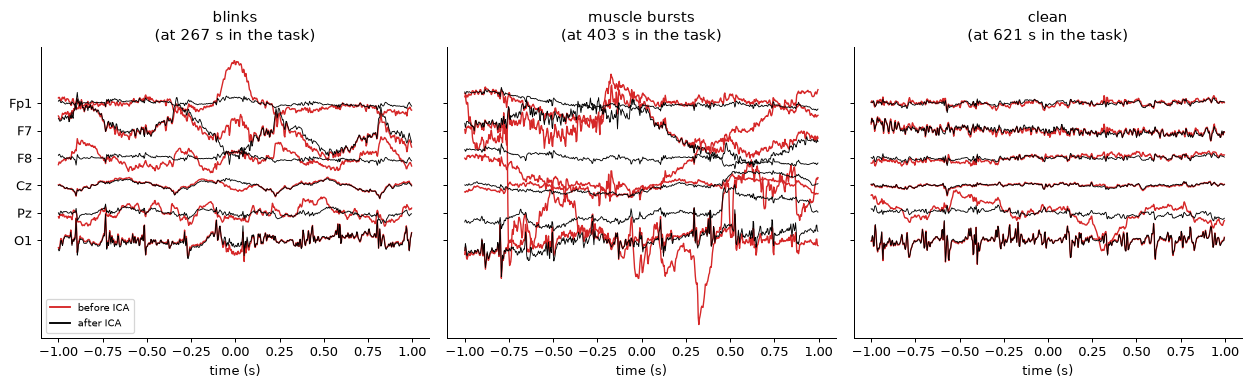

Validated eye components       ['ICA004', 'ICA014']
Validated muscle components    []
To review (kept for now)       []
Final exclusion list           ['ICA000', 'ICA004', 'ICA011', 'ICA012', 'ICA014']


In [48]:
# ---- 6.9 Before accepting the decision: apply it to a copy, and compare four kinds of moments ---------------------------------------
edge = [ch for ch in ['F7', 'F8', 'T7', 'T8'] if ch not in BAD_CHANNELS]   # the temples: muscles
own_noise = [evidence['peak_channel'].iloc[k] for k in ica.exclude if evidence['proposed_class'].iloc[k] == 'channel noise']
test_copy = ica.apply(analysis['task'].copy())               # a copy: the analysis data are not changed (step 7 applies ICA to them)
before_ep = mne.make_fixed_length_epochs(analysis['task'], duration=2, preload=True)   # 2-s windows, junctions and gaps left out
after_ep = mne.make_fixed_length_epochs(test_copy, duration=2, preload=True)           # the same windows, after ICA
groups = {'front': [ch for ch in ['Fp1', 'Fp2', 'F7', 'F8'] if ch not in BAD_CHANNELS],
          'middle and back': [ch for ch in ['Cz', 'Pz', 'P3', 'P4', 'O1', 'O2'] if ch not in BAD_CHANNELS + own_noise],   # (own_noise:
                                                             # the electrodes whose own noise was removed are meant to change)
          'temples': edge}
x_before = {group: before_ep.get_data(picks=chs) * 1e6 for group, chs in groups.items()}   # windows x channels x samples (µV)
x_after = {group: after_ep.get_data(picks=chs) * 1e6 for group, chs in groups.items()}
starts = before_ep.events[:, 0] - analysis['task'].first_samp


def contains(samples):
    """True for each window that contains at least one of these samples."""
    return np.array([np.any((samples >= s) & (samples < s + len(before_ep.times))) for s in starts])


def window_rms(x, fmin=None, fmax=None):
    """Root mean square of each window and channel, from its spectrum: all frequencies but the mean, or only fmin to fmax (Hz)."""
    f = np.fft.rfftfreq(x.shape[-1], 1 / sfreq)
    keep = (f > 0) if fmin is None else (f >= fmin) & (f <= fmax)
    return np.sqrt(2 * (np.abs(np.fft.rfft(x, axis=-1)) ** 2)[..., keep].sum(axis=-1)) / x.shape[-1]


blinks = blink_events[:, 0] - analysis['task'].first_samp   # the blinks of cell 4.2
moves = np.array([], dtype=int)
horizontal = [k for k in ica.exclude if evidence['proposed_class'].iloc[k] == 'eye (horizontal)']
if horizontal:                                               # eye movements: the fastest changes of the horizontal eye component
    slow = mne.filter.filter_data(ica.get_sources(analysis['task']).get_data(picks=horizontal[:1])[0], sfreq, None, 10)
    speed = np.abs(np.gradient(slow))
    moves, _ = find_peaks(speed, height=np.median(speed) + 5 * 1.4826 * np.median(np.abs(speed - np.median(speed))),
                          distance=int(0.5 * sfreq))
    moves = moves[np.min(np.abs(moves[:, None] - blinks[None, :]), axis=1) > 0.5 * sfreq]   # not during a blink
muscle_power = window_rms(x_before['temples'], 30, 100).mean(axis=1)
eye_power = window_rms(x_before['front'], 1, 10).mean(axis=1)
moments = {'blinks': contains(blinks), 'horizontal eye movements': contains(moves) & ~contains(blinks),
           'muscle bursts': muscle_power >= np.quantile(muscle_power, 0.95)}   # the 5 % of windows with the most fast activity
moments['clean'] = (~np.logical_or.reduce(list(moments.values())) & (muscle_power < np.median(muscle_power))
                    & (eye_power < np.median(eye_power)))                     # no event, little fast activity, little eye activity
rows = {}
for moment, chosen in moments.items():
    if chosen.any():
        relative = lambda group, *band: 100 * np.median(window_rms(x_after[group][chosen], *band) / window_rms(x_before[group][chosen], *band))
        rows[moment] = {'windows': chosen.sum(), 'front': relative('front'), 'middle and back': relative('middle and back'),
                        'temples 30-100 Hz': relative('temples', 30, 100),
                        'middle and back, r': np.corrcoef(x_before['middle and back'][chosen].ravel(),
                                                          x_after['middle and back'][chosen].ravel())[0, 1]}
comparison = pd.DataFrame(rows).T
eye_rows = [m for m in ['blinks', 'horizontal eye movements'] if m in comparison.index]
checks = {'ocular transients strongly reduced at the front (below 50 % of their amplitude)': (comparison.loc[eye_rows, 'front'] < 50).all(),
          'muscle bursts reduced at the temples (30-100 Hz below 100 %)': comparison.loc['muscle bursts', 'temples 30-100 Hz'] < 100,
          'clean moments unchanged in the middle and at the back (90-110 %, r at least 0.9): the brain signal is not flattened':
              90 <= comparison.loc['clean', 'middle and back'] <= 110 and comparison.loc['clean', 'middle and back, r'] >= 0.9}
print('After / before (% of the amplitude, median over the windows), and the correlation before-after in the middle and at the back:')
print(comparison.round({'windows': 0, 'front': 0, 'middle and back': 0, 'temples 30-100 Hz': 0, 'middle and back, r': 3}).to_string())
for text, ok in checks.items():
    print(('✓ ' if ok else '✗ ') + text)

centres = {'blinks': blink * sfreq}                          # one example of each: the blink of cell 4.2,
if len(moves):
    centres['horizontal eye movements'] = moves[np.argmax(speed[moves])]   # the fastest eye movement,
for moment in ['muscle bursts', 'clean']:                    # the middle of a typical window
    windows_in = np.flatnonzero(moments[moment])
    size = muscle_power if moment == 'muscle bursts' else window_rms(x_before['middle and back']).mean(axis=1)
    centres[moment] = starts[windows_in[np.argsort(size[windows_in])[len(windows_in) // 2]]] + sfreq
shown = [ch for ch in ['Fp1', 'F7', 'F8', 'Cz', 'Pz', 'O1'] if ch not in BAD_CHANNELS]
fig, axes = plt.subplots(1, len(centres), figsize=(14, 4.4), sharey=True)
for ax, (moment, centre) in zip(axes, centres.items()):
    start = int(centre - sfreq)
    for data, color, lw in [(analysis['task'], 'tab:red', 1.1), (test_copy, 'k', 0.7)]:
        y = data.get_data(picks=shown, start=start, stop=start + 2 * int(sfreq)) * 1e6
        for k, trace in enumerate(y):
            ax.plot(np.arange(len(trace)) / sfreq - 1, trace - trace.mean() - 100 * k, color=color, lw=lw)
    ax.set(title=f'{moment}\n(at {centre / sfreq:.0f} s in the task)', xlabel='time (s)', yticks=-100 * np.arange(len(shown)),
           yticklabels=shown)
axes[0].plot([], [], color='tab:red', label='before ICA')
axes[0].plot([], [], color='k', label='after ICA')
axes[0].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

for title, chosen in [('Validated eye components', evidence['proposed_class'].str.startswith('eye')),
                      ('Validated muscle components', evidence['proposed_class'] == 'muscle')]:
    print(f'{title:30s}', list(evidence.index[chosen & (evidence['decision'] == 'remove')]))
print(f'{"To review (kept for now)":30s}', list(evidence.index[evidence['decision'] == 'review']))
print(f'{"Final exclusion list":30s}', [evidence.index[k] for k in ica.exclude])

**Look.** The table compares the same 2-s windows of the task before and after removing the five components, on a copy. The **blinks**
(the 18 windows with a blink of cell 4.2) keep 42 % of their amplitude at the front: the eye components carried them. No horizontal eye
movement component was removed, so the table has no row for eye movements. The **muscle bursts** keep 87 % of their fast activity at the
temples: no muscle component was removed, and part of what goes is the F8 component. The **clean** moments keep 96 % of their amplitude
in the middle and at the back (r = 0.95 between before and after): the brain signal is not flattened. Pz is left out of this
comparison: its own noise was removed, so it is meant to change (`own_noise` in the code). The figure shows one example of each kind.

**The cleaning strategy.** The head-movement regression (step 4) removes what follows the acceleration of the head; AMICA then removes the
sources with a fixed map, the eyes and the electrodes that move on their own. Once the components are validated, `ica.exclude` holds them,
and step 7 applies the ICA solution to every sample of the 0.1–100 Hz analysis data, the data the two copies came from.

## 7. Remove the eye and muscle components, then what repeats at every stride

**What.** Remove the components validated in step 6 (`ica.exclude`) from the **analysis data** (0.1–100 Hz, cleaned of the head movement). At each moment, `ica.apply(raw)` computes the components
with the unmixing matrix (components = `W` × channels), sets the excluded components to zero, and rebuilds the channels with the mixing matrix
(channels = `A` × components).

**Why it works on the analysis data.** `W` and `A` are **spatial**: they only say how to combine the electrodes at one moment, whatever the
frequencies of the signal (step 6). A filter works over time, on each electrode separately. The two operations do not interfere (both are
linear), so the weights learned on the 2–100 Hz copy are valid for the 0.1–100 Hz analysis data (Winkler et al., 2015). We get the best of both: a good
decomposition, and slow ERPs that are not distorted.

**All the data.** ICA is applied to every sample of the analysis data, the periods left out of ICA training (step 5) included. Nothing is
cropped, and the QC annotations stay on the data (cell 7.1 checks both).

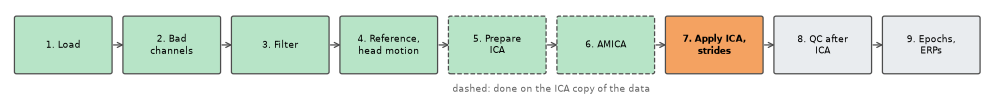

In [49]:
pipeline_map(7)

In [50]:
# ---- 7.1 Apply ICA to the two analysis recordings: every sample, and the QC annotations kept ----------------------------------------
cleaned = {name: ica.apply(raw.copy()) for name, raw in analysis.items()}
print(f'Removed components {ica.exclude} from:', ', '.join(cleaned))
for name in cleaned:
    qc_before = [d for d in analysis[name].annotations.description if d.startswith('QC_')]
    qc_after = [d for d in cleaned[name].annotations.description if d.startswith('QC_')]
    print(f'{name:10s} every sample kept: {cleaned[name].n_times == analysis[name].n_times}; '
          f'QC annotations kept: {qc_after == qc_before} ({len(qc_after)})')

Removed components [0, 4, 11, 12, 14] from: walk_only, task
walk_only  every sample kept: True; QC annotations kept: True (4)
task       every sample kept: True; QC annotations kept: True (42)


20 blinks found in the task (cell 4.2), 1.3 per minute


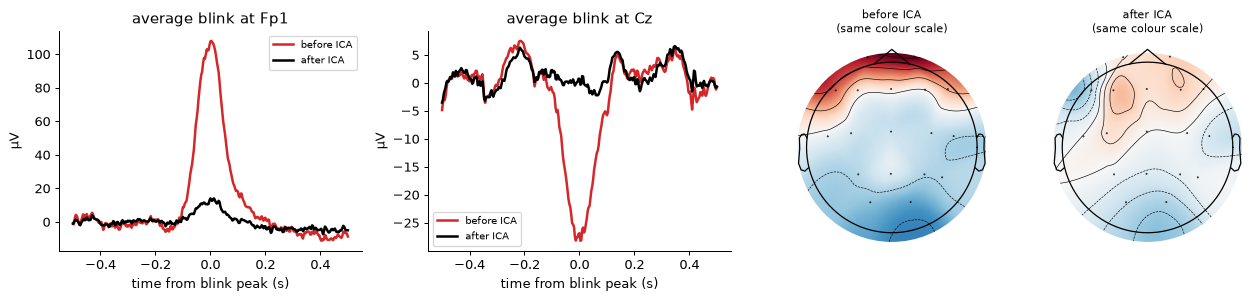

In [51]:
# ---- 7.2 The average blink, before and after ICA -----------------------------------------------------------------------------------
print(f'{len(blink_events)} blinks found in the task (cell 4.2), {len(blink_events) / (analysis["task"].times[-1] / 60):.1f} per minute')
blink_average = {label: mne.Epochs(data['task'], blink_events, tmin=-0.5, tmax=0.5, baseline=(-0.5, -0.3), preload=True).average()
                 for label, data in [('before ICA', analysis), ('after ICA', cleaned)]}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), width_ratios=[1.6, 1.6, 1, 1])
for ax, ch in zip(axes[:2], [frontal, 'Cz']):
    for (label, evoked), color in zip(blink_average.items(), ['tab:red', 'k']):
        ax.plot(evoked.times, evoked.get_data(picks=ch)[0] * 1e6, color=color, lw=2, label=label)
    ax.set(title=f'average blink at {ch}', xlabel='time from blink peak (s)', ylabel='µV')
    ax.legend(fontsize=8)
peak = blink_average['before ICA'].get_data(picks=good_all).max() * 1e6
for ax, (label, evoked) in zip(axes[2:], blink_average.items()):
    data = evoked.copy().pick(good_all).crop(0, 0)
    mne.viz.plot_topomap(data.get_data()[:, 0] * 1e6, data.info, axes=ax, show=False, vlim=(-peak, peak), cmap='RdBu_r')
    ax.set_title(f'{label}\n(same colour scale)', fontsize=9)
plt.tight_layout()
plt.show()

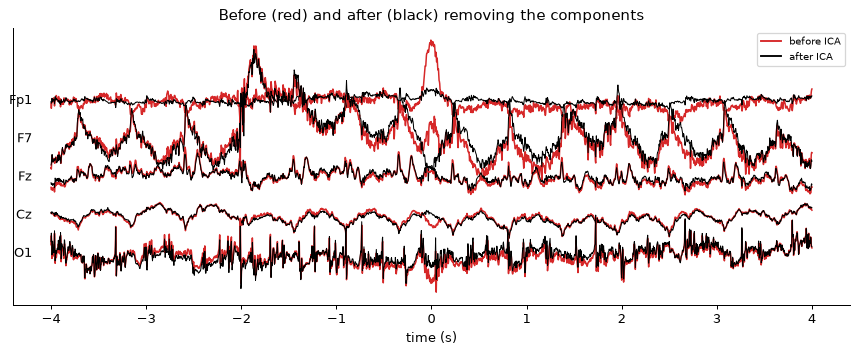

In [52]:
# ---- 7.3 Eight seconds of the task, before and after ICA ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
for k, ch in enumerate(['Fp1', 'F7', 'Fz', 'Cz', 'O1']):
    for data, color, lw in [(analysis, 'tab:red', 1.2), (cleaned, 'k', 0.8)]:
        piece = data['task'].copy().crop(blink - 4, blink + 4)
        ax.plot(piece.times - 4, piece.get_data(picks=ch)[0] * 1e6 - 100 * k, color=color, lw=lw)
    ax.text(-4.2, -100 * k, ch, ha='right', va='center')
ax.plot([], [], color='tab:red', label='before ICA')
ax.plot([], [], color='k', label='after ICA')
ax.set(yticks=[], xlabel='time (s)', title='Before (red) and after (black) removing the components')
ax.legend(loc='upper right', fontsize=8)
plt.show()

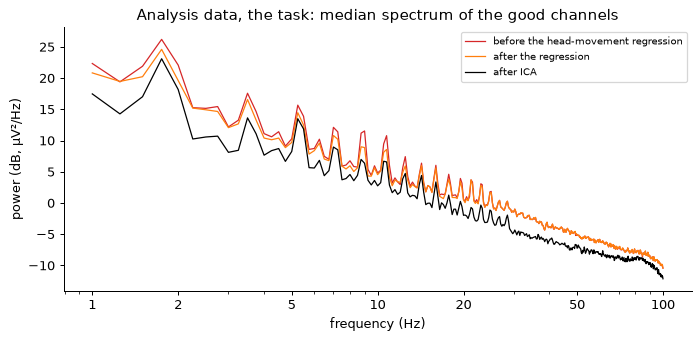

In [53]:
# ---- 7.4 The spectrum of the task: before the head-movement regression, after it, and after ICA ----------------------------------------
fig, ax = plt.subplots(figsize=(9, 3.8))
for label, data, color in [('before the head-movement regression', before_motion['task'], 'tab:red'),
                           ('after the regression', analysis['task'], 'tab:orange'), ('after ICA', cleaned['task'], 'k')]:
    psd = data.compute_psd(method='welch', picks=good_all, fmin=1, fmax=100, n_fft=int(4 * sfreq))   # 0.25 Hz resolution
    ax.plot(psd.freqs, 10 * np.log10(np.median(psd.get_data(), axis=0) * 1e12), color=color, lw=1, label=label)
ax.set(xscale='log', xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title='Analysis data, the task: median spectrum of the good channels')
ax.set_xticks([1, 2, 5, 10, 20, 50, 100], ['1', '2', '5', '10', '20', '50', '100'])
ax.legend(fontsize=8)
plt.show()

**Look.** The average blink of 7.2 is now a real blink: the 20 blinks of cell 4.2 are about 110 µV at Fp1 and −28 µV at Cz before ICA, and
about 13 µV and 0 µV after, and the frontal map is gone. In the traces (7.3), the blink at time 0 disappears from Fp1. F7 keeps a slow
wave at every step: it comes from ICA007, which ICLabel calls muscle at 0.48, just below the threshold (cell 6.7). The sharp waves of Fz at
every step are smaller than before the regression, but still there: cell 7.5 removes both. In the spectrum (7.4), the regression lowers the comb of peaks of
the steps, every 1.8 Hz, and ICA lowers the whole spectrum by a few dB, because the components it removes hold more than half of the
variance.

#### Check your understanding

- **After ICA the blink is gone at Fp1. Is the brain signal at Fp1 gone too?**
  <details><summary>Answer</summary>

  No: only the removed components are subtracted, and the brain components still contribute to Fp1. But any brain activity mixed into a removed component is lost: this is why we remove as few components as possible.

  </details>
- **Why was it important to find the bad channels before ICA?**
  <details><summary>Answer</summary>

  A noisy channel would have taken one or more components for itself, and after the average reference its noise would have been in every channel, mixed with the other sources.

  </details>

### What repeats at every stride: Gwin's template

**What.** Part of each step is still in the data after ICA: the sharp wave of Fz and the slow wave of F7 at every step (cell 7.3). An
electrode that moves on the skin, or whose cable pulls it, makes a wave of its own, so these waves have no fixed map over the scalp and ICA
cannot gather them into one component; at most it leaves them in a component of one electrode too small to remove (ICA007 for F7). But
they repeat at every stride (two steps, one of each foot). Gwin et al. (2010) estimate them in each channel from the neighbouring strides:
the average of the 20 strides around a stride, all stretched to the same length between their steps, is what this stride shares with
them. Cell 7.5 scales this template to the stride (least squares) and subtracts it.

**Why it keeps the ERPs.** A word comes every 2 to 3 s, at any moment of the stride, so its ERP falls at a different moment of each
neighbouring stride and averages out of their template. What the template removes is what is locked to the stride, brain activity
included: fine here, where the events are the words.

**Why after ICA.** Gwin et al. subtracted the template before ICA. For P010, subtracting it before ICA changed the components AMICA found
and made the N400 and the LPC less precise than with no template at all; after ICA, the decision of step 6 stays as it is, and the template
removes only what ICA left.

**How.** The steps of cell 4.3 define the strides; strides that touch a `BAD` annotation are left out. `STRIDES_AROUND` (cell 0.3) sets
how many strides on each side make the template, and `average_step` (cell 4.5) checks the result.

1097 strides. The average step (RMS over its 0.6 s): median of the good channels 3.4 µV after ICA, 0.7 µV after the template; at Fz, 9.8 µV, then 1.2 µV


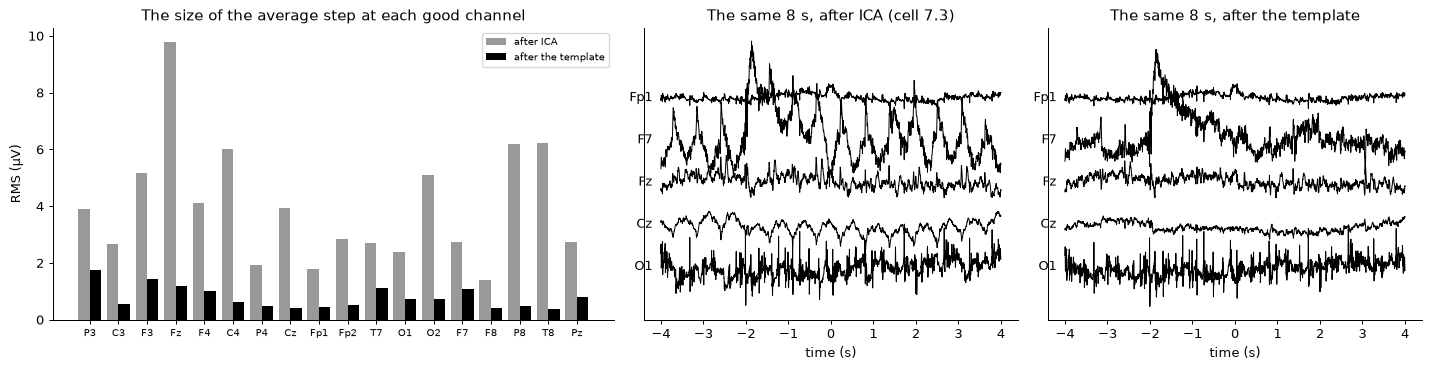

In [54]:
# ---- 7.5 Subtract what repeats at every stride (Gwin et al., 2010) ---------------------------------------------------------------------
def stride_artifact(x, strides, half):
    """What each stride of x (channels × samples) has in common with the STRIDES_AROUND strides on each side of it: their average, each
    stride stretched to two halves of `half` samples (first step to middle step, middle step to next stride), scaled to the stride by
    least squares in each channel, and stretched back. Zero outside the strides."""
    grid = np.linspace(0, 1, half, endpoint=False)

    def stretch(a, b, c):
        return np.hstack([[np.interp(grid * (e - s), np.arange(e - s), ch) for ch in x[:, s:e]] for s, e in ((a, b), (b, c))])
    stretched = np.stack([stretch(*stride) for stride in strides])   # strides × channels × (2 × half)
    artifact = np.zeros_like(x)
    for i, (a, b, c) in enumerate(strides):
        around = np.r_[max(0, i - STRIDES_AROUND):i, i + 1:min(len(strides), i + 1 + STRIDES_AROUND)]
        template = stretched[around].mean(axis=0)
        template -= template.mean(axis=1, keepdims=True)
        this = stretched[i] - stretched[i].mean(axis=1, keepdims=True)
        fitted = template * ((this * template).sum(axis=1) / (template ** 2).sum(axis=1))[:, None]
        artifact[:, a:c] = np.hstack([[np.interp(np.arange(e - s) / (e - s), grid, ch) for ch in fitted[:, k * half:(k + 1) * half]]
                                      for k, (s, e) in enumerate(((a, b), (b, c)))])
    return artifact


before_template = {name: raw.copy() for name, raw in cleaned.items()}   # kept for the figure
n_strides = 0
for part, (recording, first) in PARTS.items():
    raw = cleaned[recording]
    in_bad = np.isnan(raw.get_data(picks=good_all[0], reject_by_annotation='NaN')[0])
    s = np.sort(steps[part]) + first                         # the steps of cell 4.3, in samples of the recording
    strides = [(s[i], s[i + 1], s[i + 2]) for i in range(0, len(s) - 2, 2) if not in_bad[s[i]:s[i + 2]].any()]
    artifact = stride_artifact(raw.get_data(picks=good_all), strides, int(np.median(np.diff(s))))
    raw.apply_function(lambda x: x - artifact, picks=good_all, channel_wise=False)
    n_strides += len(strides)

step_ica, step_template = average_step(before_template), average_step(cleaned)   # cell 4.5
size_template = pd.DataFrame({'after ICA': np.sqrt((step_ica.data ** 2).mean(axis=1)),
                              'after the template': np.sqrt((step_template.data ** 2).mean(axis=1))}, index=step_ica.ch_names) * 1e6
worst = size_template['after ICA'].idxmax()
print(f'{n_strides} strides. The average step (RMS over its 0.6 s): median of the good channels {size_template["after ICA"].median():.1f} µV '
      f'after ICA, {size_template["after the template"].median():.1f} µV after the template; at {worst}, '
      f'{size_template.loc[worst, "after ICA"]:.1f} µV, then {size_template.loc[worst, "after the template"]:.1f} µV')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), width_ratios=[1.5, 1, 1])
x = np.arange(len(size_template))
axes[0].bar(x - 0.2, size_template['after ICA'], 0.4, color='0.6', label='after ICA')
axes[0].bar(x + 0.2, size_template['after the template'], 0.4, color='k', label='after the template')
axes[0].set(xticks=x, ylabel='RMS (µV)', title='The size of the average step at each good channel')
axes[0].set_xticklabels(size_template.index, fontsize=8)
axes[0].legend(fontsize=8)
for ax, (label, data) in zip(axes[1:], [('after ICA (cell 7.3)', before_template), ('after the template', cleaned)]):
    for k, ch in enumerate(['Fp1', 'F7', 'Fz', 'Cz', 'O1']):
        piece = data['task'].copy().crop(blink - 4, blink + 4)
        ax.plot(piece.times - 4, piece.get_data(picks=ch)[0] * 1e6 - 100 * k, color='k', lw=0.8)
        ax.text(-4.2, -100 * k, ch, ha='right', va='center')
    ax.set(yticks=[], xlabel='time (s)', title=f'The same 8 s, {label}')
axes[2].sharey(axes[1])
plt.tight_layout()
plt.show()

**Look.** Left: the size of the average step at each good channel, after ICA (grey) and after the template (black). Over the good
channels it falls from 3.4 to 0.7 µV (median), and at Fz from 9.8 to 1.2 µV. Middle and right: the 8 s of cell 7.3. The slow wave of F7
and the dip of Cz at every step are gone, and so is most of the sharp wave of Fz. What stays does not repeat from stride to stride: the
slow drift of F7, the large wave of Fp1 and F7 near −2 s, the fast activity of O1. The template removes only what the neighbouring strides
share; a channel that drifts on its own keeps its drift.

## 8. Check the data after ICA, and mark what stays unusable

**What.** Measure the same 5-s windows again after ICA, and compare them with step 2. Then decide which QC periods are still unusable for
the analysis of events, and give them a second annotation, `BAD_final_...`.

**Why.** The regression, ICA and the stride template removed the head movement, the eyes, the muscles, the electrodes that moved on
their own and what repeated at every stride, so some QC periods may now look normal, and others not. The comparison shows, for each
QC period, whether the problem disappeared, became smaller, or stayed. A smaller amplitude does not make a period good: it was abnormal for
a reason (a loose electrode, a movement), so its `QC_` annotation stays on the data in every case, as a record of what happened. Only the
periods that are still clearly unusable get `BAD_final_`, and `mne.Epochs` (step 9) drops the trials that overlap them.

**The rule** (cell 8.2). A whole-scalp QC period still above `QC_RATIO` after ICA gets `BAD_final_`. A QC period on one channel stays `QC_`
whatever happens: one electrode does not make a moment unusable for every analysis, and a `BAD` annotation with `ch_names` would make MNE
drop whole epochs anyway (step 2).

**The bad channels are not rebuilt.** Many pipelines rebuild the bad channels at this point from their neighbours (spherical spline
interpolation). With 19 dry electrodes, the neighbours of a bad electrode are few and far away, and a rebuilt channel would only be a
smoothed copy of them presented as a measurement. So the bad channels stay in `raw.info['bads']` until the end: MNE leaves them out, and the
ERPs use only the electrodes that were recorded (step 9). This is a deliberate choice for this low-density headset.

**How.** The function of cell 2.4 on the cleaned data: the same windows, channels, measure and colour scale.

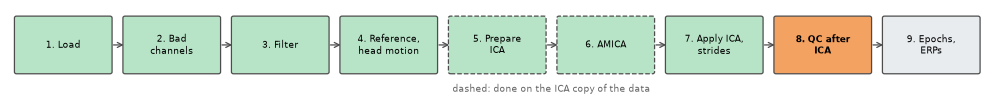

In [55]:
pipeline_map(8)

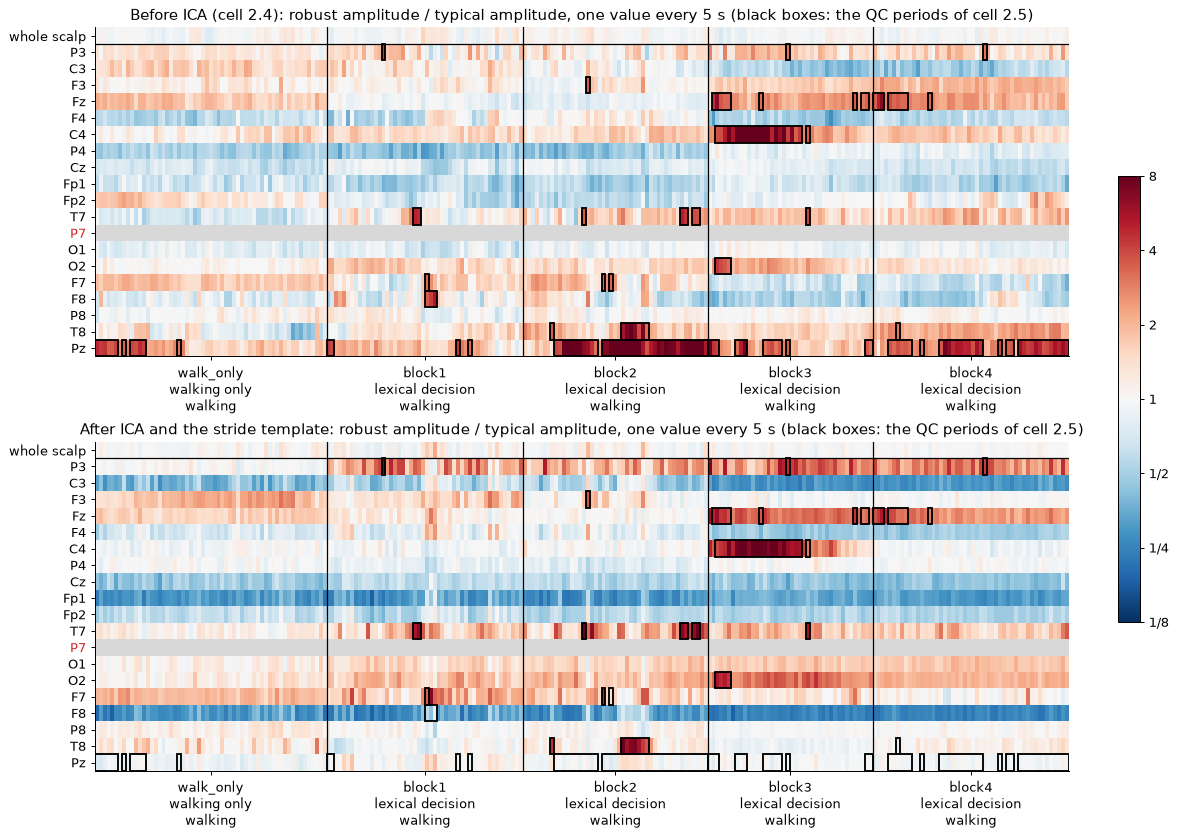

In [56]:
# ---- 8.1 The same 5-s windows, before and after ICA ---------------------------------------------------------------------------------
from matplotlib.patches import Rectangle                     # the boxes around the QC periods
quality_after, _ = window_quality(cleaned, usable)           # the same windows, channels and measure as cell 2.4
quality_after.loc[[ch for ch in BAD_CHANNELS if ch in quality_after.index]] = np.nan   # a bad channel kept the Pz reference: no value


def mark_qc(ax):
    """Draws a box around each QC period of cell 2.5 on a heatmap of plot_quality: on its channel, or on the row 'whole scalp'."""
    rows = ['whole scalp'] + eeg_channels
    for p in qc_table.itertuples():
        inside = np.flatnonzero((windows['recording'] == p.recording) & (windows['start'] >= p.onset - 1e-6)
                                & (windows['start'] < p.onset + p.duration - 1e-6))
        row = 0 if p.channels == 'all' else rows.index(p.channels)
        ax.add_patch(Rectangle((inside[0] - 0.5, row - 0.5), len(inside), 1, fill=False, ec='k', lw=1.5))


fig, axes = plt.subplots(2, 1, figsize=(13, 9.2), layout='constrained')
for ax, (label, table) in zip(axes, [('Before ICA (cell 2.4)', quality), ('After ICA and the stride template', quality_after)]):
    image = plot_quality(table, ax, f'{label}: robust amplitude / typical amplitude, one value every {QC_WINDOW_S:g} s (black boxes: '
                                    f'the QC periods of cell 2.5)')
    mark_qc(ax)
cbar = fig.colorbar(image, ax=axes, ticks=[-3, -2, -1, 0, 1, 2, 3], shrink=0.6)
cbar.ax.set_yticklabels(['1/8', '1/4', '1/2', '1', '2', '4', '8'])
plt.show()

In [57]:
# ---- 8.2 The decision: BAD_final_ for what stays unusable, and the data of steps 9 and 10 -------------------------------------------
def after_ica(p):
    """The value of a QC period after ICA, as `ratio` in cell 2.5: the largest of its windows, or the smallest for a lost contact."""
    inside = ((windows['recording'] == p.recording) & (windows['start'] >= p.onset - 1e-6)
              & (windows['start'] < p.onset + p.duration - 1e-6)).to_numpy()
    values = quality_after.loc['whole scalp' if p.channels == 'all' else p.channels, inside]
    return values.min() if p.description == 'QC_contact' else values.max()


qc_table['ratio after ICA'] = [after_ica(p) for p in qc_table.itertuples()]
still = np.where(qc_table['description'] == 'QC_contact', qc_table['ratio after ICA'] < FLAT_RATIO, qc_table['ratio after ICA'] > QC_RATIO)
qc_table['after ICA'] = np.where(still, 'still beyond the threshold', 'within the threshold, still suspicious')
final_bad = still & (qc_table['channels'] == 'all').to_numpy()   # the whole scalp, still unusable
qc_table['final'] = np.where(final_bad, 'BAD_final', 'QC only')
final = {name: raw.copy() for name, raw in cleaned.items()}  # the data of steps 9 and 10: the QC annotations stay
for p in qc_table[final_bad].itertuples():
    raw = final[p.recording]
    raw.annotations.append(onset=raw.first_time + p.onset, duration=p.duration,
                           description='BAD_final_' + p.description.removeprefix('QC_'))
print(f'{final_bad.sum()} of {len(qc_table)} QC periods become BAD_final_. Bad channels {final["task"].info["bads"]}: still marked, '
      f'not rebuilt.')
qc_table.round(2)

0 of 46 QC periods become BAD_final_. Bad channels ['P7']: still marked, not rebuilt.


,recording,part,onset,duration,description,channels,ratio,held out from ICA,ratio after ICA,after ICA,final
0,task,block3,497.55,110.0,QC_large_amplitude,C4,23.59,False,12.19,still beyond the threshold,QC only
1,task,block3,612.55,5.0,QC_large_amplitude,C4,3.49,False,2.91,"within the threshold, still suspicious",QC only
2,task,block2,331.93,5.0,QC_large_amplitude,F3,3.60,False,3.72,still beyond the threshold,QC only
3,task,block1,125.00,5.0,QC_large_amplitude,F7,3.27,False,3.40,still beyond the threshold,QC only
4,task,block2,351.93,5.0,QC_large_amplitude,F7,3.23,False,4.97,still beyond the threshold,QC only
5,task,block2,361.93,5.0,QC_large_amplitude,F7,3.37,False,1.34,"within the threshold, still suspicious",QC only
6,task,block1,125.00,15.0,QC_large_amplitude,F8,5.42,False,0.87,"within the threshold, still suspicious",QC only
7,task,block3,492.55,25.0,QC_large_amplitude,Fz,6.58,False,6.12,still beyond the threshold,QC only
8,task,block3,552.55,5.0,QC_large_amplitude,Fz,3.19,False,3.60,still beyond the threshold,QC only
9,task,block3,672.55,5.0,QC_large_amplitude,Fz,3.47,False,4.47,still beyond the threshold,QC only


**Look.** The two heatmaps have the same windows, rows and colours, and the black boxes are the QC periods of step 2. **Pz** changes the
most: its 20 QC periods, up to 24 times the typical amplitude before ICA, are all back within the threshold after it (at most 1.5 times),
because the component of the Pz sensor was removed. **C3**, **F8** and **Fp1** are now below the typical amplitude almost everywhere:
their own components (C3, F8) or the blink (Fp1) carried much of their signal. **C4** keeps its burst at the start of block 3 (12.2 times
the typical amplitude after cleaning): nothing in ICA or in the template is specific to these two minutes of one electrode, and step 9
drops the epochs that the burst makes too large. Fz, T7, T8 and P3 keep their periods, and some channels look louder than before (P3, O1,
O2, F7) because the typical amplitude of each window fell. No QC period covers the whole scalp, so no `BAD_final_` annotation is added:
the 46 QC annotations stay on the data, and no trial will be dropped because of them.

## 9. Epochs and ERPs, before and after cleaning

**What.** Cut one **epoch** per word, from 0.2 s before to 0.8 s after it, subtract its mean over the 200 ms before the word (the
**baseline**), and average the epochs of each condition into **ERPs**. We do it twice: on the data **before cleaning** (the recording with
only a 0.1–40 Hz band-pass and the average reference) and **after cleaning** (the head-movement regression, ICA and the stride template, then the same 0.1–40 Hz band). Comparing
the two shows what the preprocessing did to the ERPs.

**Which epochs.** `mne.Epochs` drops every epoch that touches a `BAD` annotation (the junctions of the blocks, the data gaps, and the
`BAD_final_` periods); the `QC_` annotations drop nothing, and the bad channels stay out (`raw.info['bads']`). Of the epochs left, we keep
the correct answers whose onset is confirmed by the tone of the word (`KEEP_CORRECT_ONLY` and `MAX_TONE_MS` in cell 0.3). Walking adds one
rule: an epoch whose peak-to-peak amplitude exceeds 300 µV on an electrode of the regions after cleaning is dropped (`REJECT_P2P_UV`, the
limit of the Brain Walk COSYNE analyses; mobile EEG studies use similar limits, for example ±150 µV in Patelaki et al., 2023). A shaken
electrode can be hundreds of times larger than an ERP, and averaging does not remove it. The same epochs are kept before and after
cleaning.

**How precise is each measure?** Next to each mean amplitude we compute its **standardized measurement error** (SME; Luck et al., 2021):
the standard deviation of the single-trial values divided by the square root of the number of trials, that is, the standard error of the
mean amplitude. A smaller SME after cleaning means a more precise ERP.

**Where and when.** Each component is the mean over a group of electrodes and a time window (`COMPONENTS` in cell 0.3). They come from
the Brain Walk group analyses, not from this participant:

| Component | Electrodes | Window | Source |
|---|---|---|---|
| P2 | F3, Fz, F4, C3, Cz, C4 | 140–220 ms | where the P2 of the group is clearest (cluster analysis) |
| N400 | C3, Cz, C4, P3, Pz, P4 | 300–500 ms | the region of the COSYNE abstract, and the usual N400 window (Kutas & Federmeier, 2011) |
| LPC (late positivity) | C3, Cz, C4, P3, Pz, P4 | 450–800 ms | the same region, and the late window of the COSYNE abstract |

The N400 and LPC region is symmetric on purpose: each condition is answered with its own hand, and averaging C3 with C4 and P3 with P4
cancels the motor potential of that hand before the tap.

**How.** `mne.events_from_annotations` gives one event per word; `mne.Epochs(raw, events, event_id, tmin, tmax, baseline, metadata)` cuts
the epochs (`reject_by_annotation=True` by default); `epochs[condition].average()` makes each ERP; `mne.viz.plot_compare_evokeds(evokeds,
picks=region, combine='mean')` draws them.

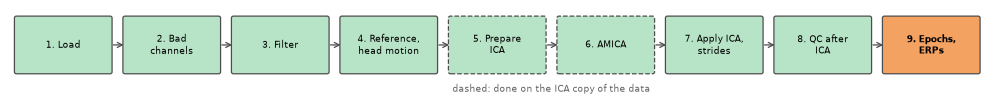

In [58]:
pipeline_map(9)

In [59]:
# ---- 9.1 One epoch per word, before and after cleaning ------------------------------------------------------------------------------
EVENT_ID = {'word/HF': 1, 'word/LF': 2, 'pseudoword': 3}     # the code of each condition in the events array
before = recordings['task'].copy().filter(*ERP_BAND, picks='eeg').set_eeg_reference('average')   # not cleaned: filter and reference only
after = final['task'].copy().filter(None, ERP_BAND[1], picks='eeg')   # cleaned; its 0.1 Hz high-pass dates from step 3, the 40 Hz is new
word_events, _ = mne.events_from_annotations(after, event_id=EVENT_ID)
assert (word_events[:, 2] == trials['condition'].map(EVENT_ID).to_numpy()).all()   # same words, same order as the trials table
metadata = trials[['block', 'trial_in_block', 'stimulus', 'condition', 'accuracy', 'response_time', 'marker_residual_ms']].reset_index(drop=True)
epochs = {label: mne.Epochs(data, word_events, EVENT_ID, tmin=TMIN, tmax=TMAX, baseline=BASELINE, metadata=metadata, preload=True)
          for label, data in [('before cleaning', before), ('after cleaning', after)]}   # the epochs touching a BAD annotation are dropped
outside_bad = epochs['after cleaning'].metadata['condition'].value_counts()
dropped = pd.Series([reason for log in epochs['after cleaning'].drop_log for reason in log]).value_counts().to_dict()
both = np.intersect1d(epochs['before cleaning'].selection, epochs['after cleaning'].selection)   # (BAD_final_ is only on the cleaned data)
epochs = {label: ep[np.isin(ep.selection, both)] for label, ep in epochs.items()}   # the same epochs in both
confirmed = (epochs['after cleaning'].metadata['marker_residual_ms'].abs() <= MAX_TONE_MS).to_numpy()   # its own tone, close to the onset
correct = (epochs['after cleaning'].metadata['accuracy'] == 1).to_numpy() if KEEP_CORRECT_ONLY else np.ones(len(confirmed), bool)
region = [ch for ch in dict.fromkeys(ch for c in COMPONENTS.values() for ch in c['region']) if ch not in BAD_CHANNELS]
too_large = np.ptp(epochs['after cleaning'].get_data(picks=region), axis=-1).max(axis=1) > REJECT_P2P_UV * 1e-6   # after cleaning
answered = epochs['after cleaning'].metadata[confirmed & correct]['condition'].value_counts()
epochs = {label: ep[confirmed & correct & ~too_large] for label, ep in epochs.items()}
n_too_large = int((confirmed & correct & too_large).sum())
print(f'Dropped because they touch a BAD annotation: {dropped}')
print(f'Dropped because they exceed {REJECT_P2P_UV:g} µV peak to peak at {", ".join(region)} after cleaning: {n_too_large} of the '
      f'{int((confirmed & correct).sum())} correct answers with a confirmed onset')
counts = pd.DataFrame({'words': trials['condition'].value_counts(), 'not in a BAD annotation': outside_bad,
                       'correct, onset confirmed': answered,
                       f'kept (at most {REJECT_P2P_UV:g} µV)': epochs['after cleaning'].metadata['condition'].value_counts()}).loc[list(CONDITIONS)]
counts.loc['total'] = counts.sum()
counts

Dropped because they touch a BAD annotation: {'BAD_gap': 8}
Dropped because they exceed 300 µV peak to peak at F3, Fz, F4, C3, Cz, C4, P3, Pz, P4 after cleaning: 26 of the 307 correct answers with a confirmed onset


,words,not in a BAD annotation,"correct, onset confirmed",kept (at most 300 µV)
condition,,,,
word/HF,93,90,85,76
word/LF,99,98,71,66
pseudoword,189,185,151,139
total,381,373,307,281


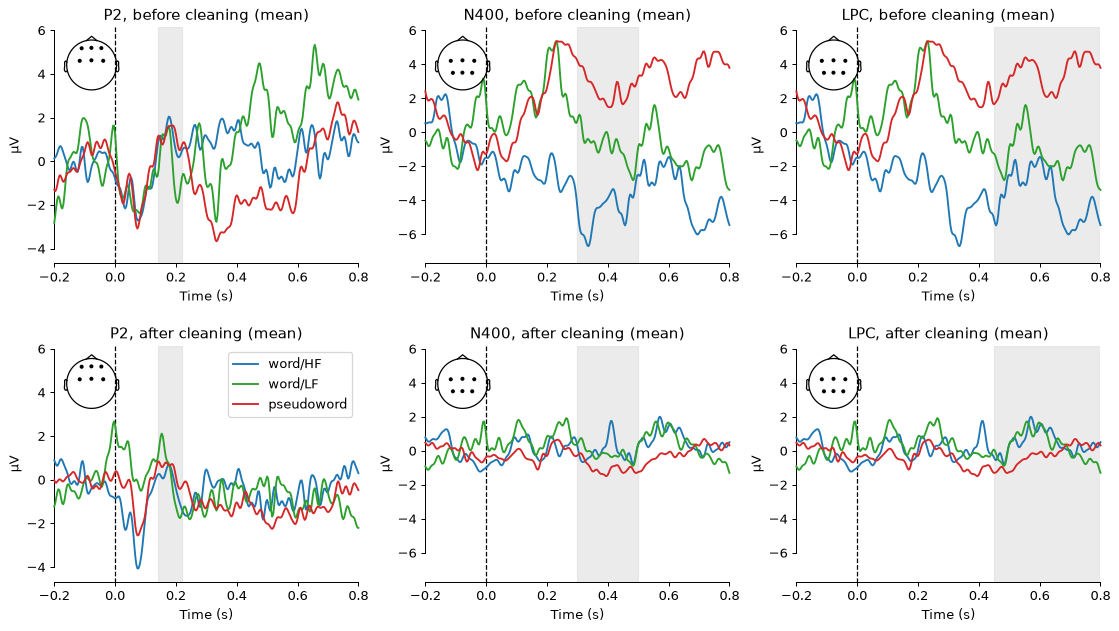

SME (µV), median of the three conditions, before → after cleaning: P2 2.54 → 0.69; N400 2.11 → 1.06; LPC 2.50 → 1.26


P2                           N400                 \
           before cleaning after cleaning before cleaning after cleaning   
word/HF               1.04          -0.05           -4.60          -0.02   
word/LF              -0.01           0.17           -0.87          -0.16   
pseudoword            1.14           0.42            2.54          -1.01   

                       LPC                 
           before cleaning after cleaning  
word/HF              -3.74           0.47  
word/LF              -1.31           0.27  
pseudoword            3.51          -0.24

In [60]:
# ---- 9.2 The P2, the N400 and the LPC, before and after cleaning, and how precise each measure is ------------------------------------
erps = {label: {name: ep[name].average() for name in CONDITIONS} for label, ep in epochs.items()}
fig, axes = plt.subplots(2, len(COMPONENTS), figsize=(15, 8))
amplitude, sme = {}, {}
for col, (component, c) in enumerate(COMPONENTS.items()):
    region = [ch for ch in c['region'] if ch not in BAD_CHANNELS]   # the electrodes that were recorded
    waves = [ev.copy().pick(region).data.mean(axis=0) * 1e6 for row in erps.values() for ev in row.values()]
    ylim = (1.15 * min(w.min() for w in waves), 1.15 * max(w.max() for w in waves))   # the same scale before and after
    for row, (label, evokeds) in enumerate(erps.items()):
        mne.viz.plot_compare_evokeds(evokeds, picks=region, combine='mean', colors=CONDITIONS, axes=axes[row, col], ylim=dict(eeg=ylim),
                                     title=f'{component}, {label}', legend='upper right' if (row, col) == (1, 0) else False,
                                     show_sensors='upper left', show=False)
        axes[row, col].axvspan(*c['window'], color='0.85', alpha=0.5, zorder=0)   # the window of the component
        # one value per trial, the mean over the region and the window: their mean is the ERP measure, their standard error its SME
        values = epochs[label].copy().pick(region).crop(*c['window']).get_data().mean(axis=(1, 2)) * 1e6
        trials_of = {name: values[(epochs[label].metadata['condition'] == name).to_numpy()] for name in CONDITIONS}
        amplitude[(component, label)] = {name: v.mean() for name, v in trials_of.items()}
        sme[(component, label)] = {name: v.std(ddof=1) / np.sqrt(len(v)) for name, v in trials_of.items()}
fig.subplots_adjust(hspace=0.35, wspace=0.22)
plt.show()
amplitude, sme = pd.DataFrame(amplitude), pd.DataFrame(sme)  # µV: conditions x (component, data)
print('SME (µV), median of the three conditions, before → after cleaning: '
      + '; '.join(f'{component} {sme[(component, "before cleaning")].median():.2f} → {sme[(component, "after cleaning")].median():.2f}'
                  for component in COMPONENTS))
amplitude.round(2)

**Look.** 8 epochs touch a data gap and are dropped, and 26 of the 307 correct answers with a confirmed onset exceed 300 µV on an electrode
of the regions after cleaning: 281 remain (76 HF words, 66 LF words, 139 pseudowords), the same epochs before and after cleaning. C4 is a
good channel now, so the N400 and LPC region is symmetric again (C3 and C4, P3 and P4).

Before cleaning (top), the three conditions separate from about 200 ms and stay apart: in the N400 window, −4.6 µV for the HF words and
+2.5 µV for the pseudowords. After cleaning (bottom), they overlap in the N400 and LPC windows (from −1.0 to +0.5 µV), and the SME of each
mean amplitude is half what it was or less: 2.5 → 0.7 µV for the P2, 2.1 → 1.1 µV for the N400, 2.5 → 1.3 µV for the LPC. The separation
before cleaning came from the slow artifacts of single electrodes (Pz and C3, cell 6.8), not from the brain. With an SME near 1 µV,
differences of about 1 µV between the conditions of one participant are within the noise: the effects are measured over the group. After
cleaning, a negative wave near 75 ms, already there before cleaning, is clearest for the HF words (−4.1 µV), and the P2 window is slightly
positive for the LF words and the pseudowords.

Cleaning is not free. A removed component takes with it the part of the ERP that looks like it: the blink component part of a frontal P2,
a component of one electrode what is particular to that electrode. This is why the rule removes few components, and why item 3 of "Try it
yourself" compares the ERPs with and without the components of one electrode.

## 10. Save the results, and summary

In [61]:
# ---- 10.1 Save the clean data with their QC information, the epochs and a summary ---------------------------------------------------
RESULTS_DIR = DATA_DIR / 'mes_resultats'                     # "my results": the folder notebook 01 also writes to
RESULTS_DIR.mkdir(exist_ok=True)
epochs['after cleaning'].save(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking-epo.fif', overwrite=True)   # the cleaned epochs (9.1)
for name, raw in final.items():                              # the continuous data, with raw.info['bads'] and every annotation
    raw.save(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_{name}_eeg.fif', overwrite=True)
qc_summary = qc_table.assign(participant=SUBJECT, bad_channels=' '.join(BAD_CHANNELS))   # a readable copy; the FIF files are the reference
qc_summary = qc_summary[['participant', 'recording', 'part', 'bad_channels', 'onset', 'duration', 'description', 'channels', 'ratio',
                         'held out from ICA', 'ratio after ICA', 'after ICA', 'final']]
qc_summary.to_csv(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_qc.csv', index=False)
evidence.assign(participant=SUBJECT).to_csv(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_ica_components.csv')   # the evidence of cell 6.7
summary = {
    'participant': SUBJECT,
    'bad channels (in info["bads"], not rebuilt)': BAD_CHANNELS,
    'QC periods / left out of ICA training / BAD_final': f'{len(qc_table)} / {int(qc_table["held out from ICA"].sum())} / '
                                                         f'{int((qc_table["final"] == "BAD_final").sum())}',
    'ICA components': int(ica.n_components_),
    'components removed': [f'ICA{i:03d}' for i in ica.exclude],
    'components to review (kept)': list(evidence.index[evidence['decision'] == 'review']),
    'head movement: % of the held-out variance explained (applied)': {name: f'{row.held_out_variance_explained_pct:g} ({"yes" if row.applied else "no"})'
                                                                      for name, row in motion_table.iterrows()},
    'AMICA: % of its samples rejected while learning': round(100 * (1 - float(kept_samples.mean())), 1),
    'stride template: average step, median of the good channels (µV)': f'{size_template["after ICA"].median():.1f} → '
                                                                         f'{size_template["after the template"].median():.1f}',
    f'epochs dropped above {REJECT_P2P_UV:g} µV': n_too_large,
    'epochs kept (HF, LF, pseudoword)': [len(epochs['after cleaning'][name]) for name in CONDITIONS],
    **{f'{component}, mean amplitude after cleaning (µV)': {name: round(float(amplitude.loc[name, (component, 'after cleaning')]), 2)
                                                           for name in CONDITIONS} for component in COMPONENTS},
    'SME after cleaning, median of the conditions (µV)': {component: round(float(sme[(component, 'after cleaning')].median()), 2)
                                                           for component in COMPONENTS},
}
(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved in', RESULTS_DIR)
pd.Series(summary, name=SUBJECT).to_frame()

Saved in tasks\brainwalk\mes_resultats


,P010
participant,P010
"bad channels (in info[""bads""], not rebuilt)",[P7]
QC periods / left out of ICA training / BAD_final,46 / 0 / 0
ICA components,17
components removed,"[ICA000, ICA004, ICA011, ICA012, ICA014]"
components to review (kept),[]
head movement: % of the held-out variance explained (applied),"{'walk_only': '8.7 (yes)', 'block1': '0.8 (no)..."
AMICA: % of its samples rejected while learning,6.4
"stride template: average step, median of the good channels (µV)",3.4 → 0.7
epochs dropped above 300 µV,26


In [62]:
# ---- 10.2 Check the QC information at the end of the preprocessing ------------------------------------------------------------------
def annotation_set(raw, prefix):
    """The annotations of raw whose description starts with prefix: (description, onset in the recording, duration, channels)."""
    return {(a['description'], round(a['onset'] - raw.first_time, 2), round(a['duration'], 2), tuple(a.get('ch_names', ())))
            for a in raw.annotations if a['description'].startswith(prefix)}


reloaded = {name: mne.io.read_raw_fif(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_{name}_eeg.fif') for name in final}
bad_final = [(a['onset'], a['onset'] + a['duration']) for a in final['task'].annotations if a['description'].startswith('BAD_final_')]
epoch_starts = epochs['after cleaning'].events[:, 0] / sfreq + TMIN      # in the time base of the annotations
checks = {
    'the bad channels are still in info["bads"] (data, epochs, saved files)':
        all(r.info['bads'] == BAD_CHANNELS for r in [*final.values(), *reloaded.values(), *epochs.values()]),
    'the QC_ annotations rejected no epoch': not any(reason.startswith('QC_') for ep in epochs.values() for log in ep.drop_log for reason in log),
    'BAD_ICA_ exists only on the ICA copy': (any(annotation_set(r, 'BAD_ICA_') for r in ica_copy.values()) == bool(qc_table['held out from ICA'].any())
                                             and not any(annotation_set(r, 'BAD_ICA_') for r in [*analysis.values(), *cleaned.values(), *final.values()])),
    'AMICA learned without the BAD_ICA_ periods': not any(start < end and start + 2.0 > begin for start in pieces.events[:, 0] / sfreq
                                                          for begin, end in held_periods),
    'ICA was applied to every sample': all(cleaned[name].n_times == analysis[name].n_times for name in final),
    'the QC_ annotations survived ICA': all(annotation_set(cleaned[name], 'QC_') == annotation_set(analysis[name], 'QC_') for name in final),
    'one QC_ annotation per row of the QC table': sum(len(annotation_set(final[name], 'QC_')) for name in final) == len(qc_table),
    'BAD_final_ only where the table says BAD_final': (sum(len(annotation_set(final[name], 'BAD_final_')) for name in final)
                                                       == (qc_table['final'] == 'BAD_final').sum()),
    'no kept epoch overlaps a BAD_final_ period': not any(start < end and start + TMAX - TMIN > begin
                                                          for start in epoch_starts for begin, end in bad_final),
    'the saved files keep every annotation': all(annotation_set(reloaded[name], '') == annotation_set(final[name], '') for name in final),
    'the ICA evidence table is saved, and its "remove" rows are the removed components':
        (pd.read_csv(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_ica_components.csv', index_col='component')['decision'].tolist()
         == evidence['decision'].tolist() and list(np.flatnonzero(evidence['decision'] == 'remove')) == sorted(ica.exclude)),
    'the head-movement regression left the bad channels unchanged': all(np.array_equal(before_motion[name].get_data(picks=BAD_CHANNELS),
                                                                                      analysis[name].get_data(picks=BAD_CHANNELS))
                                                                       for name in final) if BAD_CHANNELS else True,
}
for check, ok in checks.items():
    print('✓' if ok else '✗', check)

✓ the bad channels are still in info["bads"] (data, epochs, saved files)
✓ the QC_ annotations rejected no epoch
✓ BAD_ICA_ exists only on the ICA copy
✓ AMICA learned without the BAD_ICA_ periods
✓ ICA was applied to every sample
✓ the QC_ annotations survived ICA
✓ one QC_ annotation per row of the QC table
✓ BAD_final_ only where the table says BAD_final
✓ no kept epoch overlaps a BAD_final_ period
✓ the saved files keep every annotation
✓ the ICA evidence table is saved, and its "remove" rows are the removed components
✓ the head-movement regression left the bad channels unchanged


### The pipeline in one table

| Step | What it did here | Main risk if done badly |
|---|---|---|
| 1. Load | 5 recordings cut at their triggers (walking without the task, 4 blocks), the 4 blocks joined | wrong events or wrong channel types |
| 2. Bad channels | flat channels on the signal as recorded; noisy channels judged in the 5-s windows of all the walking recordings, Pz included, after a temporary median reference: above 3 × the typical amplitude in more than half of them, the rule run twice; `raw.info['bads']` until the end; suspicious periods kept as `QC_` annotations | calling bad a channel that was large only while the head moved, or keeping one that spreads its noise to all others at step 4 |
| 3. Filter | 0.1–100 Hz band-pass | a high-pass that is too high distorts slow ERPs |
| 4. Reference, head movement | average of the good channels (the bad ones left out, unchanged); then, in each recording, every good channel regressed on the head acceleration (now and up to 200 ms before, one regression per minute), applied where it predicts held-out data | removing brain activity locked to the steps; a regression that learns chance (checked on held-out data) |
| 5. Prepare ICA | a copy from 2 Hz for AMICA and a 1–100 Hz copy for ICLabel; `BAD_ICA_` only for lost contacts and whole-scalp periods | ICA spoilt by slow drifts |
| 6. AMICA | fitted on 2-s pieces of the copy from 2 Hz, with its own rejection of the samples it cannot explain; eye, muscle and large single-electrode components removed by the rule of the Brain Walk analyses, the decision checked on a copy | removing brain components |
| 7. Apply ICA, then the stride template | the components removed from every sample of the 0.1–100 Hz analysis data; QC annotations kept; then, in each channel, each stride minus the average of the 20 strides around it, scaled to it (Gwin et al., 2010) | removing brain activity locked to the stride |
| 8. QC after ICA | the same 5-s windows after ICA; whole-scalp periods still unusable marked `BAD_final_`; no channel rebuilt | calling a period good because ICA made it smaller |
| 9. Epochs and ERPs | −0.2 to 0.8 s around each word, baseline −0.2 to 0 s; the epochs touching a `BAD` annotation or above 300 µV on an electrode of the regions dropped; correct answers with a confirmed onset; P2, N400 and LPC with their SME, before and after cleaning | comparing ERPs that were not filtered, referenced or selected the same way |

### What this pipeline does not do

It cannot clean with noise electrodes, which the DSI-24 does not have (dual-layer EEG, iCanClean: Gonsisko et al., 2023). It does not correct the eyes with wavelets, does not repair
channels locally in each epoch, and does not analyse the EEG along the gait cycle. The full Brain Walk pipeline (notebook
`01_preprocessing_lexicaldecision.ipynb`) does some of these.

### Try it yourself

1. In cell 0.3, set `NOISY_SHARE = 0.2`, the strict end of BeMoBIL's range, and rerun from step 2. Which channels become bad, and what
   happens to the regions of step 9?
2. Set `ACCEL_MIN_GAIN = 1.0`, so that the regression is never applied, and rerun from cell 4.4. Compare cell 4.5, the components of step
   6 and the SME of cell 9.2.
3. Set `CHANNEL_VAR = 100`, so that no component of one electrode is removed, and rerun from cell 6.7. How do the ERPs and their SME change?
4. Set `REJECT_P2P_UV = 1e6` (no amplitude limit) and rerun step 9. How many epochs come back, and what happens to the SME?
5. Compare with the seated notebook (`00_preprocessing_teaching_seated.ipynb`), same participant: the bad channels, the components
   removed, the SME.
6. Set `AMICA_MAX_ITER = 2000` and `AMICA_DECIM = 1`, the settings of Klug et al. (2024), and compare the components of cells 6.3 and 6.7
   (about 20 minutes).

### References

- Ablin, P., Cardoso, J.-F., & Gramfort, A. (2018). Faster independent component analysis by preconditioning with Hessian approximations.
  *IEEE Transactions on Signal Processing, 66*(15), 4040–4049.
- Alday, P. M. (2019). How much baseline correction do we need in ERP research? Extended GLM model can replace baseline correction while
  lifting its limits. *Psychophysiology, 56*(12), e13451.
- Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K.-M., & Robbins, K. A. (2015). The PREP pipeline: standardized preprocessing for large-scale EEG
  analysis. *Frontiers in Neuroinformatics, 9*, 16.
- Delorme, A., Palmer, J., Onton, J., Oostenveld, R., & Makeig, S. (2012). Independent EEG sources are dipolar. *PLoS ONE, 7*(2),
  e30135.
- di Fronso, S., Fiedler, P., Tamburro, G., Haueisen, J., Bertollo, M., & Comani, S. (2019). Dry EEG in sports sciences: A fast and reliable tool
  to assess individual alpha peak frequency changes induced by physical effort. *Frontiers in Neuroscience, 13*, 982.
- Downey, R. J., & Ferris, D. P. (2023). iCanClean removes motion, muscle, eye, and line-noise artifacts from phantom EEG. *Sensors,
  23*(19), 8214.
- Esmaeili, S., Abdelhedi, H., Mantilla Ramos, Y. J., Pascarella, A., & Jerbi, K. (2026). *jamica: native Python implementation of AMICA
  for MNE-Python* (version 0.3.0) [Computer software]. https://doi.org/10.5281/zenodo.21817485
- Fiedler, P., Fonseca, C., Supriyanto, E., Zanow, F., & Haueisen, J. (2022). A high-density 256-channel cap for dry electroencephalography. *Human
  Brain Mapping, 43*(4), 1295–1308.
- Fló, A., Gennari, G., Benjamin, L., & Dehaene-Lambertz, G. (2022). Automated pipeline for infants continuous EEG (APICE): A flexible pipeline for
  developmental cognitive studies. *Developmental Cognitive Neuroscience, 54*, 101077.
- Gonsisko, C. B., Ferris, D. P., & Downey, R. J. (2023). iCanClean improves independent component analysis of mobile brain imaging with EEG.
  *Sensors, 23*(2), 928.
- Gorjan, D., Gramann, K., De Pauw, K., & Marusic, U. (2022). Removal of movement-induced EEG artifacts: current state of the art and
  guidelines. *Journal of Neural Engineering, 19*(1), 011004.
- Gramfort, A., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience, 7*, 267.
- Gwin, J. T., Gramann, K., Makeig, S., & Ferris, D. P. (2010). Removal of movement artifact from high-density EEG recorded during walking
  and running. *Journal of Neurophysiology, 103*(6), 3526–3534.
- Heijs, J. J. A., Havelaar, R. J., Fiedler, P., van Wezel, R. J. A., & Heida, T. (2021). Validation of soft multipin dry EEG electrodes. *Sensors,
  21*(20), 6827.
- Hyvärinen, A., & Oja, E. (2000). Independent component analysis: algorithms and applications. *Neural Networks, 13*(4–5), 411–430.
- Jas, M., Engemann, D. A., Bekhti, Y., Raimondo, F., & Gramfort, A. (2017). Autoreject: Automated artifact rejection for MEG and EEG data.
  *NeuroImage, 159*, 417–429.
- Kam, J. W. Y., Griffin, S., Shen, A., Patel, S., Hinrichs, H., Heinze, H.-J., Deouell, L. Y., & Knight, R. T. (2019). Systematic comparison between a
  wireless EEG system with dry electrodes and a wired EEG system with wet electrodes. *NeuroImage, 184*, 119–129.
- Keren, A. S., Yuval-Greenberg, S., & Deouell, L. Y. (2010). Saccadic spike potentials in gamma-band EEG: Characterization, detection
  and suppression. *NeuroImage, 49*(3), 2248–2263.
- Kilicarslan, A., & Contreras-Vidal, J. L. (2019). Characterization and real-time removal of motion artifacts from EEG signals. *Journal
  of Neural Engineering, 16*(5), 056027.
- Kim, H., Luo, J., Chu, S., Cannard, C., Hoffmann, S., & Miyakoshi, M. (2023). ICA's bug: How ghost ICs emerge from effective rank deficiency caused
  by EEG electrode interpolation and incorrect re-referencing. *Frontiers in Signal Processing, 3*, 1064138.
- Kline, J. E., Huang, H. J., Snyder, K. L., & Ferris, D. P. (2015). Isolating gait-related movement artifacts in electroencephalography during human
  walking. *Journal of Neural Engineering, 12*(4), 046022.
- Klug, M., & Gramann, K. (2021). Identifying key factors for improving ICA-based decomposition of EEG data in mobile and stationary
  experiments. *European Journal of Neuroscience, 54*(12), 8406–8420.
- Klug, M., Berg, T., & Gramann, K. (2024). Optimizing EEG ICA decomposition with data cleaning in stationary and mobile experiments.
  *Scientific Reports, 14*, 14119.
- Klug, M., Jeung, S., Wunderlich, A., Gehrke, L., Protzak, J., Djebbara, Z., Argubi-Wollesen, A., Wollesen, B., & Gramann, K. (2022). The BeMoBIL
  pipeline for automated analyses of multimodal mobile brain and body imaging data. *bioRxiv*. https://doi.org/10.1101/2022.09.29.510051
- Kumaravel, V. P., Buiatti, M., Parise, E., & Farella, E. (2022a). Adaptable and robust EEG bad channel detection using local outlier factor (LOF).
  *Sensors, 22*(19), 7314.
- Kumaravel, V. P., Farella, E., Parise, E., & Buiatti, M. (2022b). NEAR: An artifact removal pipeline for human newborn EEG data. *Developmental
  Cognitive Neuroscience, 54*, 101068.
- Kutas, M., & Federmeier, K. D. (2011). Thirty years and counting: finding meaning in the N400 component of the event-related brain
  potential (ERP). *Annual Review of Psychology, 62*, 621–647.
- Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute
  deviation around the median. *Journal of Experimental Social Psychology, 49*(4), 764–766.
- Li, A., Feitelberg, J., Saini, A. P., Höchenberger, R., & Scheltienne, M. (2022). MNE-ICALabel: Automatically annotating ICA components
  with ICLabel in Python. *Journal of Open Source Software, 7*(76), 4484.
- Luck, S. J. (2014). *An introduction to the event-related potential technique* (2nd ed.). MIT Press.
- Luck, S. J., Stewart, A. X., Simmons, A. M., & Rhemtulla, M. (2021). Standardized measurement error: A universal metric of data quality
  for averaged event-related potentials. *Psychophysiology, 58*(6), e13793.
- Makeig, S., Bell, A. J., Jung, T.-P., & Sejnowski, T. J. (1996). Independent component analysis of electroencephalographic data.
  *Advances in Neural Information Processing Systems, 8*, 145–151.
- Ng, C. R., Fiedler, P., Kuhlmann, L., Liley, D., Vasconcelos, B., Fonseca, C., Tamburro, G., Comani, S., Lui, T. K.-Y., Tse, C.-Y., Warsito, I. F.,
  Supriyanto, E., & Haueisen, J. (2022). Multi-center evaluation of gel-based and dry multipin EEG caps. *Sensors, 22*(20), 8079.
- Oliveira, A. S., Schlink, B. R., Hairston, W. D., König, P., & Ferris, D. P. (2016). Proposing metrics for benchmarking novel EEG technologies
  towards real-world measurements. *Frontiers in Human Neuroscience, 10*, 188.
- Oliveira, A. S., Schlink, B. R., Hairston, W. D., König, P., & Ferris, D. P. (2017). A channel rejection method for attenuating motion-related
  artifacts in EEG recordings during walking. *Frontiers in Neuroscience, 11*, 225.
- Palmer, J. A., Kreutz-Delgado, K., & Makeig, S. (2011). *AMICA: An adaptive mixture of independent component analyzers with shared
  components* [Technical report]. Swartz Center for Computational Neuroscience, University of California San Diego.
- Patelaki, E., Foxe, J. J., Mazurek, K. A., & Freedman, E. G. (2023). Young adults who improve performance during dual-task walking show
  more flexible reallocation of cognitive resources: a mobile brain-body imaging (MoBI) study. *Cerebral Cortex, 33*(6), 2573–2592.
- Pernet, C. R., Garrido, M., Gramfort, A., Maurits, N., Michel, C., Pang, E., Salmelin, R., Schoffelen, J. M., Valdes-Sosa, P. A., & Puce, A. (2018).
  Best practices in data analysis and sharing in neuroimaging using MEEG. *OSF Preprints*. https://doi.org/10.31219/osf.io/a8dhx
- Pernet, C. R., et al. (2019). EEG-BIDS, an extension to the brain imaging data structure for electroencephalography. *Scientific Data,
  6*, 103.
- Perrin, F., Pernier, J., Bertrand, O., & Echallier, J. F. (1989). Spherical splines for scalp potential and current density mapping.
  *Electroencephalography and Clinical Neurophysiology, 72*(2), 184–187.
- Pion-Tonachini, L., Kreutz-Delgado, K., & Makeig, S. (2019). ICLabel: An automated electroencephalographic independent component
  classifier, dataset, and website. *NeuroImage, 198*, 181–197.
- PyPREP developers. (n.d.). *PyPREP documentation*. https://pyprep.readthedocs.io
- Tanner, D., Morgan-Short, K., & Luck, S. J. (2015). How inappropriate high-pass filters can produce artifactual effects and incorrect
  conclusions in ERP studies of language and cognition. *Psychophysiology, 52*(8), 997–1009.
- Vergara-Martínez, M., Perea, M., Gómez, P., & Swaab, T. Y. (2013). ERP correlates of letter identity and letter position are modulated
  by lexical frequency. *Brain and Language, 125*(1), 11–27.
- Wearable Sensing. (2023). *DSI-24 user manual* (V1.2023). https://wearablesensing.com/dsi-24/
- Widmann, A., Schröger, E., & Maess, B. (2015). Digital filter design for electrophysiological data – a practical approach. *Journal of
  Neuroscience Methods, 250*, 34–46.
- Winkler, I., Debener, S., Müller, K.-R., & Tangermann, M. (2015). On the influence of high-pass filtering on ICA-based artifact reduction
  in EEG-ERP. *37th Annual International Conference of the IEEE EMBS*, 4101–4105.
- Zhang, G., Garrett, D. R., & Luck, S. J. (2024). Optimal filters for ERP research II: Recommended settings for seven common ERP components.
  *Psychophysiology, 61*(6), e14530.